In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from visualization import (
    plot_cost_function_with_minima, 
    plot_ploidy_optimization,
    plot_ploidy_comparison,  # Add this
    print_overlap_matrix, 
    plot_overlap_matrix_figure,
    plot_uniformity_histograms_nice
)
from copy_number import (
    make_unif_dict, 
    compute_read_counts_relative_to_normal,
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)

import time

In [2]:
numb = "57"
tumor = "t"+numb

In [3]:
bincounts = pd.read_csv(f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt", sep = "\t")
bincounts_no_WGS = pd.read_csv(f"../data/{tumor}/{tumor}.bincounts_without_WGS_segmentation.txt", sep="\t")
cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values
#normal_cells = pd.read_csv(f"../data/{tumor}/normal_cells.txt", header=None, sep="\t")[0].values

In [4]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t")
B_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_B_equi_bins.txt", sep="\t")
C_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_C_WGS_with_broken_cells.txt", sep="\t")

In [5]:
A_df.head()

,cell,population,normal_population
0,AAAACCAACTTTTGACG,A111,False
1,AAAACCACTGGCCTTAC,A111,False
2,AAAACCGAAATCGGTAT,A111,False
3,AAAATGGTTACTGTTCT,A111,False
4,AAAGCAATACCGCGATG,A111,False


In [6]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }


A111
A112
A1211
A1212
A1221
A1222
A2


In [7]:
C_dict = {}
for cluster in C_df['population'].unique():
    print(cluster)
    cells_in_cluster = C_df[C_df['population'] == cluster]['cell'].tolist()
    C_dict[cluster] = {
        'cells': cells_in_cluster
    }

C111111
C111112
C1111211
C1111212
C111122
C1112
C112
C121
C122
C2111
C21121
C21122
C2121
C21221
C2122211
C21222121
C21222122
C212222
C2211
C2212
C2221
C222211
C222212
C22222


In [8]:
B_dict = {}
for cluster in B_df['population'].unique():
    print(cluster)
    cells_in_cluster = B_df[B_df['population'] == cluster]['cell'].tolist()
    B_dict[cluster] = {
        'cells': cells_in_cluster
    }

B111
B112
B1211
B1212
B1221
B122211
B122212
B12222
B2


In [9]:
overlap_df = print_overlap_matrix(A_dict, B_dict, name1="WGS bins - ", name2="equi-partitioned bins -")


Overlap Matrix (WGS bins -  rows vs equi-partitioned bins - cols):
Pop         B111    B112   B1211   B1212   B1221 B122211 B122212  B12222      B2
A111         222       1       0       0       0       0       0       0       1
A112           1     143       0       0       0       0       0       0       0
A1211          0       0       0       0     161      62      26       1       0
A1212          0       0       2       0       0       3      15      33       0
A1221          0       0      49       0       1       2       0       1       1
A1222          0       0       1      80       1       0       1       0       0
A2             0       1       2       0       0       0       0       0    1722


In [10]:
new_order = []
for col in overlap_df.columns:
    #Find the index of the maximum value in the column
    max_index = overlap_df[col].idxmax()
    if max_index not in new_order:
        new_order.append(max_index)

for row in overlap_df.index:
    if row not in new_order:
        new_order.append(row)
new_order_dict = {k: A_dict[k] for k in new_order}
    


Overlap Matrix (A rows vs B cols):
Pop         B111    B112   B1211   B1212   B1221 B122211 B122212  B12222      B2
A111         222       1       0       0       0       0       0       0       1
A112           1     143       0       0       0       0       0       0       0
A1211          0       0       0       0     161      62      26       1       0
A1212          0       0       2       0       0       3      15      33       0
A1221          0       0      49       0       1       2       0       1       1
A1222          0       0       1      80       1       0       1       0       0
A2             0       1       2       0       0       0       0       0    1722


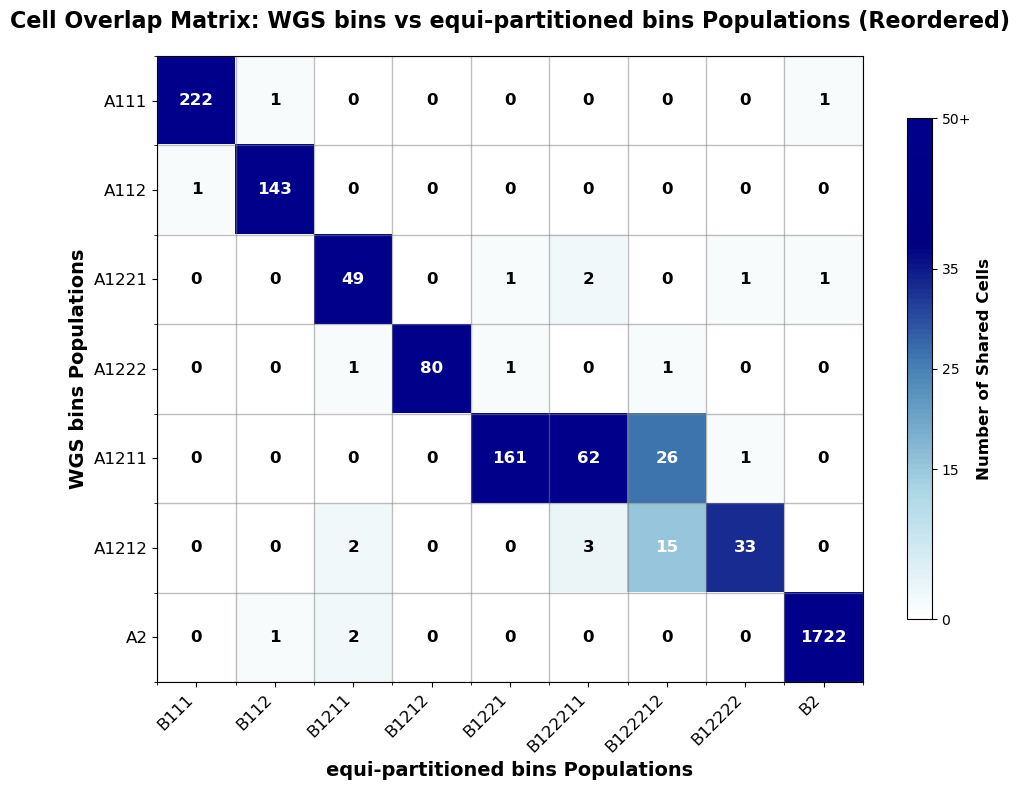

In [11]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict, name1="WGS bins", name2="equi-partitioned bins")

In [12]:
# Prepare the data - create the data DataFrame with segment info
data = bincounts[["chrom","abstart", "abend"]].copy()
data_no_WGS = bincounts_no_WGS[["chrom","abstart", "abend"]].copy()
for cell in cells:
    if cell in bincounts.columns:
        data[cell] = bincounts[cell].values
        data_no_WGS[cell] = bincounts_no_WGS[cell].values
data["lengths"] = data["abend"] - data["abstart"]
data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]

# Get just the cell count data for analysis
all_data = data[cells].copy()
all_data_no_WGS = data_no_WGS[cells].copy()

/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_17206/166721051.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[cell] = bincounts[cell].values
/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_17206/166721051.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data_no_WGS[cell] = bincounts_no_WGS[cell].values
/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_17206/166721051.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many ti

In [13]:
# Identify normal populations and compute ratios for both A and B populations
print("=== Population Set A Analysis ===")
avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)

print("\n=== Population Set B Analysis ===")
avg_counts_B, ratios_B, normal_B = compute_average_segment_counts(all_data_no_WGS, B_dict, data_no_WGS)
relative_counts_B = compute_read_counts_relative_to_normal(all_data_no_WGS, B_dict, normal_B)
print(f"\nNormal population A: {normal_A}")
print(f"Normal population B: {normal_B}")

=== Population Set A Analysis ===
Normal population identified as: A2
Mean read count ratio for population A111 relative to normal (A2): 1.19
Mean read count ratio for population A112 relative to normal (A2): 1.14
Mean read count ratio for population A1211 relative to normal (A2): 1.27
Mean read count ratio for population A1212 relative to normal (A2): 1.27
Mean read count ratio for population A1221 relative to normal (A2): 1.34
Mean read count ratio for population A1222 relative to normal (A2): 1.22
Mean read count ratio for population A2 relative to normal (A2): 1.00

=== Population Set B Analysis ===
Normal population identified as: B2
Mean read count ratio for population B111 relative to normal (B2): 1.18
Mean read count ratio for population B112 relative to normal (B2): 1.13
Mean read count ratio for population B1211 relative to normal (B2): 1.27
Mean read count ratio for population B1212 relative to normal (B2): 1.23
Mean read count ratio for population B1221 relative to normal (

In [14]:
#Add normal to the A_df population assignments
A_df["normal_population"] = (A_df['population'] == normal_A)

In [15]:
A_df.to_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t", index = False)

In [16]:
data_lengths = data["abend"] - data["abstart"]

Computing uniformity data using make_unif_dict...


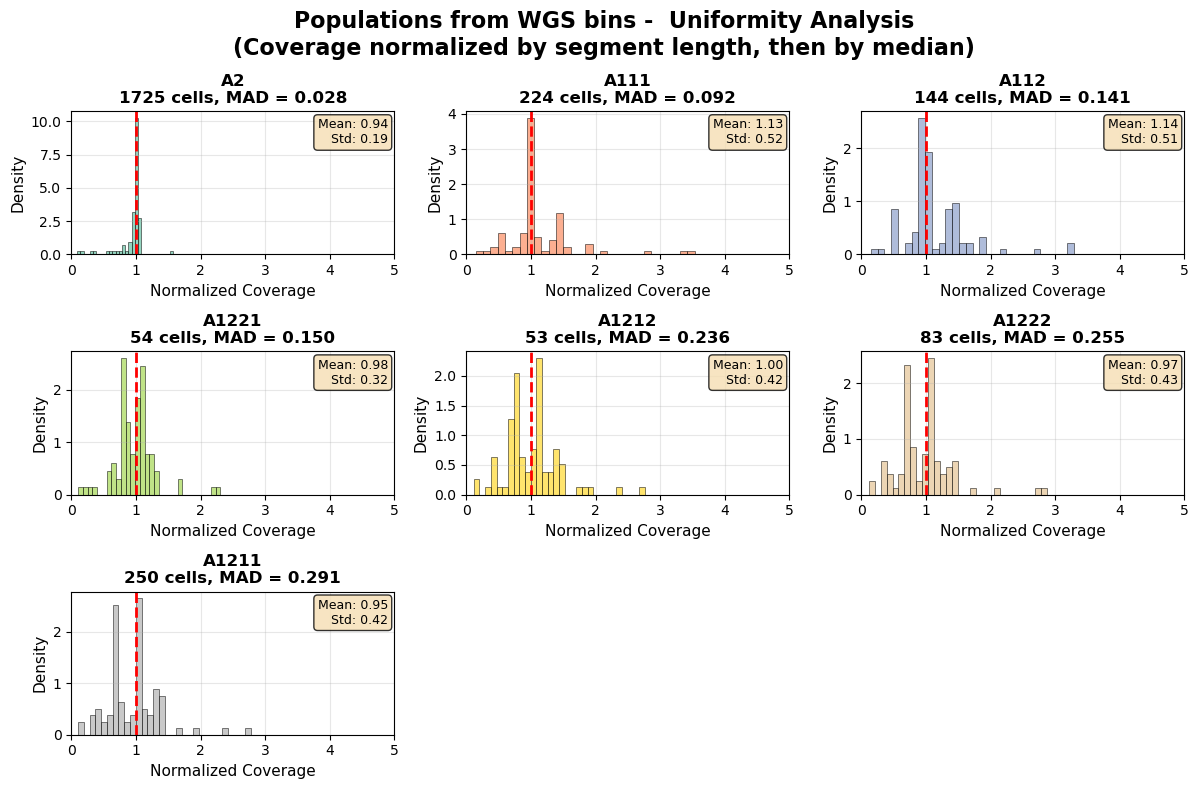


Populations from WGS bins -  Uniformity Summary:
Population   Cells    MAD      Mean     Std     
------------------------------------------------------------
A2           1725     0.028    0.94     0.19    
A111         224      0.092    1.13     0.52    
A112         144      0.141    1.14     0.51    
A1221        54       0.150    0.98     0.32    
A1212        53       0.236    1.00     0.42    
A1222        83       0.255    0.97     0.43    
A1211        250      0.291    0.95     0.42    

Identified normal population: A2 (lowest MAD = 0.028)


({'A111': 0     0.983621
  1     1.873522
  2     1.004989
  3     1.070578
  4     0.973323
          ...   
  84    0.852409
  85    1.402527
  86    1.394102
  87    1.229480
  88    0.948428
  Length: 89, dtype: float64,
  'A112': 0     0.981248
  1     1.890973
  2     1.003575
  3     1.437862
  4     0.946723
          ...   
  84    0.864167
  85    1.412688
  86    1.896921
  87    1.354482
  88    1.005082
  Length: 89, dtype: float64,
  'A1211': 0     0.762970
  1     1.410821
  2     1.272809
  3     1.393432
  4     0.688455
          ...   
  84    0.619299
  85    1.020404
  86    1.023707
  87    1.204415
  88    1.000000
  Length: 89, dtype: float64,
  'A1212': 0     0.763483
  1     1.447398
  2     1.124698
  3     1.857195
  4     1.000000
          ...   
  84    0.698245
  85    1.096393
  86    1.352940
  87    1.257237
  88    1.076314
  Length: 89, dtype: float64,
  'A1221': 0     0.861837
  1     1.269924
  2     1.126061
  3     1.338861
  4     0.823552
    

In [17]:
plot_uniformity_histograms_nice(
    all_data, 
    A_dict, 
    data_lengths, 
    uniformity_data=None,  # Optional: will compute if not provided
    title_prefix="Populations from WGS bins - ", 
    figsize=(12, 8)
)

In [18]:
# Display the ratios dataframes
print("Population A ratios:")
print(ratios_A.head())

print("\nPopulation B ratios:")
print(ratios_B.head())

Population A ratios:
  chrom      start        end  segment_id  A111_ratio  A112_ratio  \
0  chr1          0   45387037           0    0.985080    0.931115   
1  chr1   45972336  119478274           1    1.856392    1.775322   
2  chr1  120035598  175362842           2    1.495358    1.414863   
3  chr1  175900450  182029442           3    1.052693    1.339619   
4  chr1  182578512  248389233           4    0.985409    0.908162   

   A1211_ratio  A1212_ratio  A1221_ratio  A1222_ratio  A2_ratio  
0     0.971211     0.921651     1.121316     0.893721       1.0  
1     1.776827     1.728709     1.634736     1.669539       1.0  
2     2.407183     2.017170     2.176731     2.294479       1.0  
3     1.741532     2.201221     1.710322     1.659750       1.0  
4     0.885926     1.220344     1.083201     0.856279       1.0  

Population B ratios:
  chrom      start        end  segment_id  B111_ratio  B112_ratio  \
0  chr1      10001   30659098           0    0.978165    0.919401   
1  chr1 

In [19]:
relative_counts_A

{'A111': np.float64(1.1925537475670602),
 'A112': np.float64(1.1428918922277707),
 'A1211': np.float64(1.269739728319822),
 'A1212': np.float64(1.266138207809019),
 'A1221': np.float64(1.3353303568204509),
 'A1222': np.float64(1.2236558507937287),
 'A2': np.float64(1.0)}

In [20]:
# Perform ploidy optimization for each population in set A (excluding normal)
print("=== Ploidy Optimization for Population Set A ===")

# Get all population ratio columns (excluding normal population)
pop_ratio_cols_A = [col for col in ratios_A.columns if col.endswith('_ratio') and col != f"{normal_A}_ratio"]

# Store results
ploidy_results_A = {}
profile_dfs_A = {}

print(f"Normal population: {normal_A}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_A]}")

for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")

=== Ploidy Optimization for Population Set A ===
Normal population: A2
Populations to optimize: ['A111', 'A112', 'A1211', 'A1212', 'A1221', 'A1222']

Optimizing ploidy for population: A111

Optimal Results for A111:
Optimal multiplier (m): 2.100
Minimum cost: 3.65e+07
Average copy number: 2.48
Optimal multiplier for A111: 2.100

Optimizing ploidy for population: A112

Optimal Results for A112:
Optimal multiplier (m): 2.200
Minimum cost: 5.34e+07
Average copy number: 2.54
Optimal multiplier for A112: 2.200

Optimizing ploidy for population: A1211

Optimal Results for A1211:
Optimal multiplier (m): 2.300
Minimum cost: 6.63e+07
Average copy number: 2.94
Optimal multiplier for A1211: 2.300

Optimizing ploidy for population: A1212

Optimal Results for A1212:
Optimal multiplier (m): 2.300
Minimum cost: 1.07e+08
Average copy number: 2.92
Optimal multiplier for A1212: 2.300

Optimizing ploidy for population: A1221

Optimal Results for A1221:
Optimal multiplier (m): 3.600
Minimum cost: 1.77e+08

In [21]:
# In your existing ploidy optimization loop, just modify the function call:
for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Get local minima along with the usual results
    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1, 
        find_local_minima=True,  # Add this parameter
        window_size=2           # Optional: adjust window size
    )
    
    # Store results including local minima
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima  # Add this
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")


Optimizing ploidy for population: A111

Optimal Results for A111:
Optimal multiplier (m): 2.100
Minimum cost: 3.65e+07
Average copy number: 2.48
Found 4 local minima
Optimal multiplier for A111: 2.100
Found 4 local minima: ['2.10', '4.20', '4.90', '2.90']

Optimizing ploidy for population: A112

Optimal Results for A112:
Optimal multiplier (m): 2.200
Minimum cost: 5.34e+07
Average copy number: 2.54
Found 4 local minima
Optimal multiplier for A112: 2.200
Found 4 local minima: ['2.20', '4.40', '3.20', '5.30']

Optimizing ploidy for population: A1211

Optimal Results for A1211:
Optimal multiplier (m): 2.300
Minimum cost: 6.63e+07
Average copy number: 2.94
Found 7 local minima
Optimal multiplier for A1211: 2.300
Found 7 local minima: ['2.30', '4.50', '5.30', '3.00', '5.80']

Optimizing ploidy for population: A1212

Optimal Results for A1212:
Optimal multiplier (m): 2.300
Minimum cost: 1.07e+08
Average copy number: 2.92
Found 5 local minima
Optimal multiplier for A1212: 2.300
Found 5 local


Plotting results for population: A111


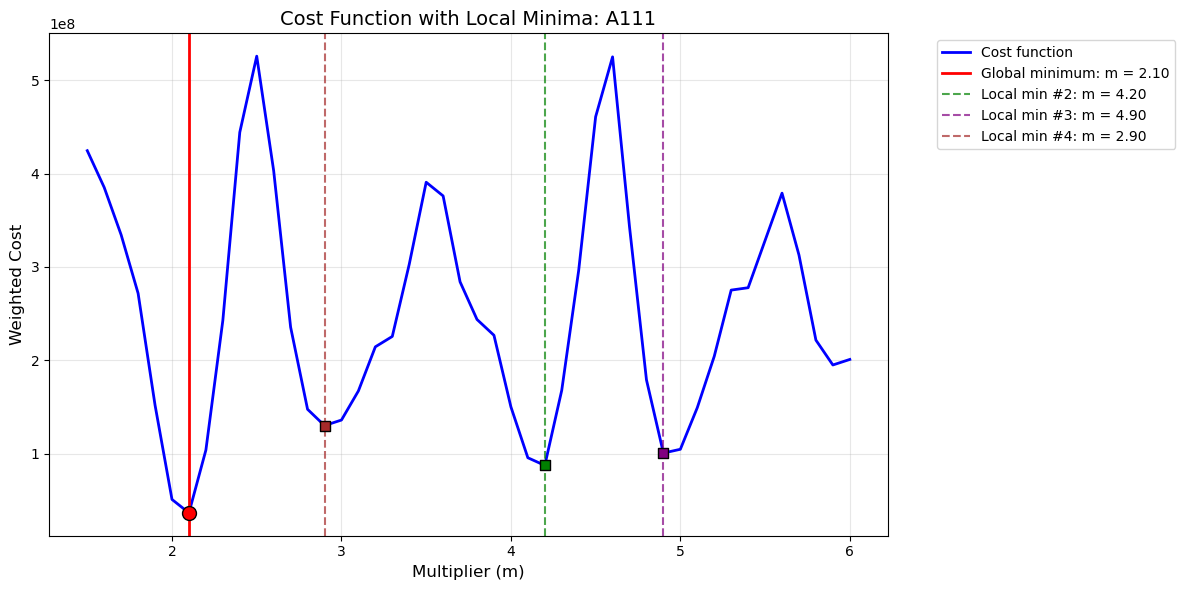


Local Minima Summary for A111:
--------------------------------------------------
#1: m = 2.10, cost = 3.65e+07 (GLOBAL)
#2: m = 4.20, cost = 8.74e+07
#3: m = 4.90, cost = 1.01e+08
#4: m = 2.90, cost = 1.30e+08


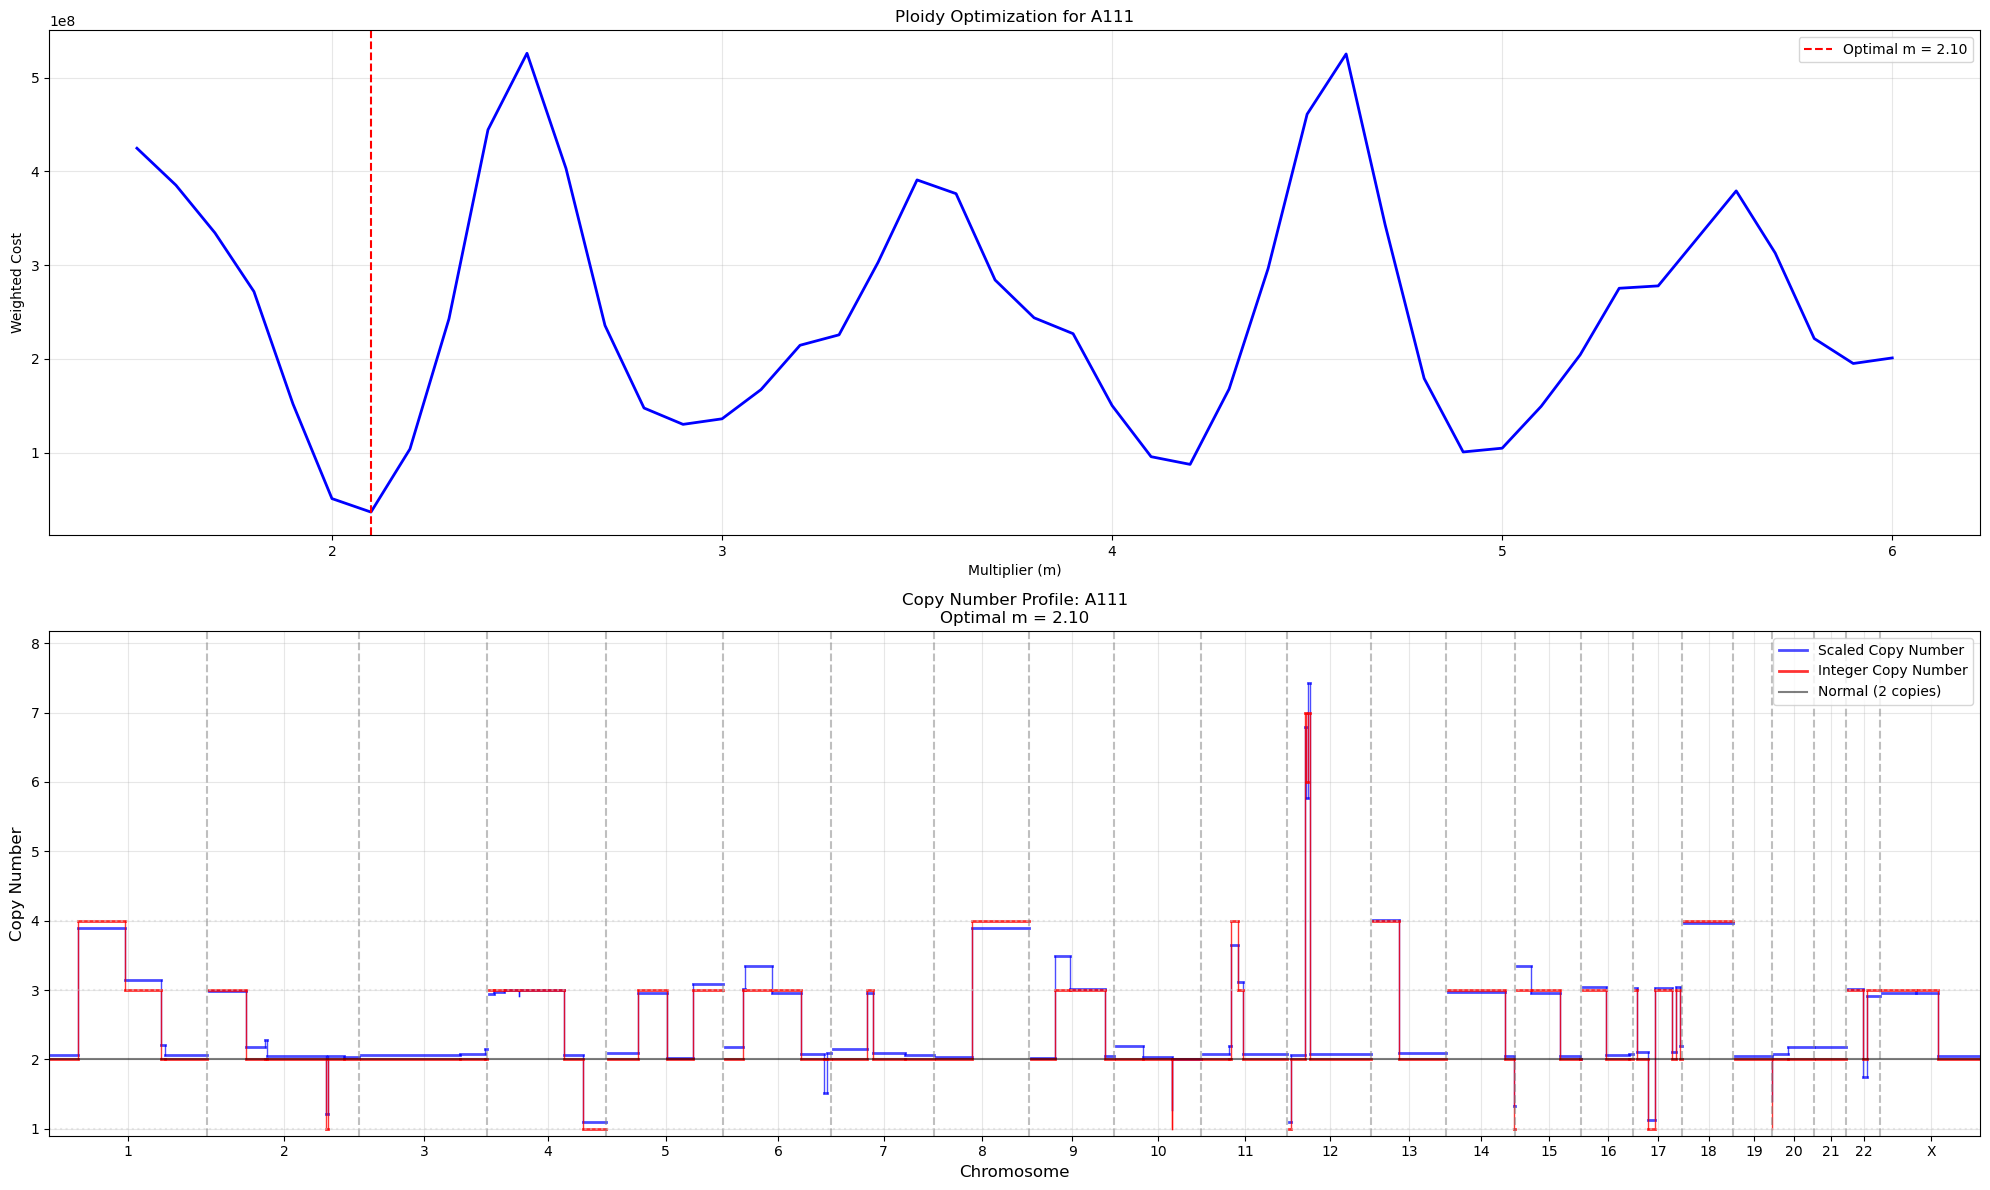

Completed plots for A111

Plotting results for population: A112


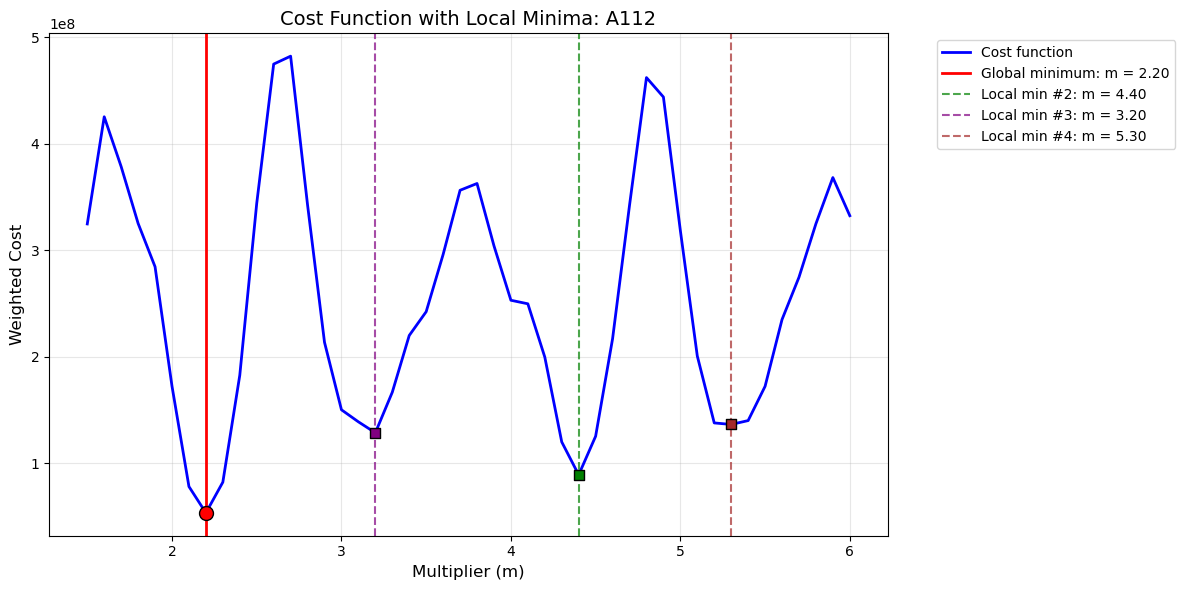


Local Minima Summary for A112:
--------------------------------------------------
#1: m = 2.20, cost = 5.34e+07 (GLOBAL)
#2: m = 4.40, cost = 8.91e+07
#3: m = 3.20, cost = 1.29e+08
#4: m = 5.30, cost = 1.36e+08


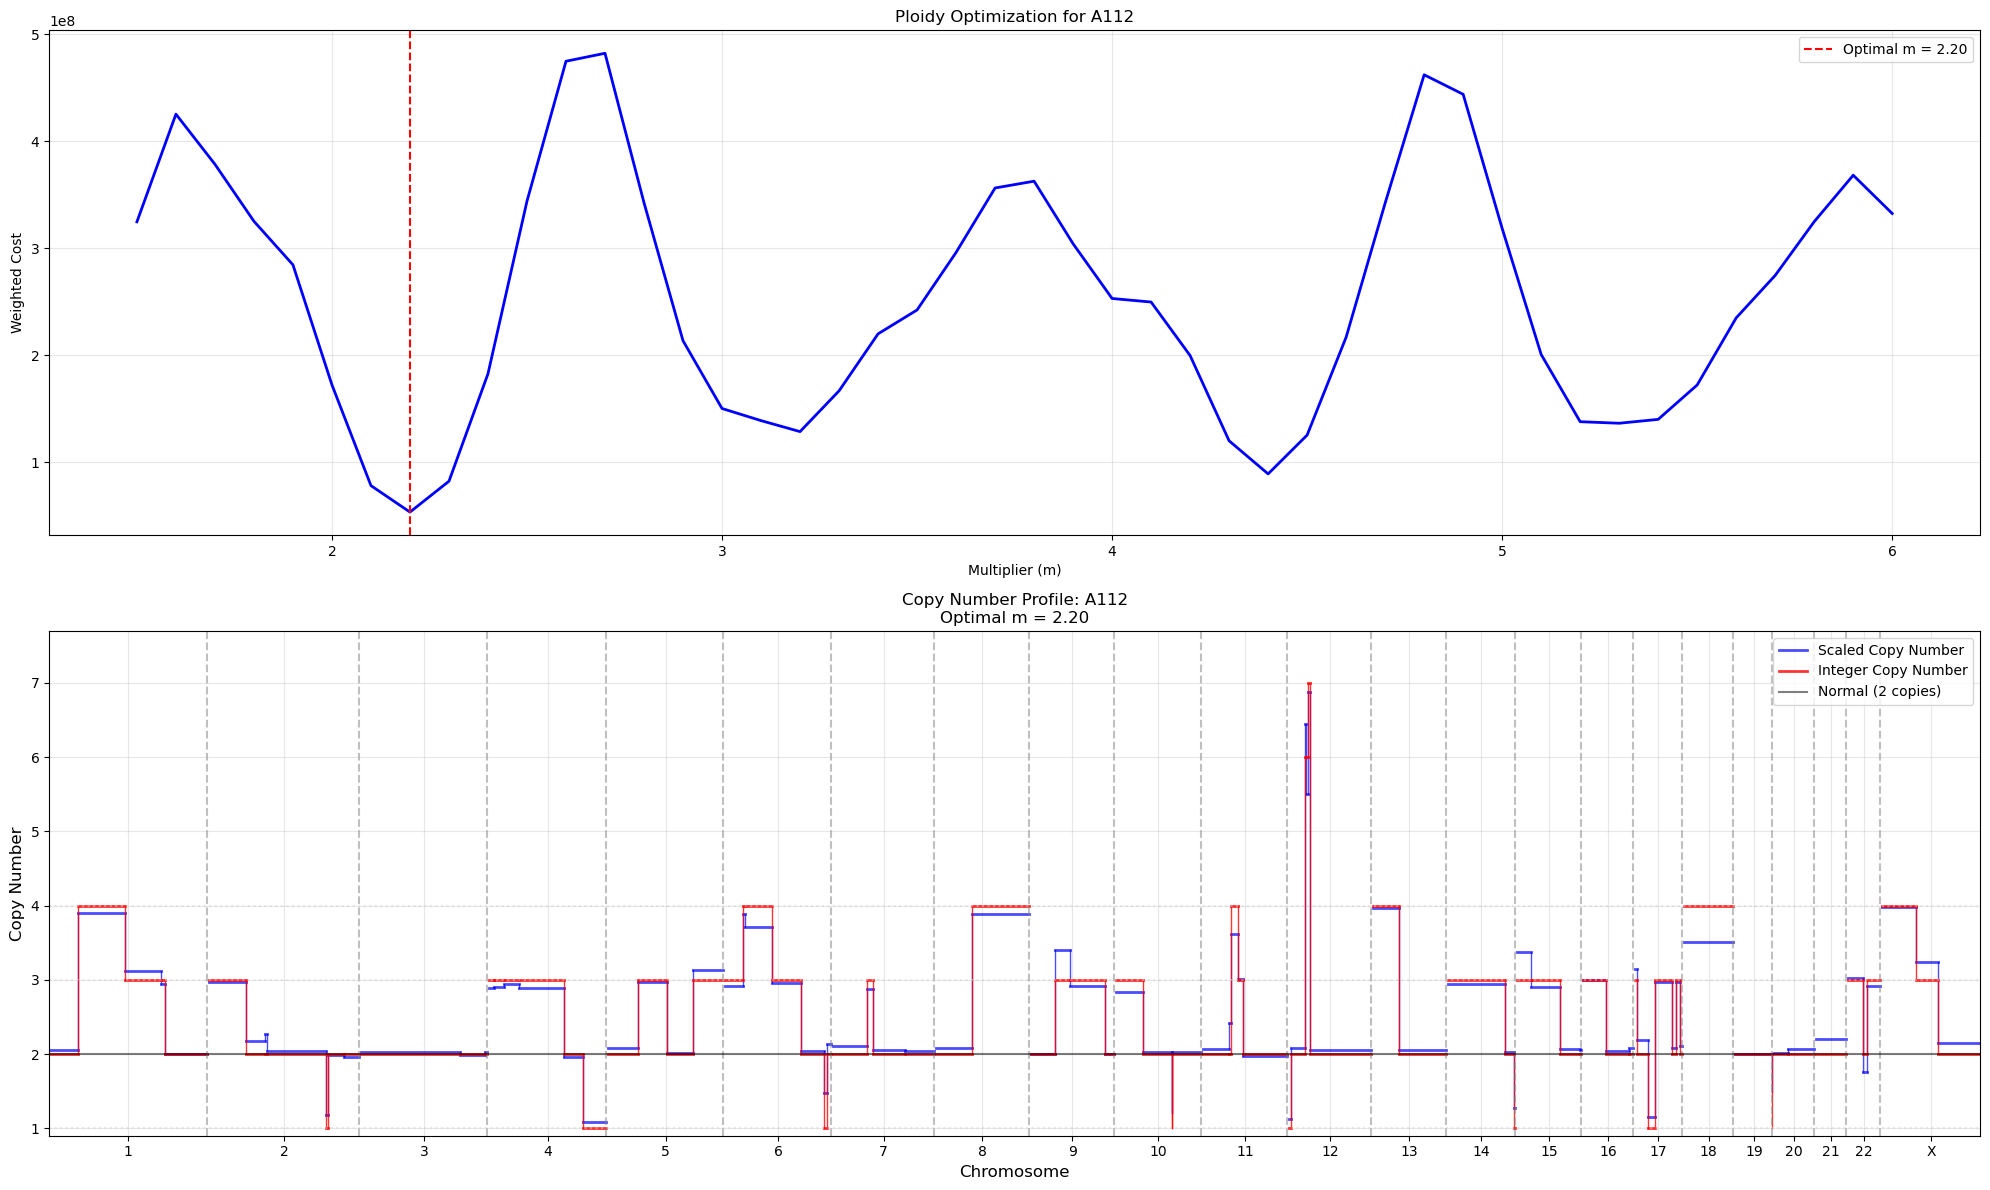

Completed plots for A112

Plotting results for population: A1211


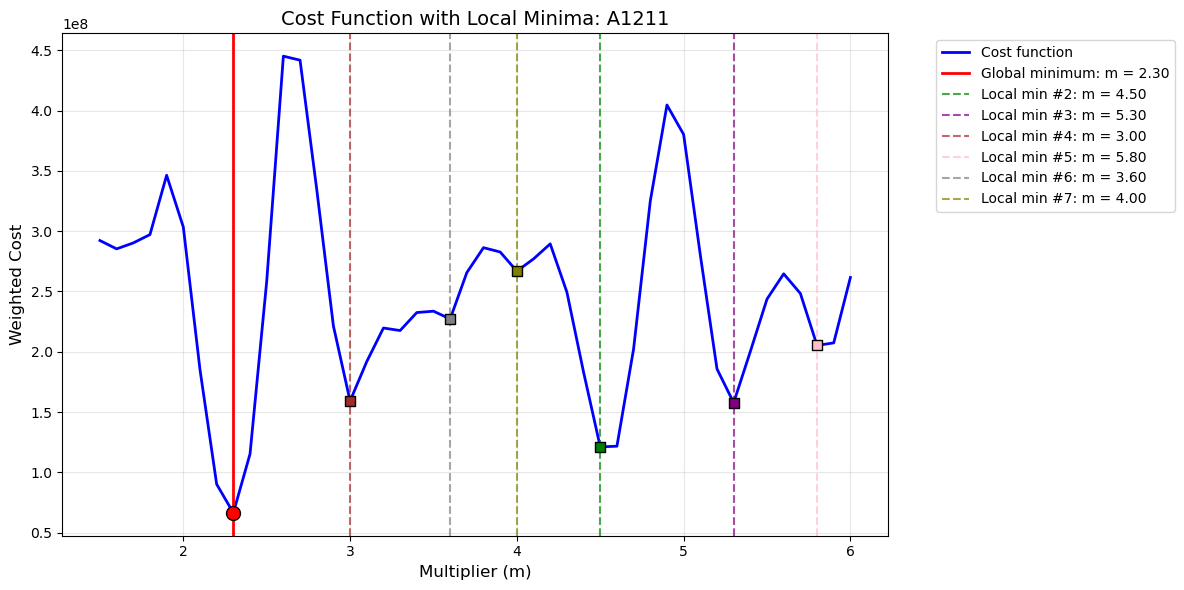


Local Minima Summary for A1211:
--------------------------------------------------
#1: m = 2.30, cost = 6.63e+07 (GLOBAL)
#2: m = 4.50, cost = 1.21e+08
#3: m = 5.30, cost = 1.58e+08
#4: m = 3.00, cost = 1.59e+08
#5: m = 5.80, cost = 2.05e+08
#6: m = 3.60, cost = 2.27e+08
#7: m = 4.00, cost = 2.67e+08


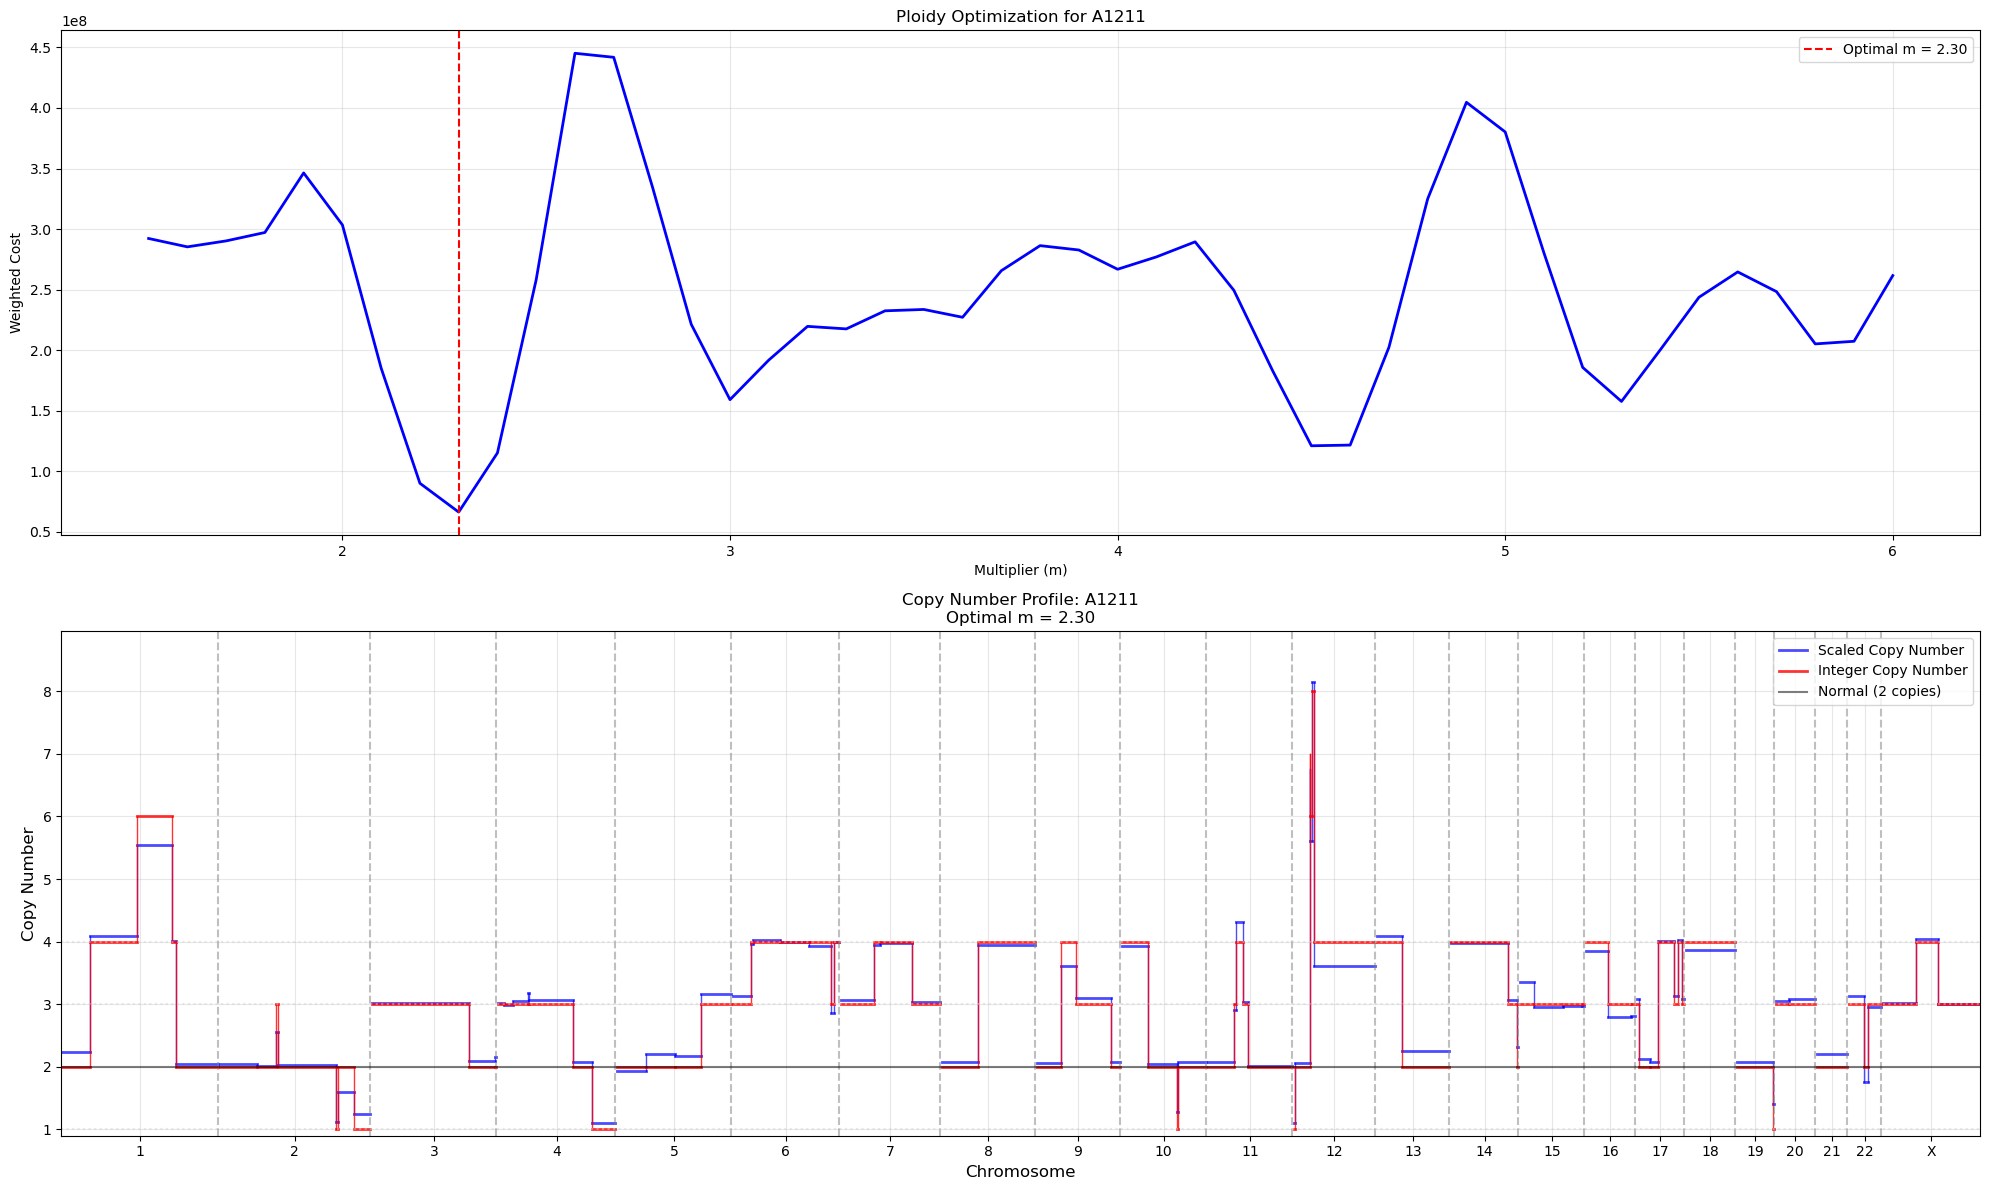

Completed plots for A1211

Plotting results for population: A1212


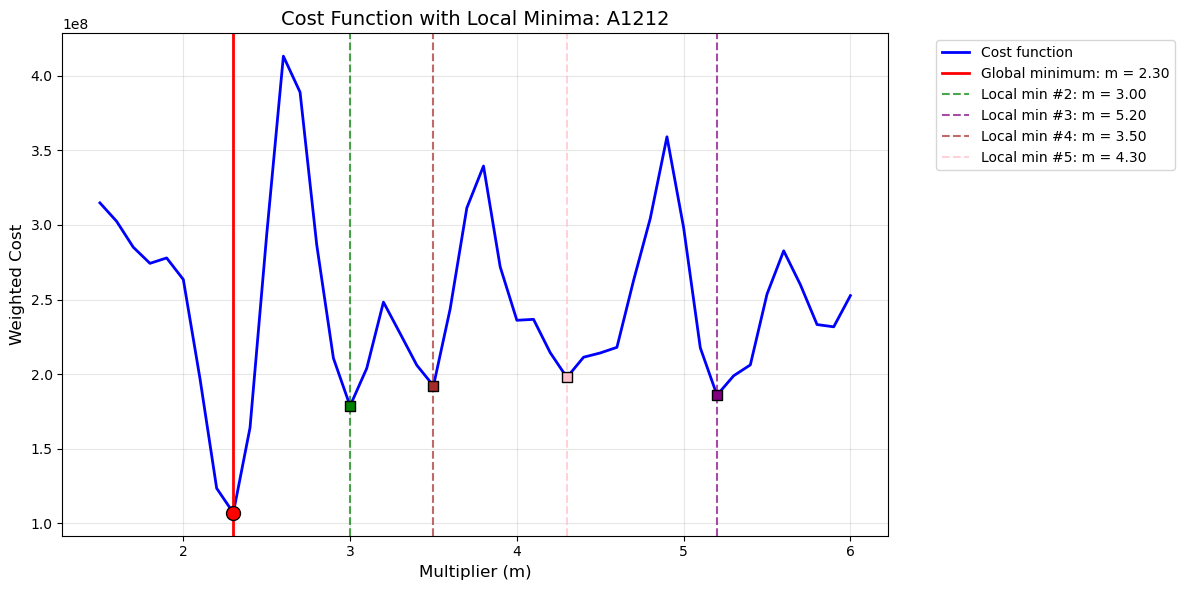


Local Minima Summary for A1212:
--------------------------------------------------
#1: m = 2.30, cost = 1.07e+08 (GLOBAL)
#2: m = 3.00, cost = 1.79e+08
#3: m = 5.20, cost = 1.86e+08
#4: m = 3.50, cost = 1.92e+08
#5: m = 4.30, cost = 1.98e+08


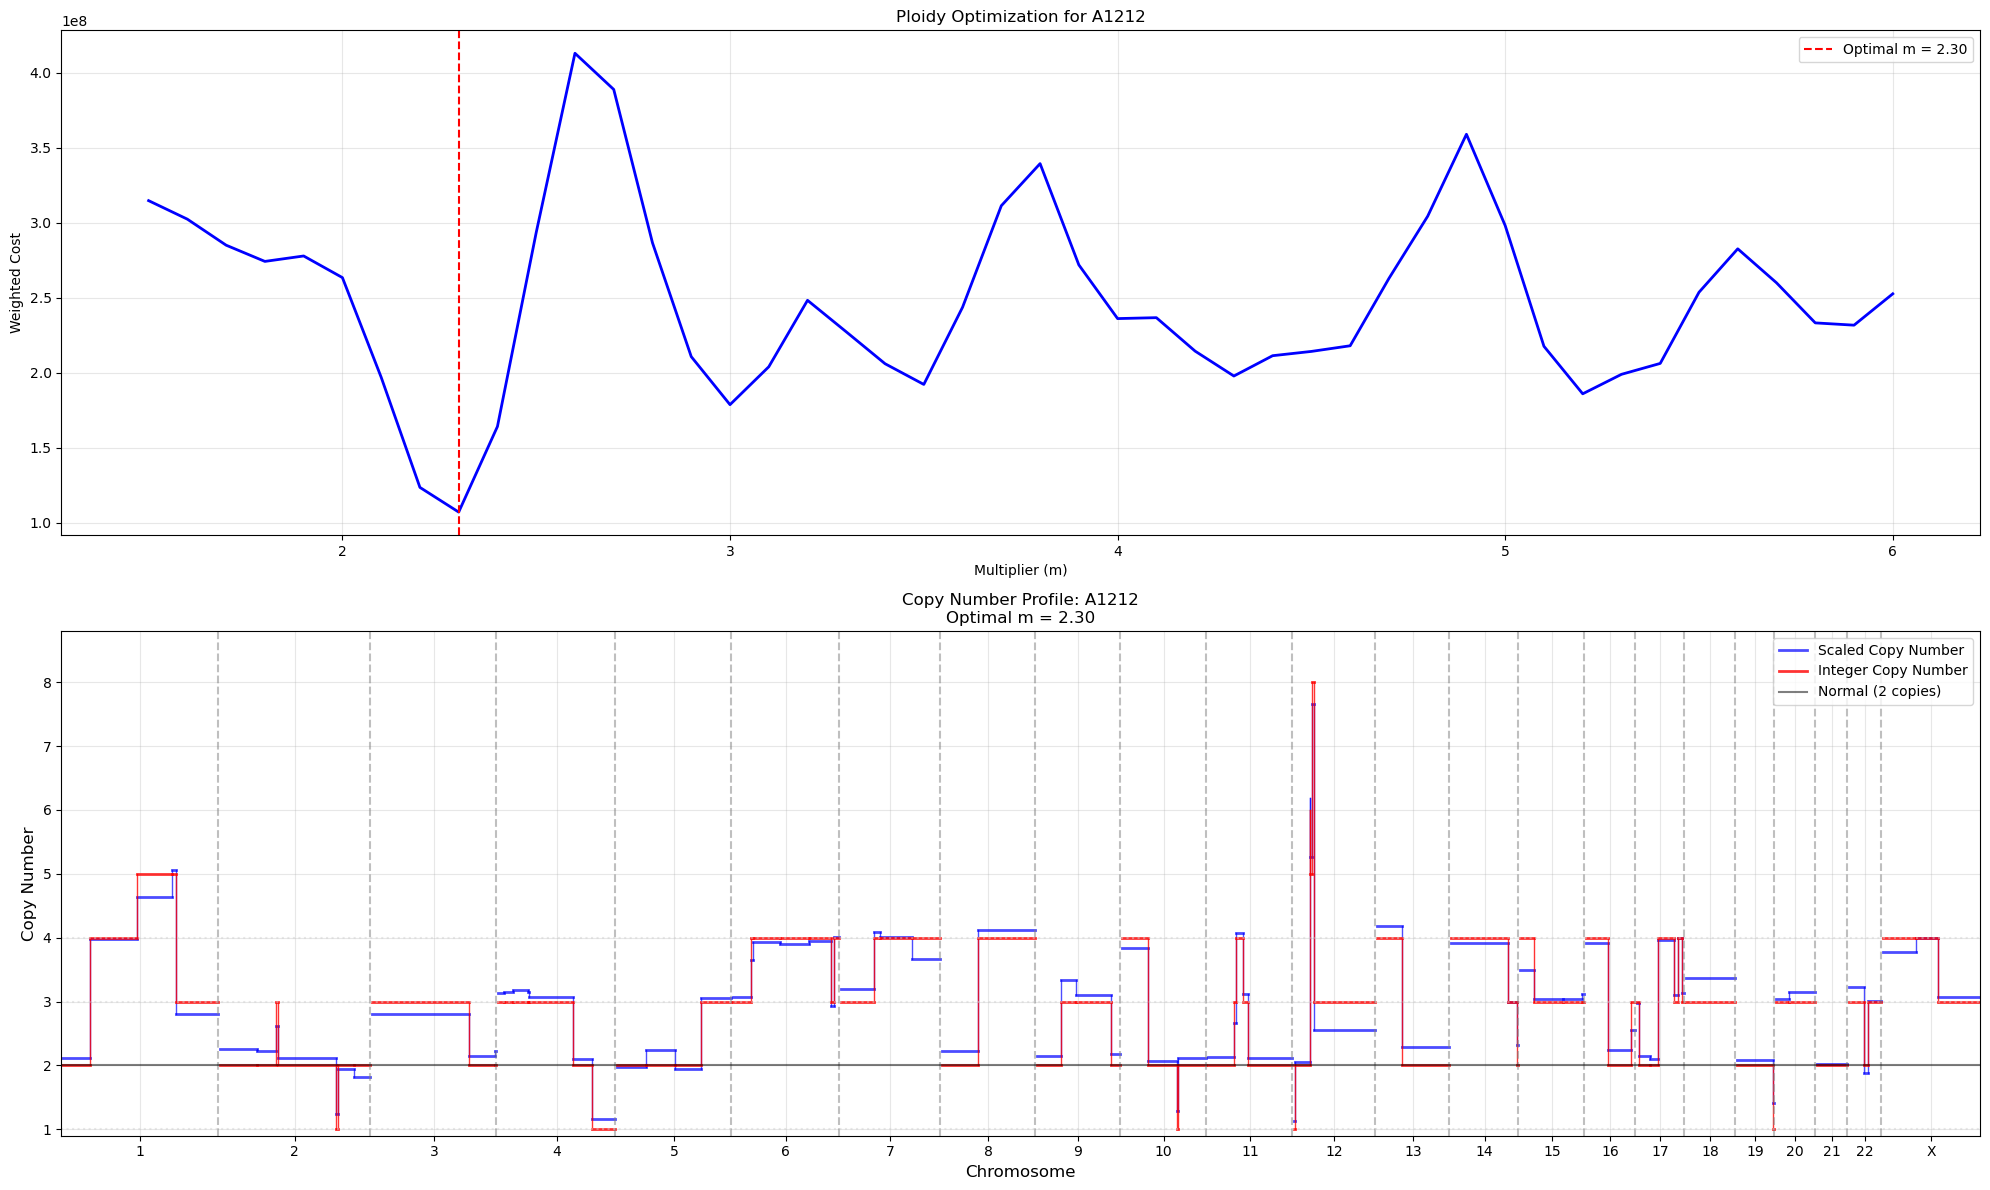

Completed plots for A1212

Plotting results for population: A1221


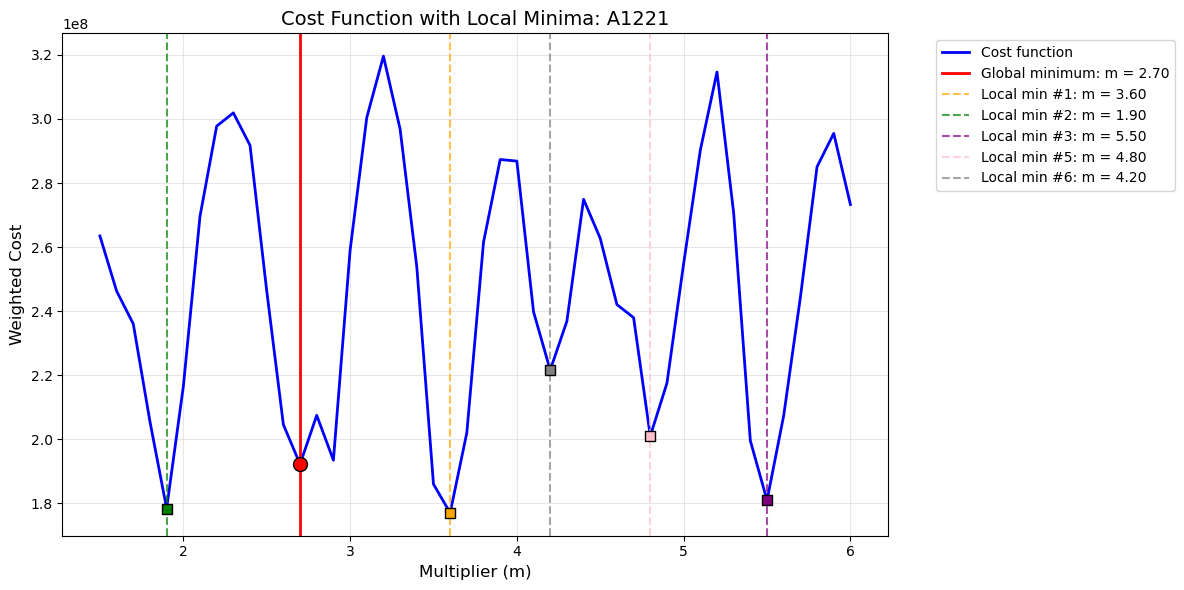


Local Minima Summary for A1221:
--------------------------------------------------
#1: m = 3.60, cost = 1.77e+08
#2: m = 1.90, cost = 1.78e+08
#3: m = 5.50, cost = 1.81e+08
#4: m = 2.70, cost = 1.92e+08 (GLOBAL)
#5: m = 4.80, cost = 2.01e+08
#6: m = 4.20, cost = 2.22e+08


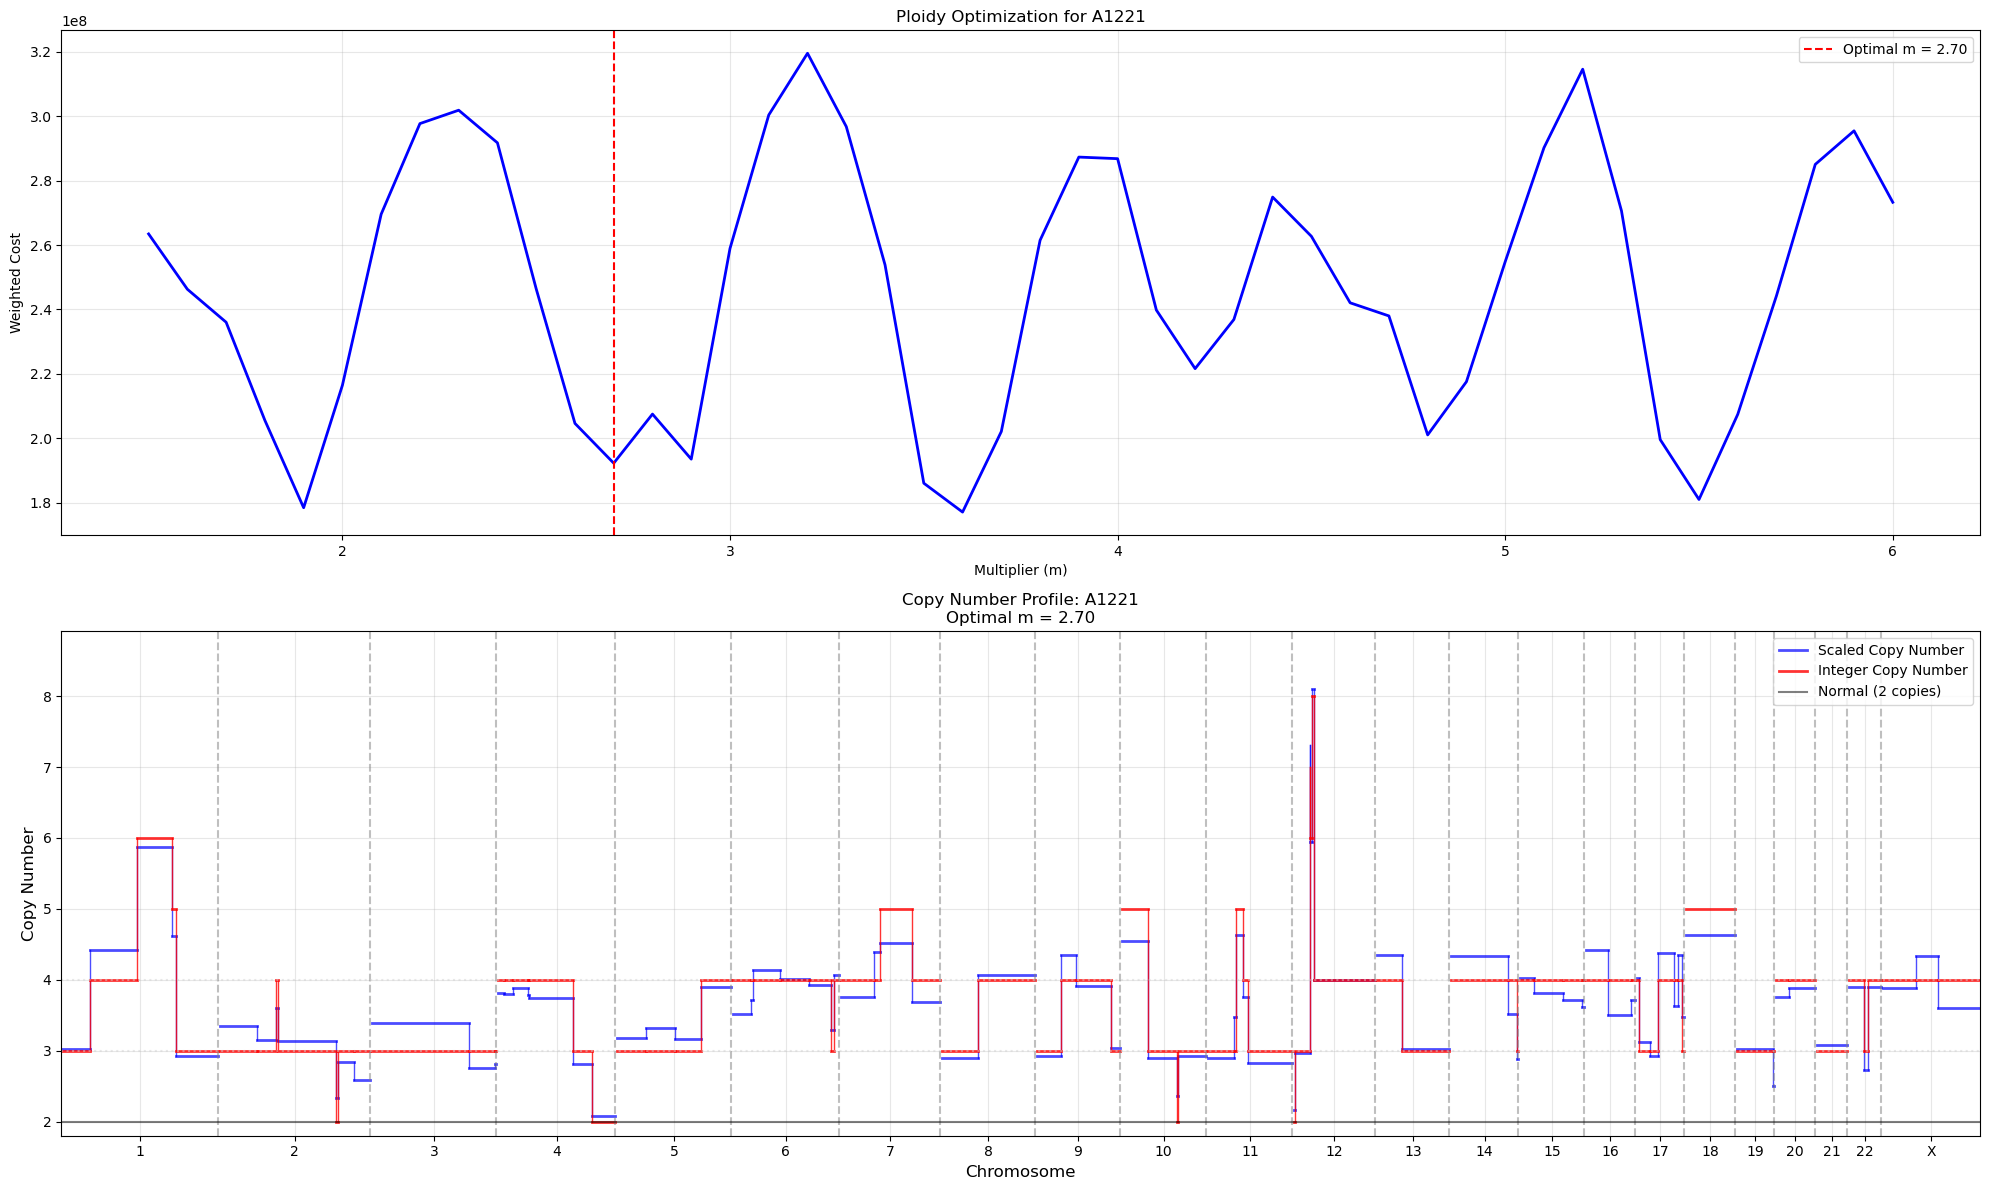

Completed plots for A1221

Plotting results for population: A1222


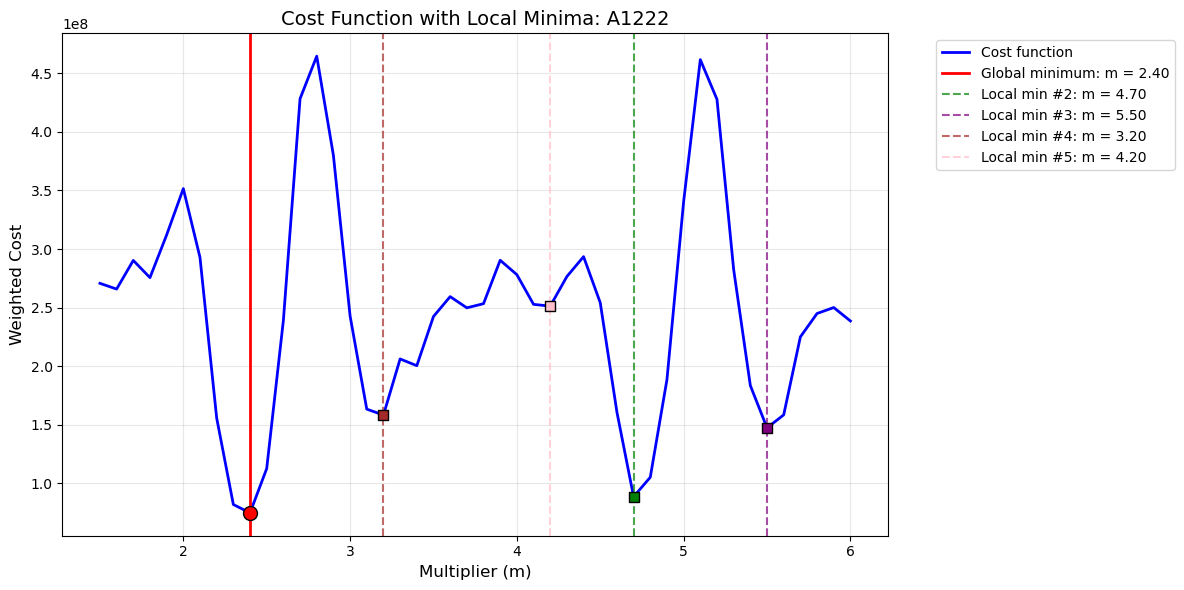


Local Minima Summary for A1222:
--------------------------------------------------
#1: m = 2.40, cost = 7.48e+07 (GLOBAL)
#2: m = 4.70, cost = 8.85e+07
#3: m = 5.50, cost = 1.47e+08
#4: m = 3.20, cost = 1.58e+08
#5: m = 4.20, cost = 2.51e+08


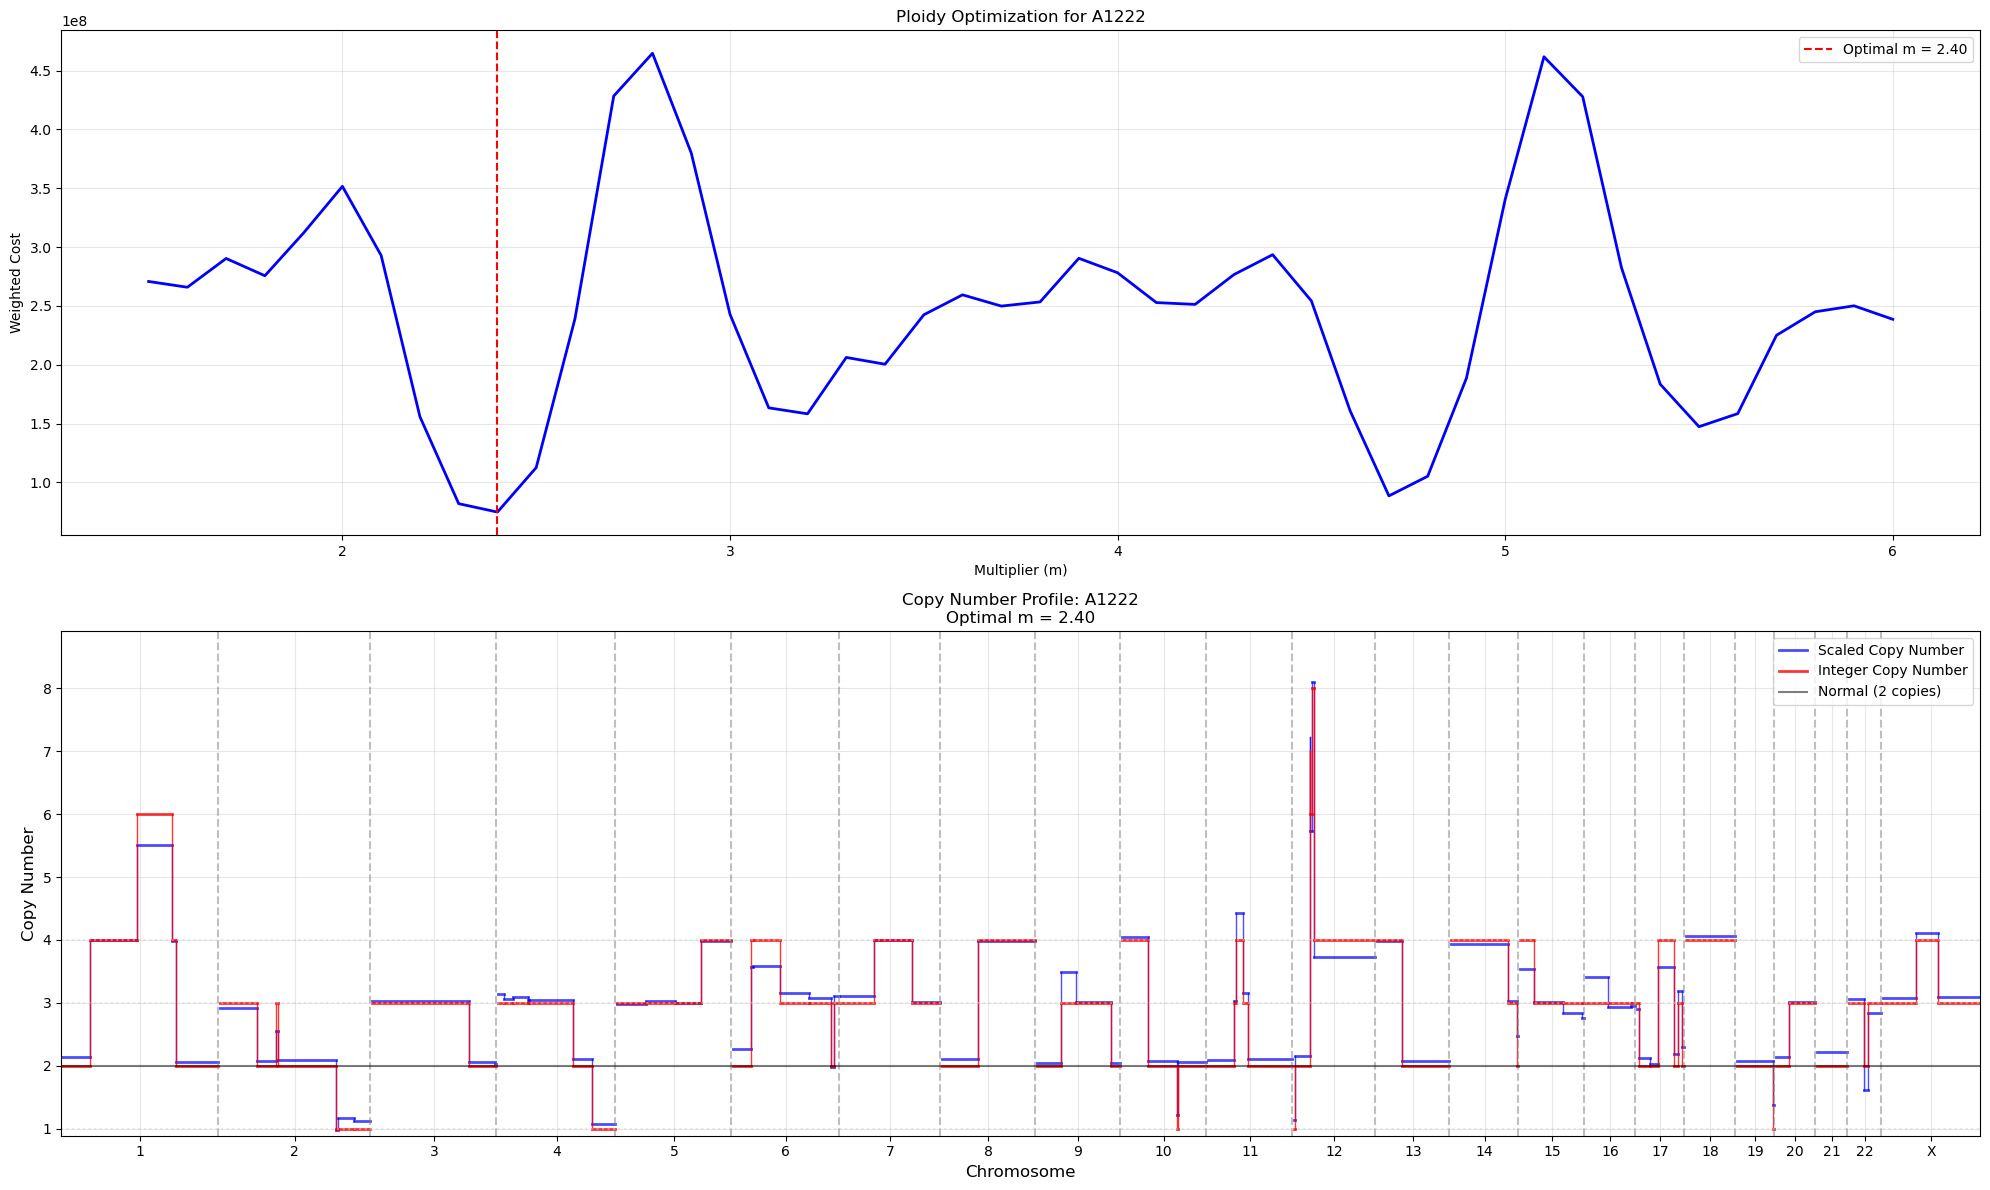

Completed plots for A1222


In [22]:
# Test the plotting functions on your ploidy results
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Plotting results for population: {pop_name}")
    
    # Get the results for this population
    results = ploidy_results_A[pop_name]
    profile_df = profile_dfs_A[pop_name]
    
    # 1. Plot cost function with local minima
    plot_cost_function_with_minima(
        cost_results=results['cost_results'],
        local_minima=results['local_minima'],
        pop_name=pop_name,
        optimal_m=results['optimal_multiplier']
    )
    
    # 2. Plot the full ploidy optimization (cost function + copy number profile)
    pop_col = f"{pop_name}_ratio"  # Reconstruct the column name
    plot_ploidy_optimization(
        results_df=profile_df,
        cost_results=results['cost_results'],
        optimal_m=results['optimal_multiplier'],
        pop_col=pop_col
    )
    
    print(f"Completed plots for {pop_name}")

In [23]:
import os
import pandas as pd

# Define the parquet file path
parquet_file = f"../data/{tumor}/hap_count_df.parquet"

# Check if parquet file exists, if so load it, otherwise create and save it
if os.path.exists(parquet_file):
    print("Loading hap_count_df from parquet file...")
    hap_count_df = pd.read_parquet(parquet_file)
    print(f"Loaded hap_count_df with shape: {hap_count_df.shape}")
else:
    print("Parquet file not found. Creating hap_count_df from source data...")
    
    hap_count_df = pd.read_csv(f"/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/{tumor}/per_cell_hap_count.txt", sep = "\t")
    binning = pd.read_csv("/mnt/wigstore3/user/kendall/hg19.50mer/hg19.varbin.gc.content.2.5k.bowtie.k50.txt", sep='\t')
    bin_loc_dict = dict(zip(binning.index, binning["bin.start.abspos"]))
    chrom_dict = dict(zip(binning.index, binning["bin.chrom"]))

    hap_count_df["abspos"] = hap_count_df["bin"].apply(lambda x : bin_loc_dict[x])
    hap_count_df["chrom"] = hap_count_df["bin"].apply(lambda x : chrom_dict[x])
    hap_count_df= hap_count_df[["chrom", "abspos","bin", "cell", "hap_count","Total"]]

    print(f"Created hap_count_df with shape: {hap_count_df.shape}")
    
    # Save as parquet for future use
    print("Saving hap_count_df as parquet file...")
    hap_count_df.to_parquet(parquet_file, index=False)
    
    # Check file size
    file_size = os.path.getsize(parquet_file)
    print(f"Saved parquet file: {file_size:,} bytes ({file_size/1024**2:.2f} MB)")

print("hap_count_df ready for analysis!")

Loading hap_count_df from parquet file...
Loaded hap_count_df with shape: (8605992, 6)
hap_count_df ready for analysis!


In [24]:
hap_count_df.head()

,chrom,abspos,bin,cell,hap_count,Total
0,chr1,0,0,AATGAGGATGCAACACA,3,6
1,chr1,1925685,1,AATGAGGATGCAACACA,0,2
2,chr1,3106884,2,AATGAGGATGCAACACA,0,2
3,chr1,4351684,3,AATGAGGATGCAACACA,7,7
4,chr1,5438445,4,AATGAGGATGCAACACA,0,0


In [25]:
bin_to_chrom_dict = dict(zip(hap_count_df[["chrom", "bin"]].drop_duplicates()["bin"].values, hap_count_df[["chrom", "bin"]].drop_duplicates()["chrom"].values))

In [26]:
example = list(A_dict.keys())[1]

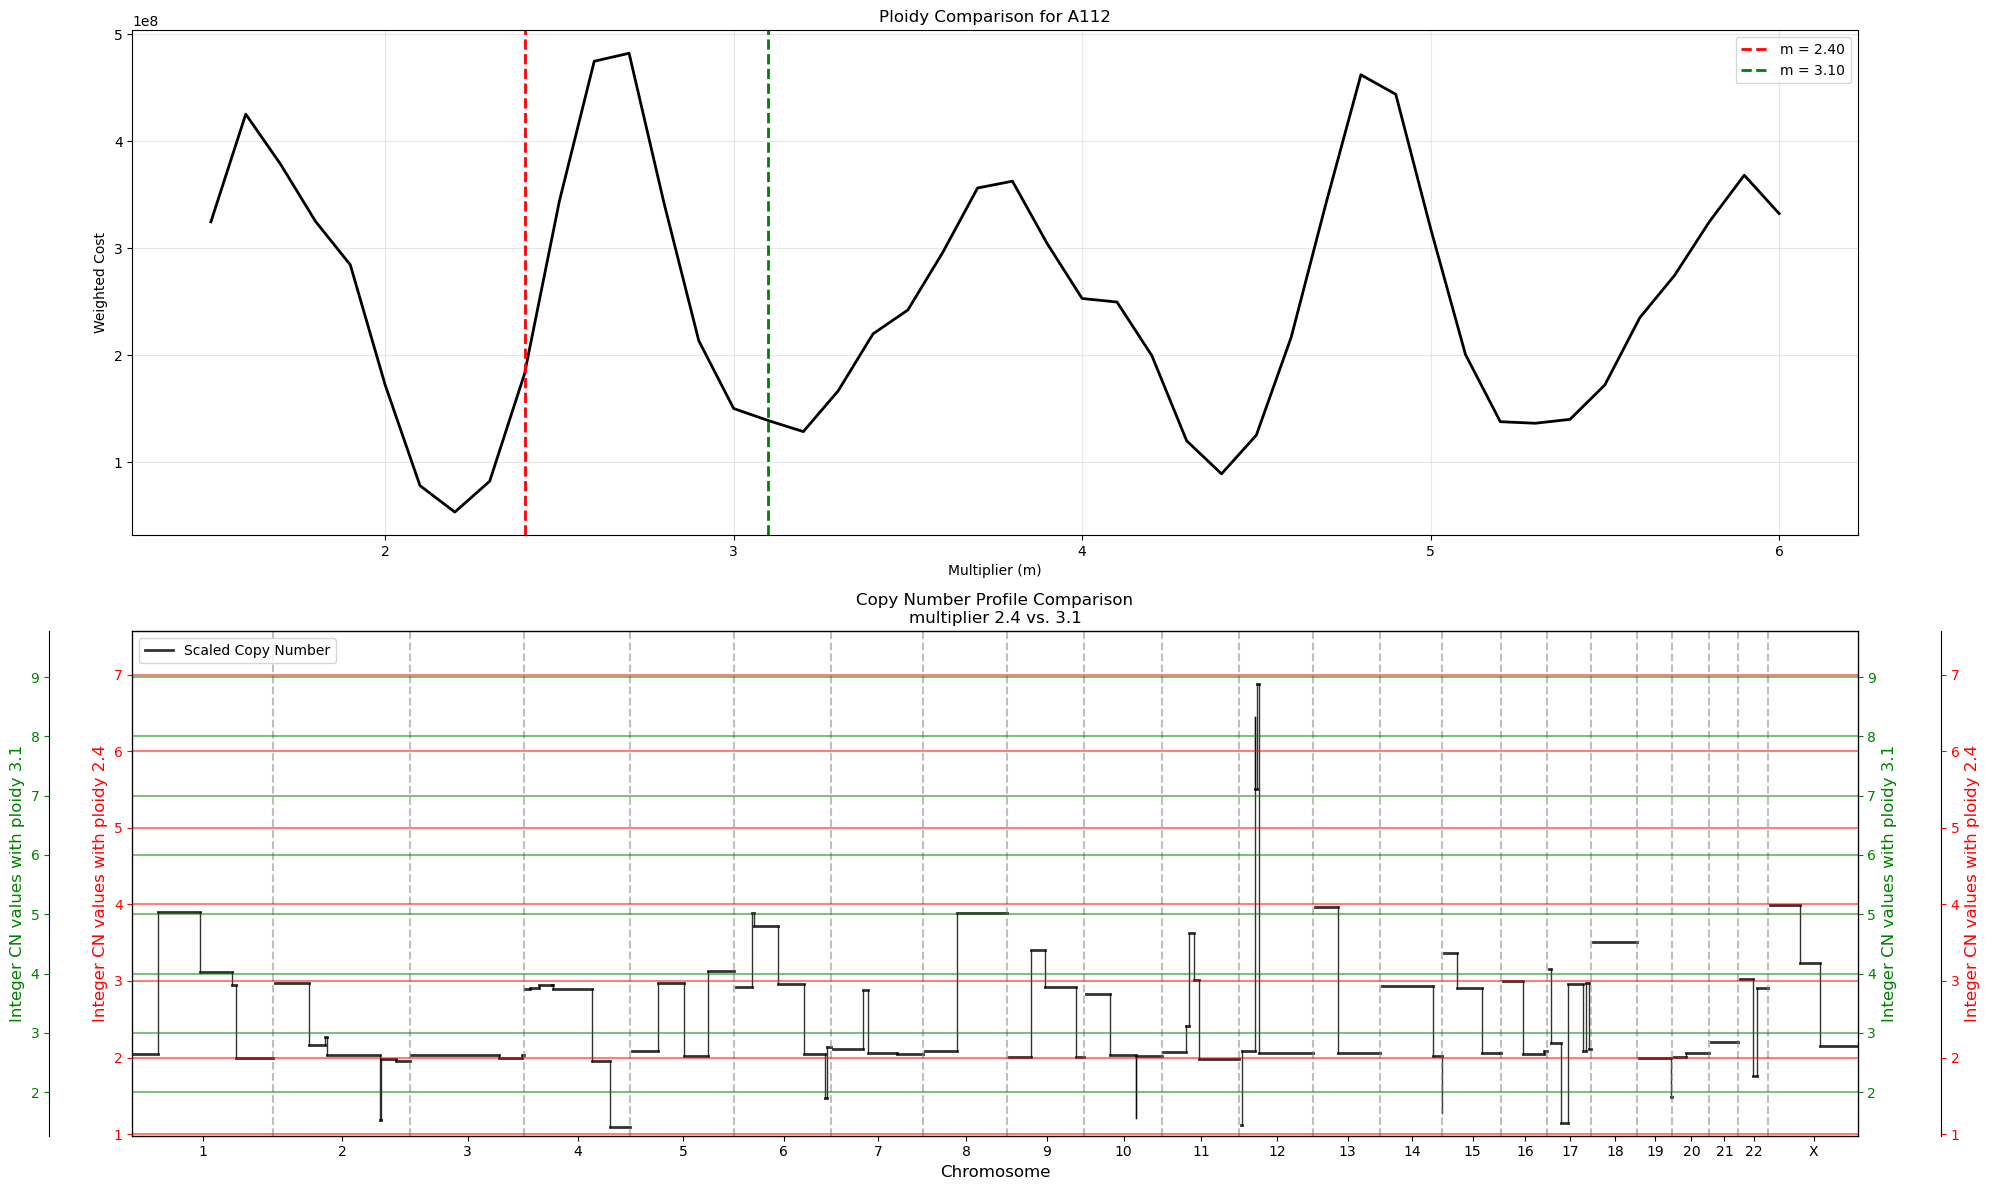

In [27]:
# Example usage for A211 with global min 2.4 and local min 3.1
plot_ploidy_comparison(
    results_df=profile_dfs_A[example],
    cost_results=ploidy_results_A[example]['cost_results'],
    optimal_m=2.4,  # or use ploidy_results_A[example]['optimal_multiplier']
    local_m=3.1,   # pick from ploidy_results_A[example]['local_minima']
    pop_col=f'{example}_ratio'
)

In [28]:
#Get all cells in example
example_cells = A_dict[example]['cells']
#Filter hap_count_df for these cells
example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
example_hap_ratio['hap_ratio'] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
example_hap_ratio['folded'] = example_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information    
example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])

In [29]:
normal_A

'A2'

In [30]:
#Get all cells in A1
normal_cells = A_dict[normal_A]['cells']
#Filter hap_count_df for these cells
normal_hap_df = hap_count_df[hap_count_df['cell'].isin(normal_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
normal_hap_ratio = normal_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
normal_hap_ratio['hap_ratio'] = normal_hap_ratio['hap_count'] / normal_hap_ratio['Total']
normal_hap_ratio['folded'] = normal_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information
normal_hap_ratio["chrom"] = normal_hap_ratio["bin"].apply(lambda x: bin_to_chrom_dict[x])

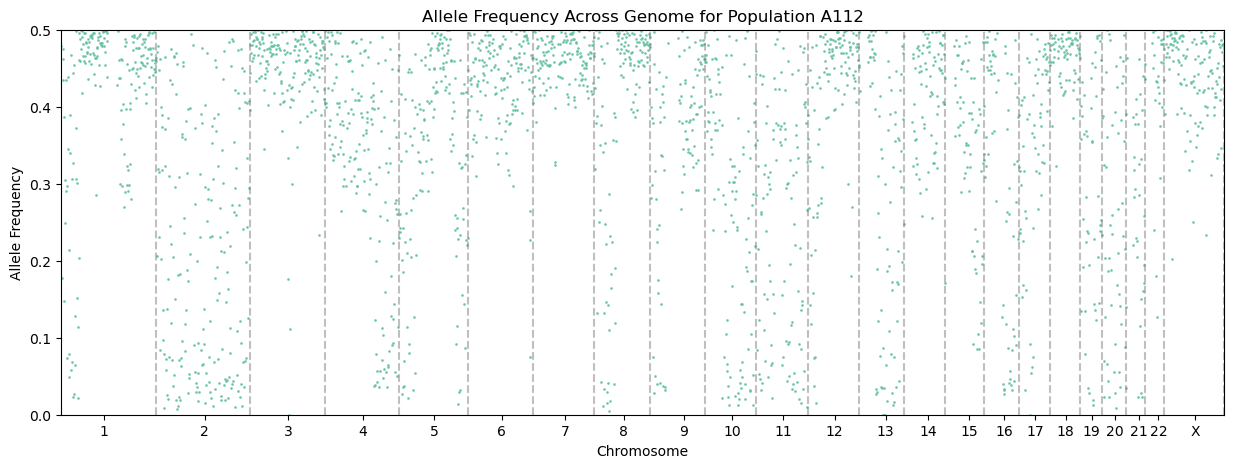

In [31]:
# plot the folded allele frequency along the genome
example_hap_ratio_sorted = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(example_hap_ratio_sorted['abspos'], example_hap_ratio_sorted['folded'], s=1, alpha=0.8)
plt.xlabel('Chromosome')
plt.ylabel('Allele Frequency')
plt.title('Allele Frequency Across Genome for Population ' + example)
# Add vertical lines for chromosome boundaries
chrom_boundaries = example_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = example_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(example_hap_ratio_sorted['abspos'].min(), example_hap_ratio_sorted['abspos'].max())
plt.show()

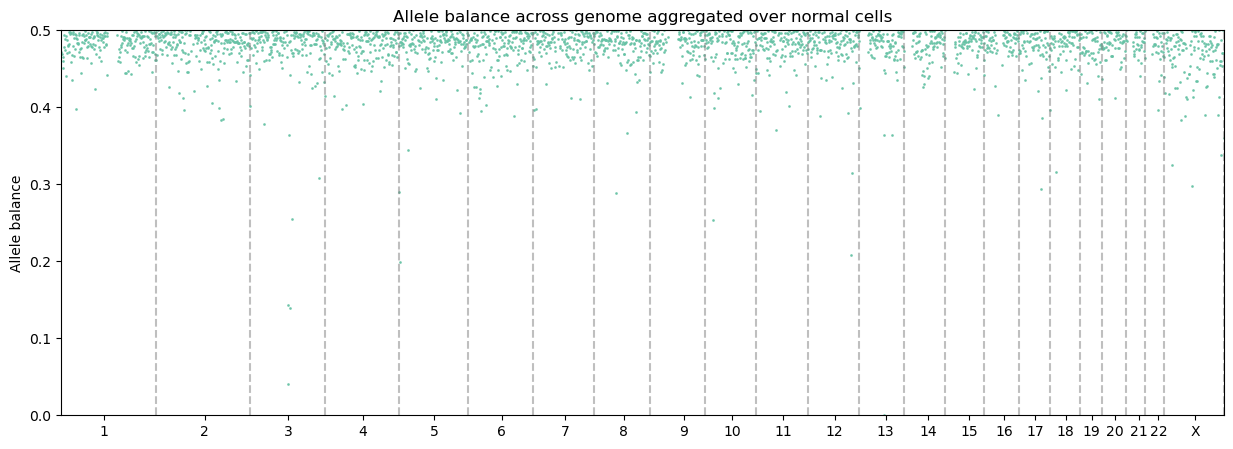

In [32]:
# plot the folded allele frequency along the genome
normal_hap_ratio_sorted = normal_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(normal_hap_ratio_sorted['abspos'], normal_hap_ratio_sorted['folded'], s=1, alpha=0.8)
#plt.xlabel('Chromosome')
plt.ylabel('Allele balance')
plt.title('Allele balance across genome aggregated over normal cells')
# Add vertical lines for chromosome boundaries
chrom_boundaries = normal_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = normal_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(normal_hap_ratio_sorted['abspos'].min(), normal_hap_ratio_sorted['abspos'].max())
plt.show()

In [33]:
A_df.head()

,cell,population,normal_population
0,AAAACCAACTTTTGACG,A111,False
1,AAAACCACTGGCCTTAC,A111,False
2,AAAACCGAAATCGGTAT,A111,False
3,AAAATGGTTACTGTTCT,A111,False
4,AAAGCAATACCGCGATG,A111,False


In [34]:
#Get all tumor cells in (not A1)
tumor_cells = A_df[A_df['population'] != normal_A]['cell'].tolist()
#Filter hap_count_df for these cells
tumor_hap_df = hap_count_df[hap_count_df['cell'].isin(tumor_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
tumor_hap_ratio = tumor_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
tumor_hap_ratio['hap_ratio'] = tumor_hap_ratio['hap_count'] / tumor_hap_ratio['Total']
tumor_hap_ratio['folded'] = tumor_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information
tumor_hap_ratio["chrom"] = tumor_hap_ratio["bin"].apply(lambda x: bin_to_chrom_dict[x])


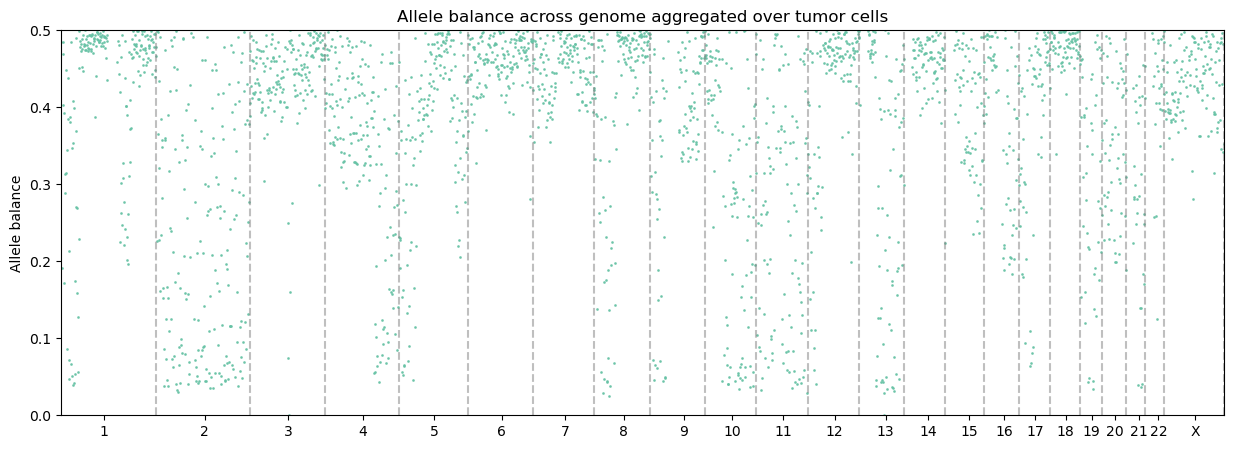

In [35]:
# plot the folded allele frequency along the genome
tumor_hap_ratio_sorted = tumor_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(tumor_hap_ratio_sorted['abspos'], tumor_hap_ratio_sorted['folded'], s=1, alpha=0.8)
#plt.xlabel('Chromosome')
plt.ylabel('Allele balance')
plt.title('Allele balance across genome aggregated over tumor cells')
# Add vertical lines for chromosome boundaries
chrom_boundaries = tumor_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = tumor_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(tumor_hap_ratio_sorted['abspos'].min(), tumor_hap_ratio_sorted['abspos'].max())
plt.show()

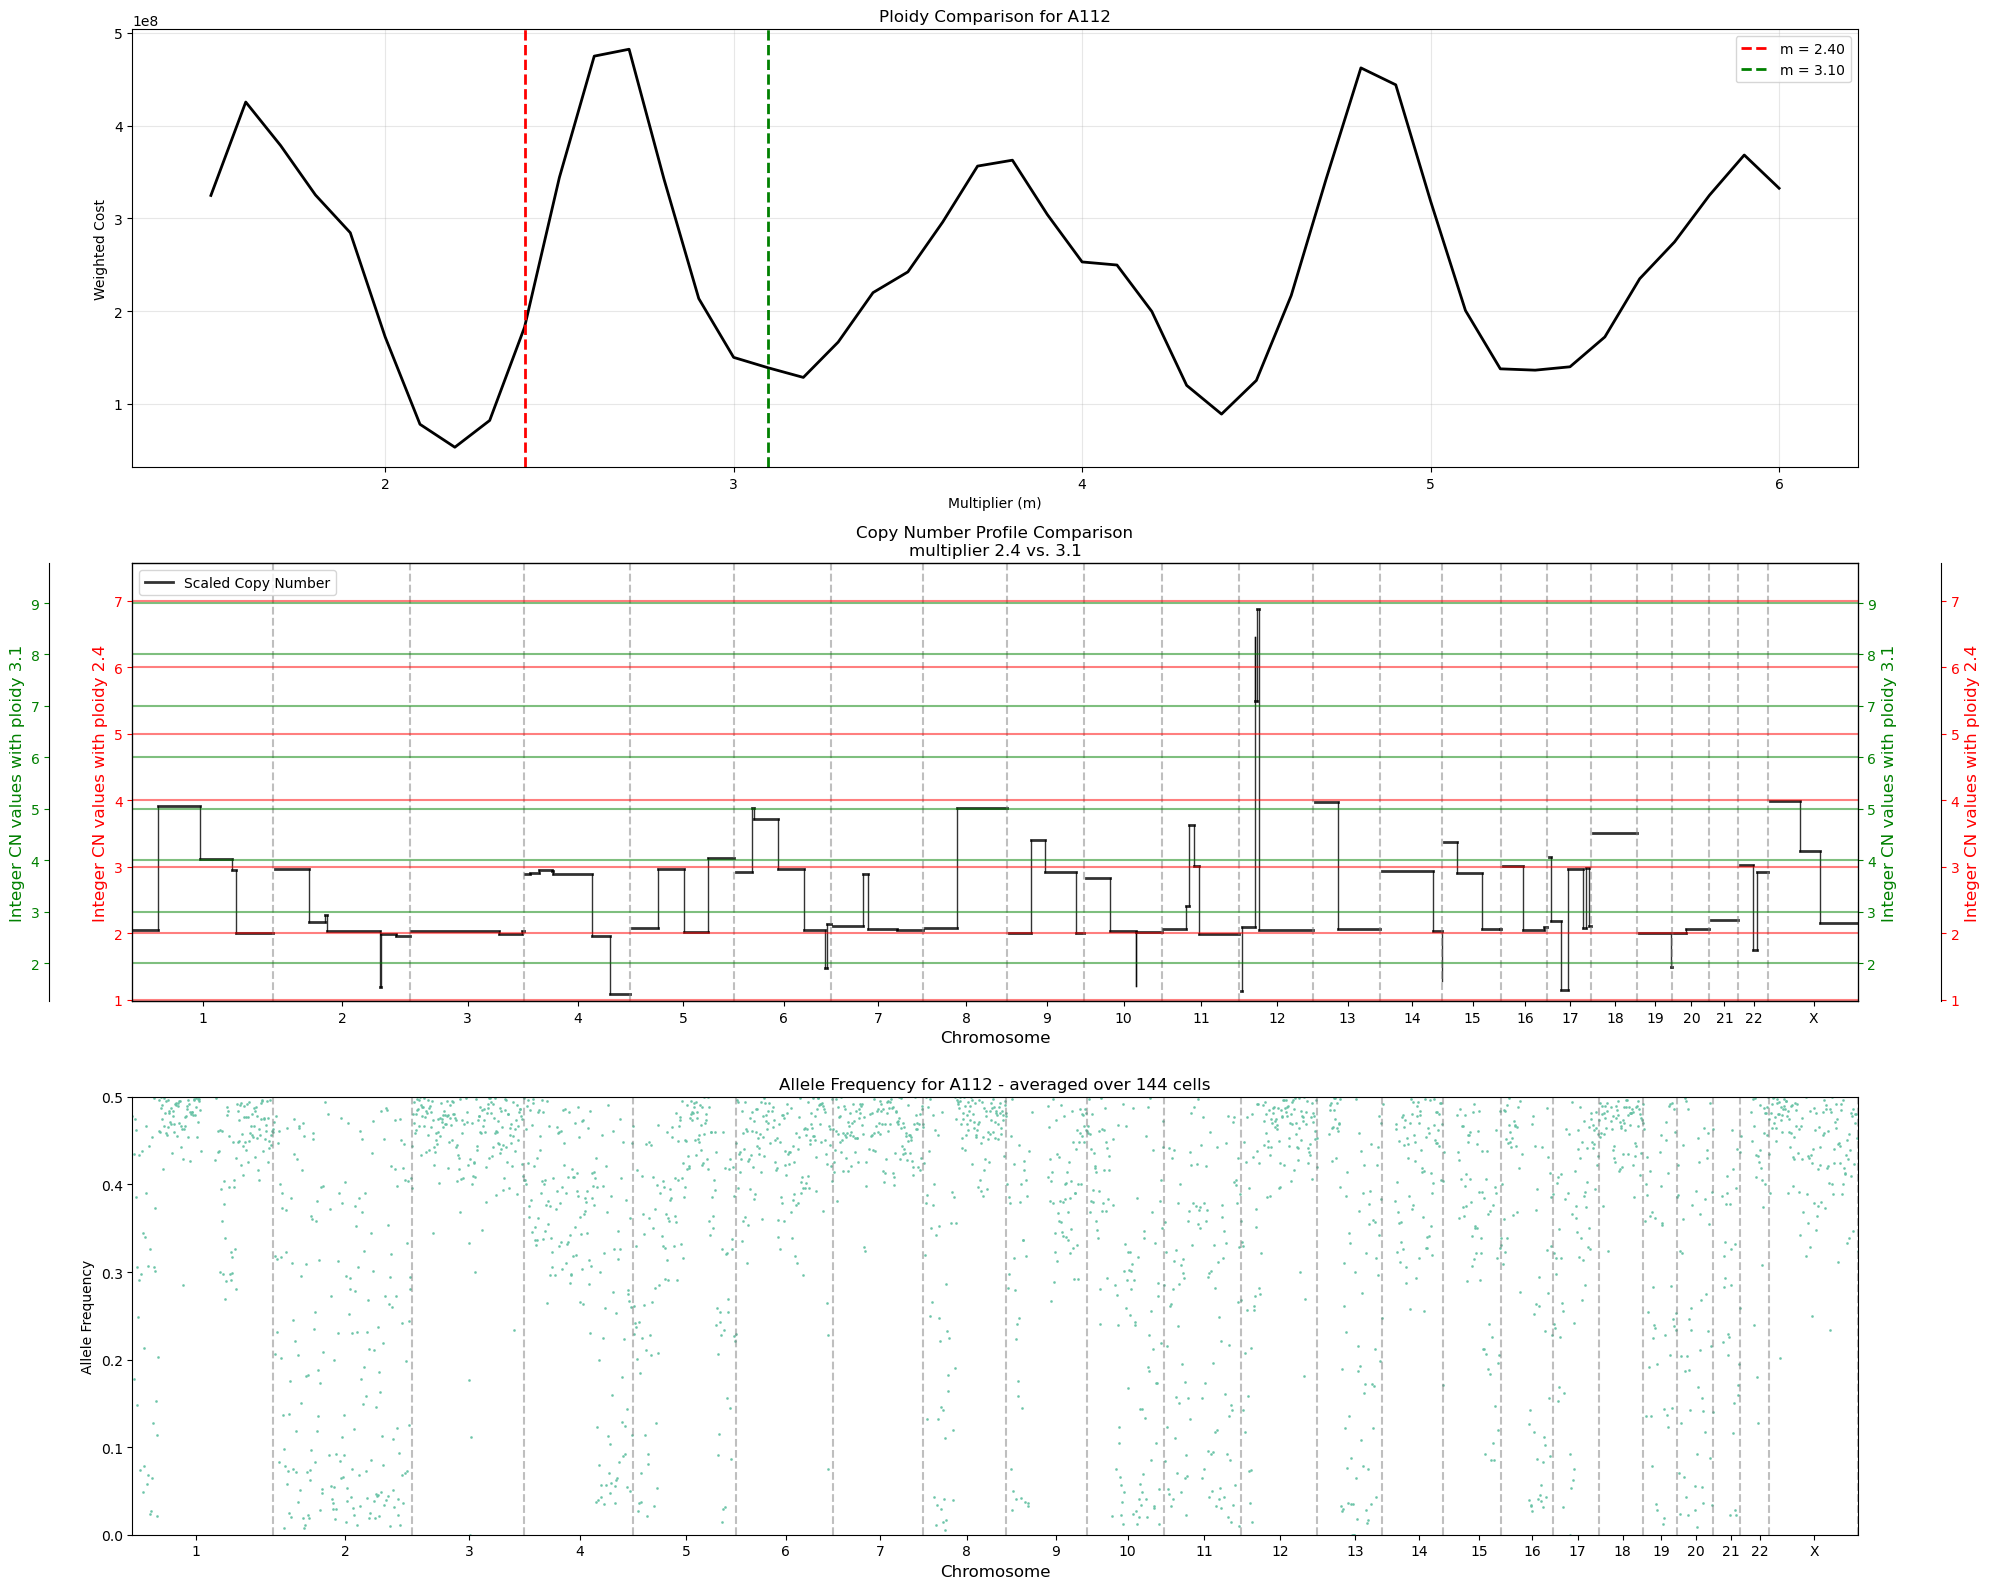

In [36]:
# Example usage for example with global min 2.4 and local min 3.1
plot_ploidy_comparison(
    results_df=profile_dfs_A[example],
    cost_results=ploidy_results_A[example]['cost_results'],
    optimal_m=2.4,
    local_m=3.1,
    pop_col=example + '_ratio',
    hap_count_df=hap_count_df,
    cells=A_dict[example]['cells']
)


Creating ploidy comparison for population: A111


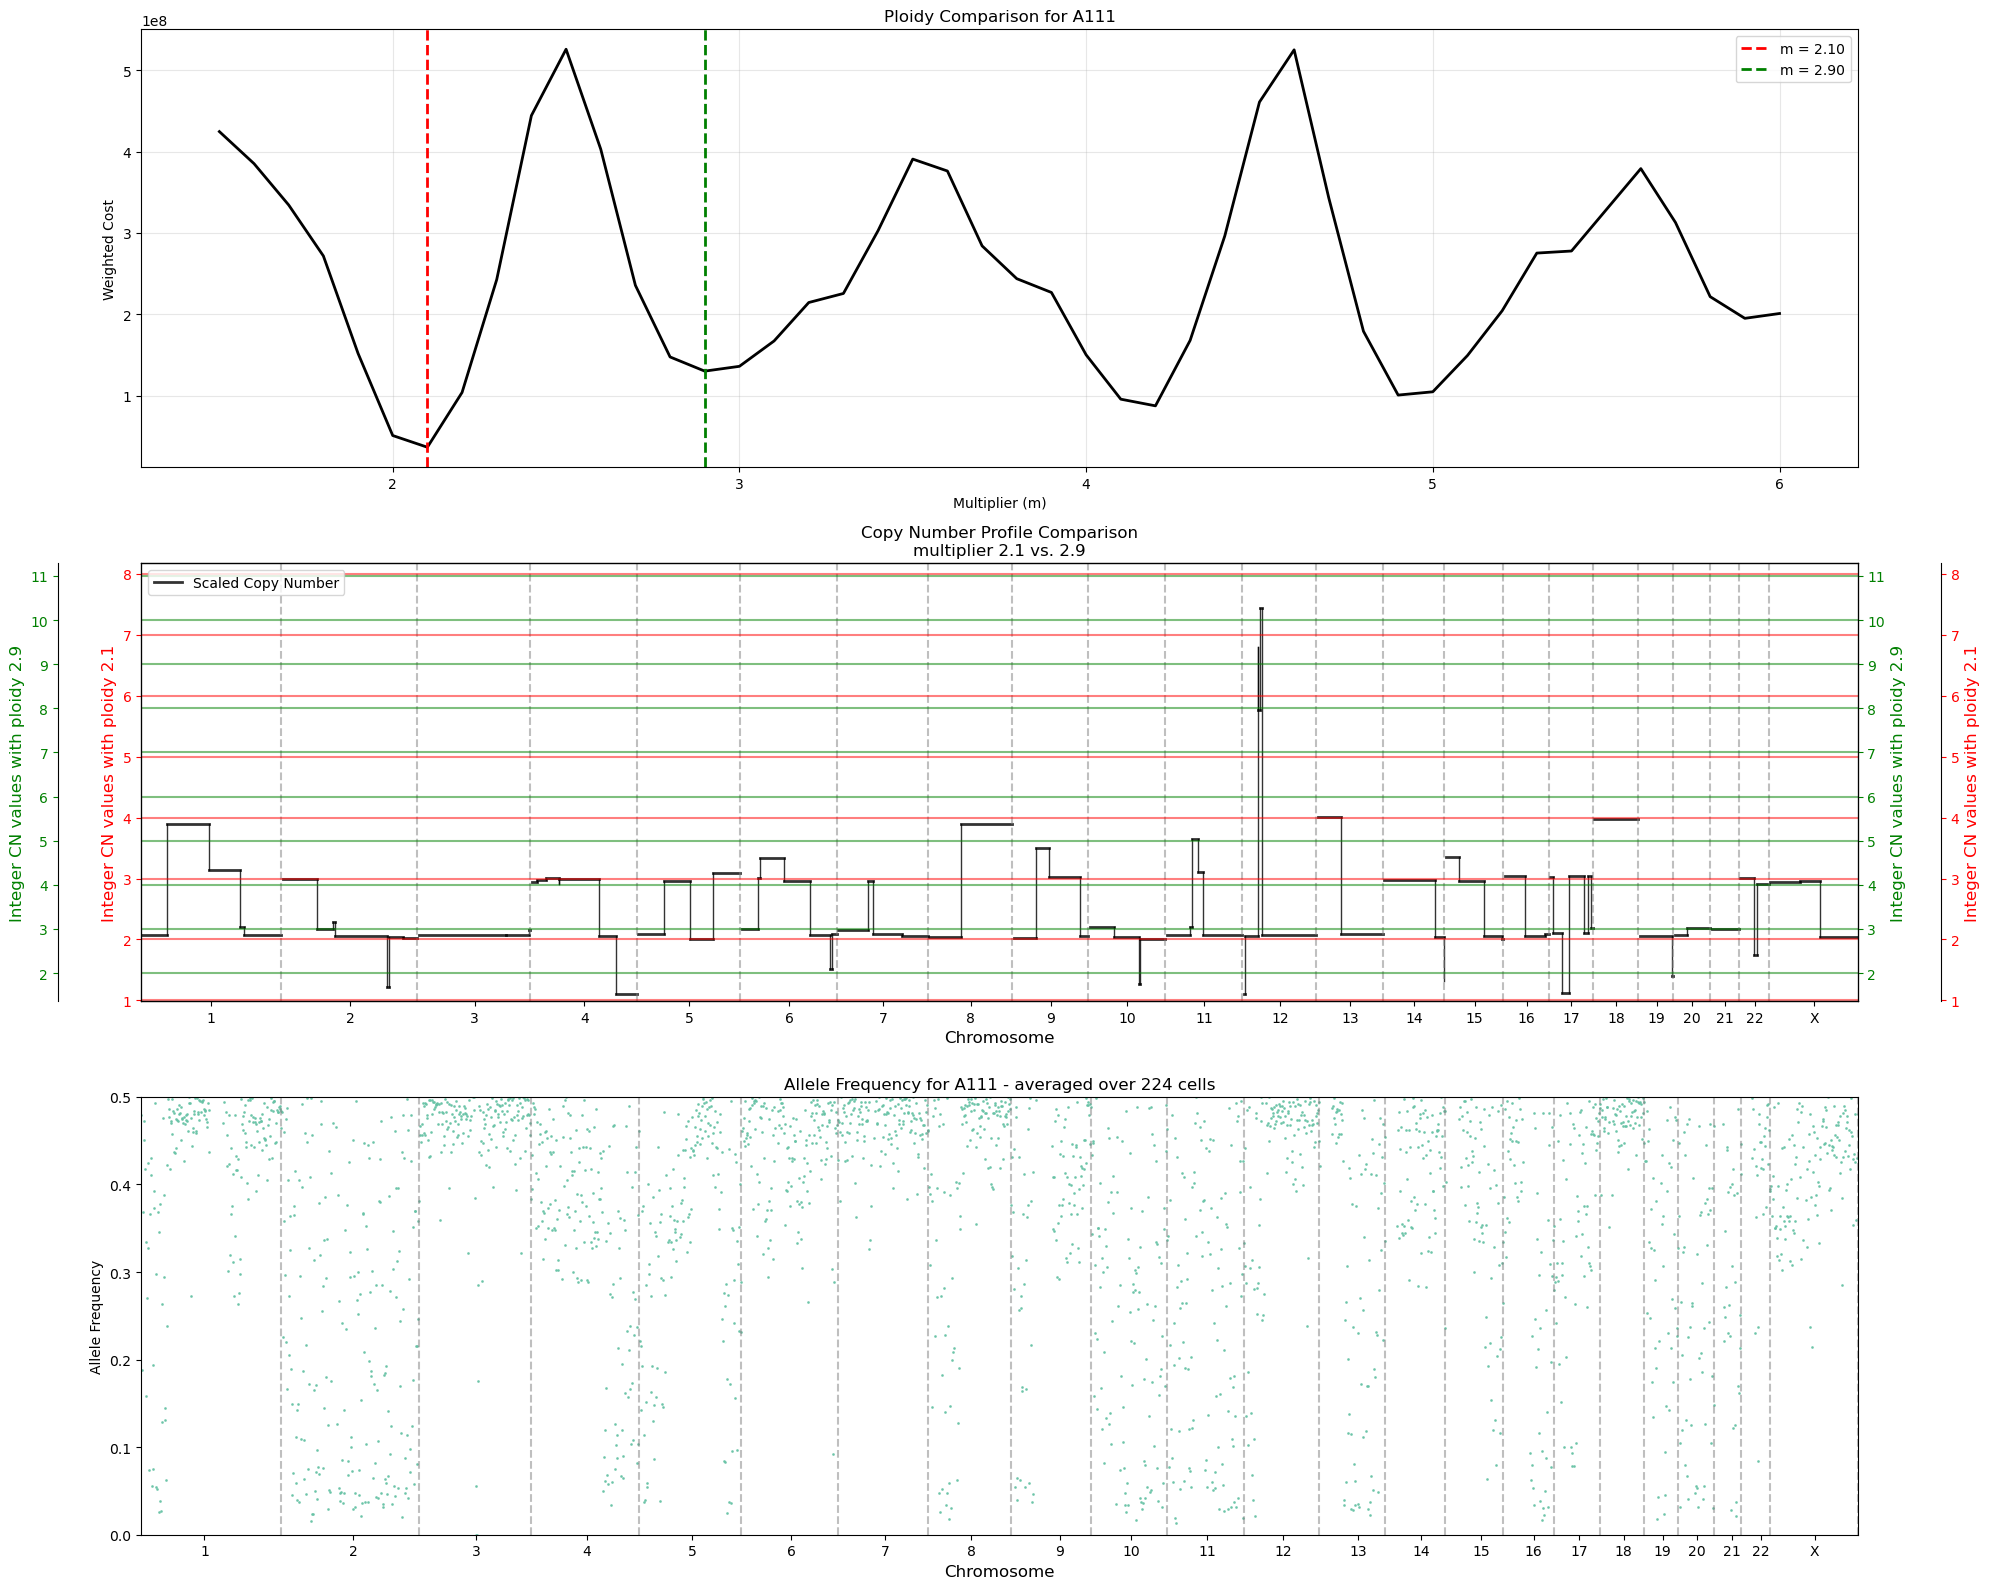

Compared 2.10 vs 2.90 for A111

Creating ploidy comparison for population: A112


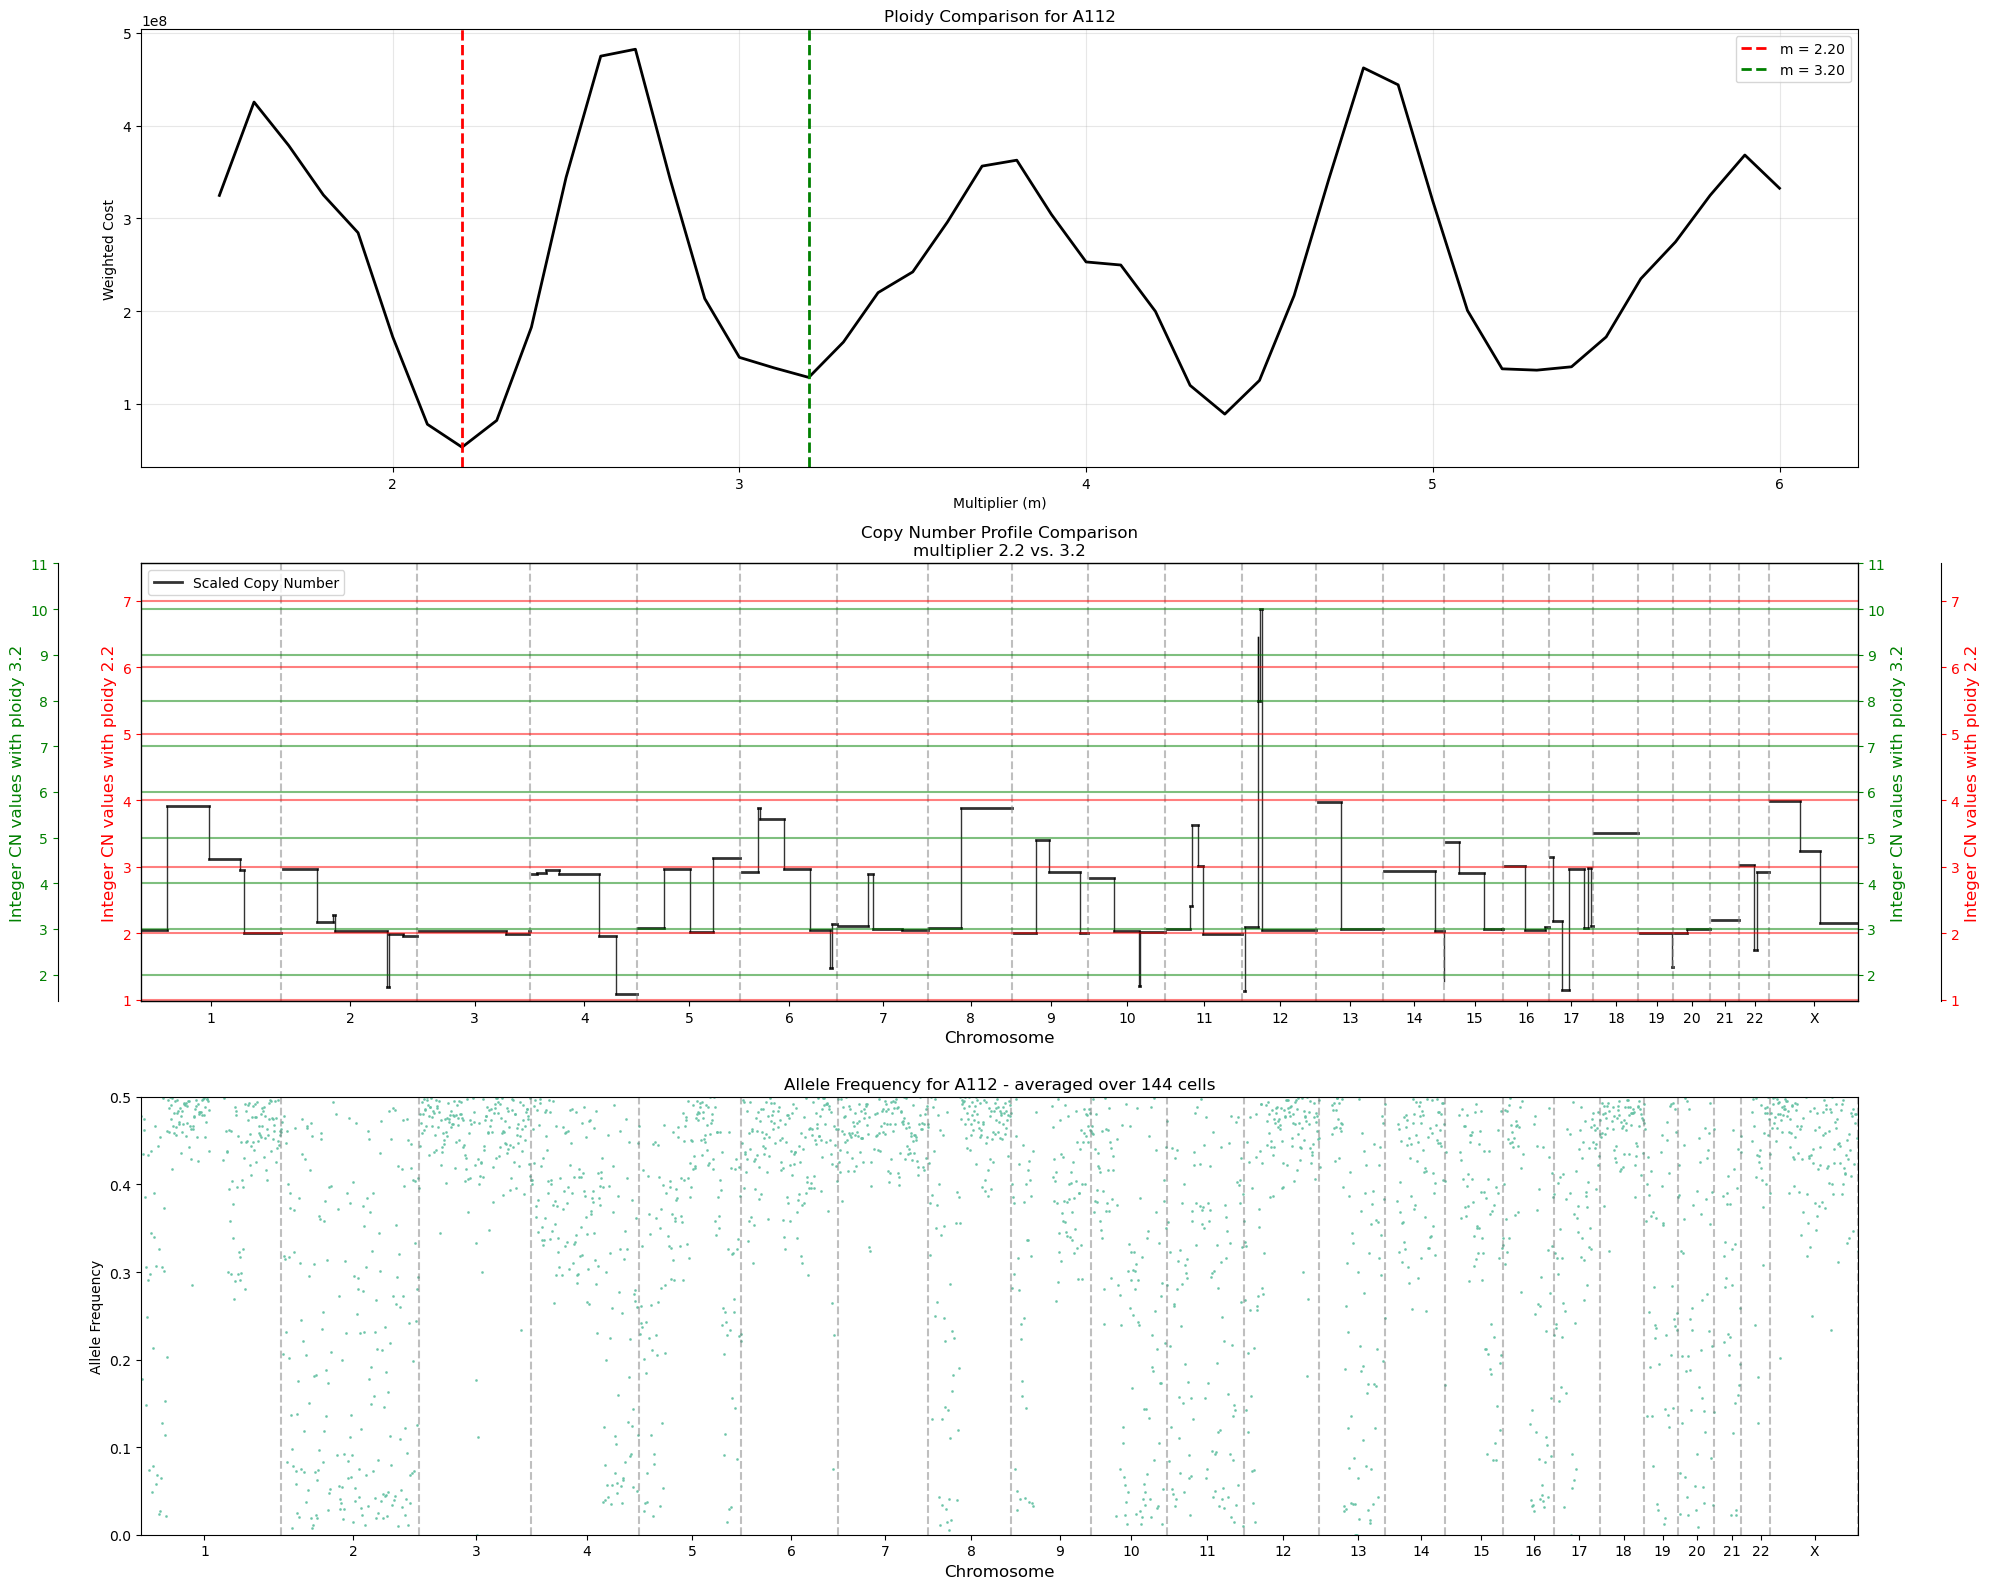

Compared 2.20 vs 3.20 for A112

Creating ploidy comparison for population: A1211


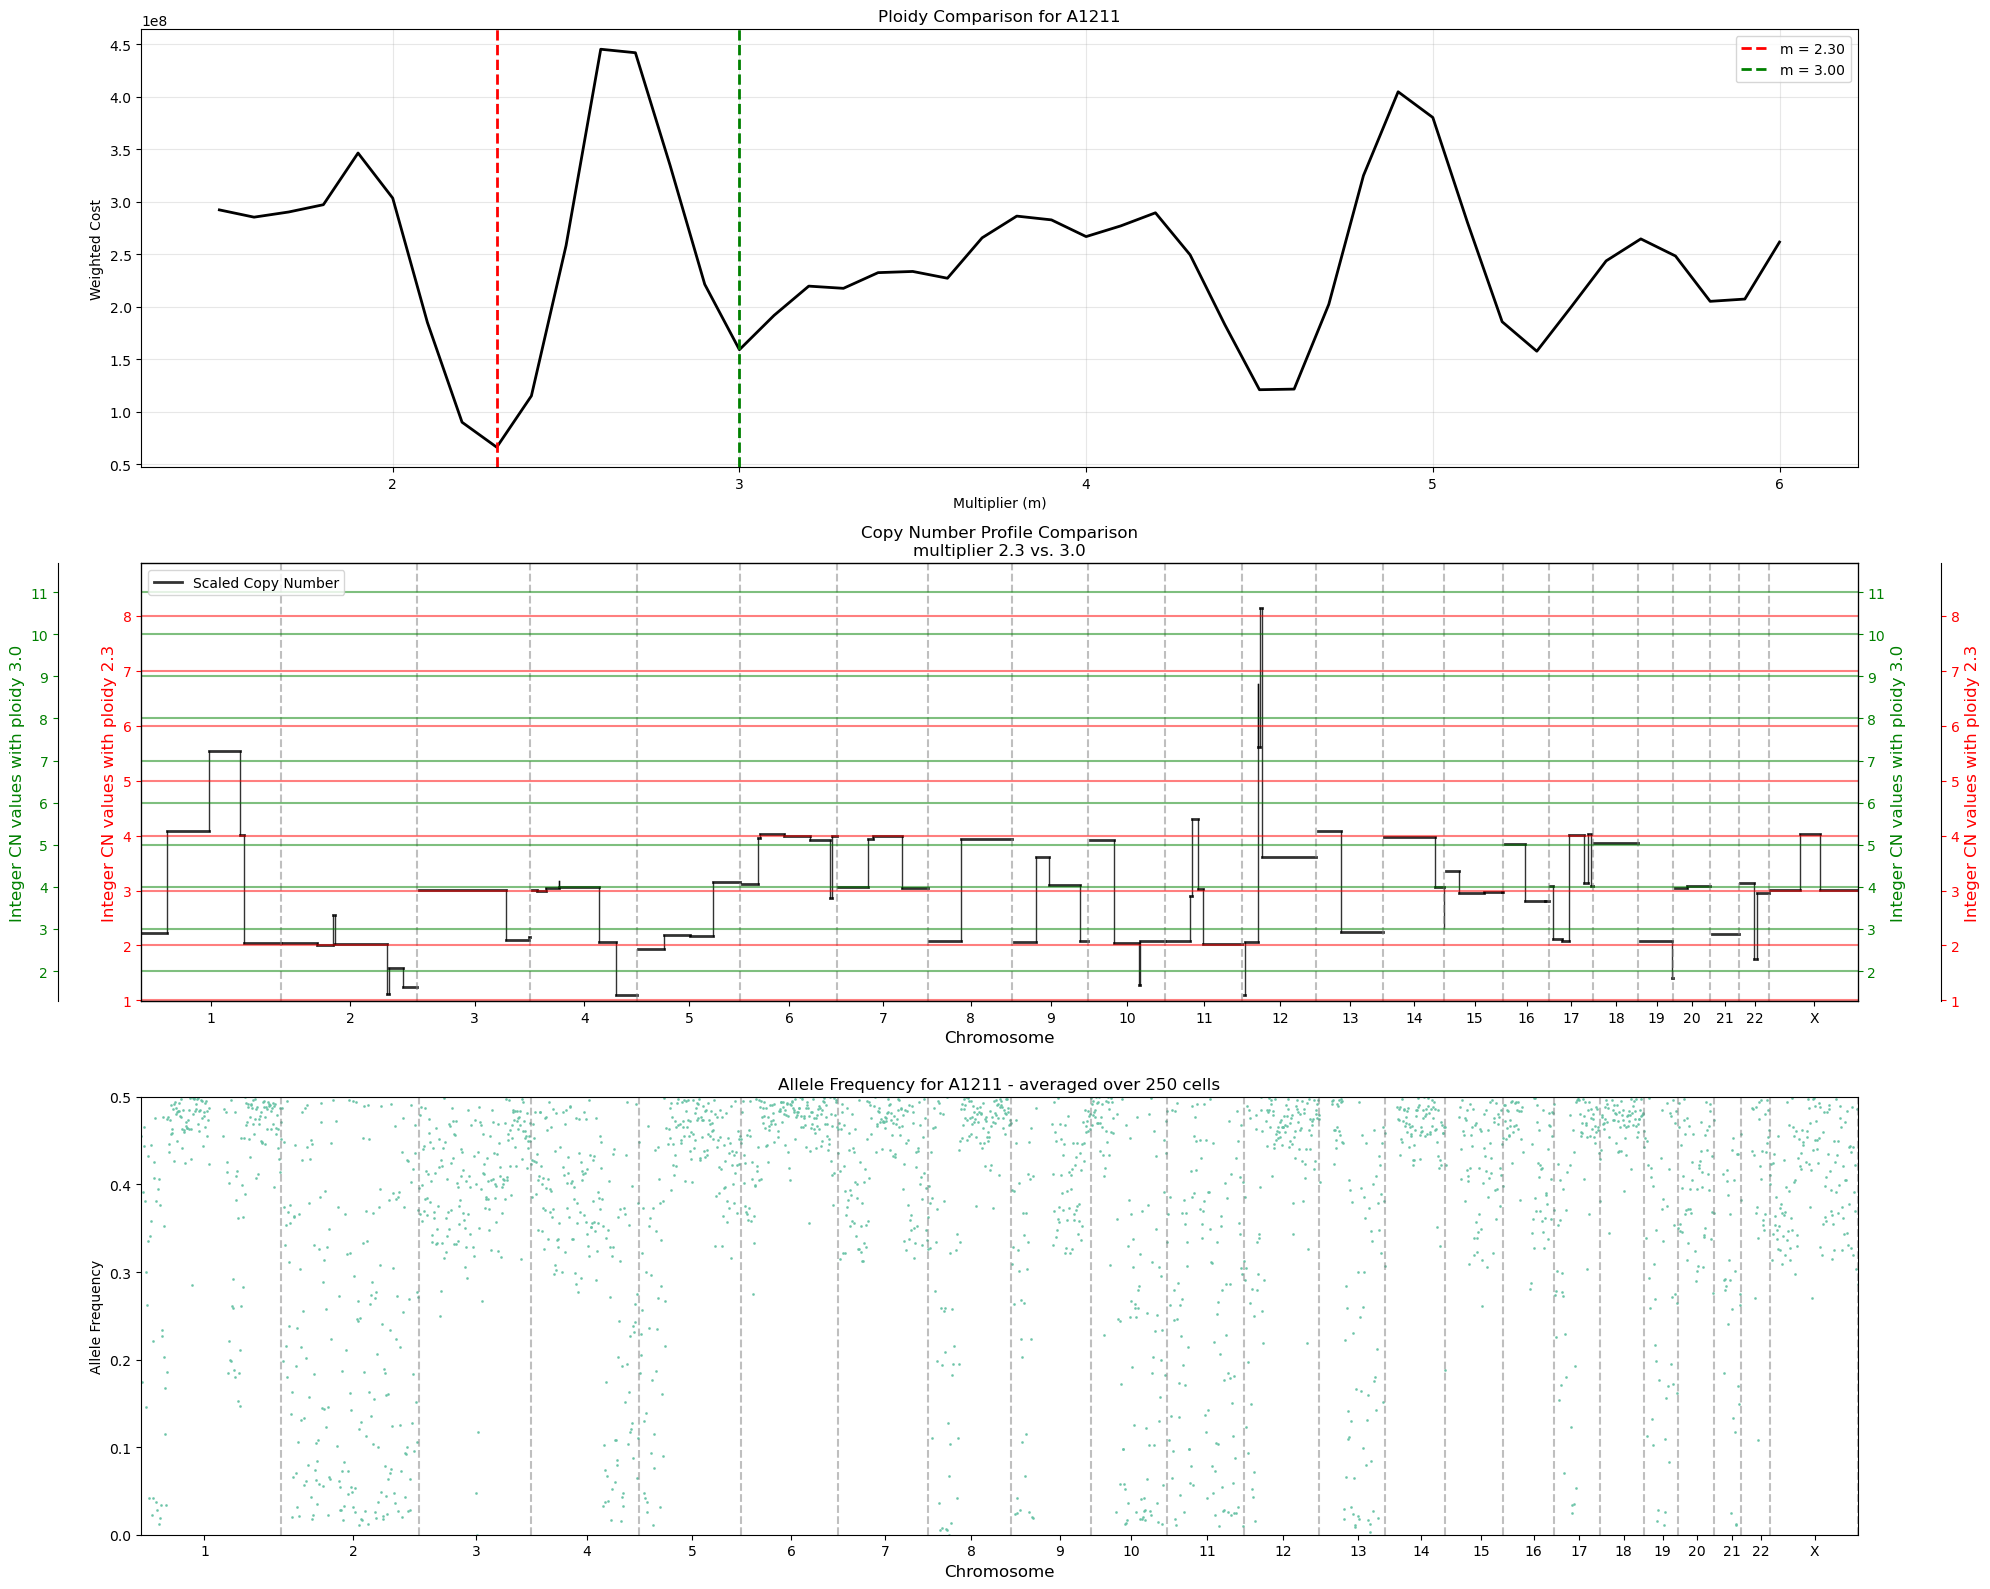

Compared 2.30 vs 3.00 for A1211

Creating ploidy comparison for population: A1212


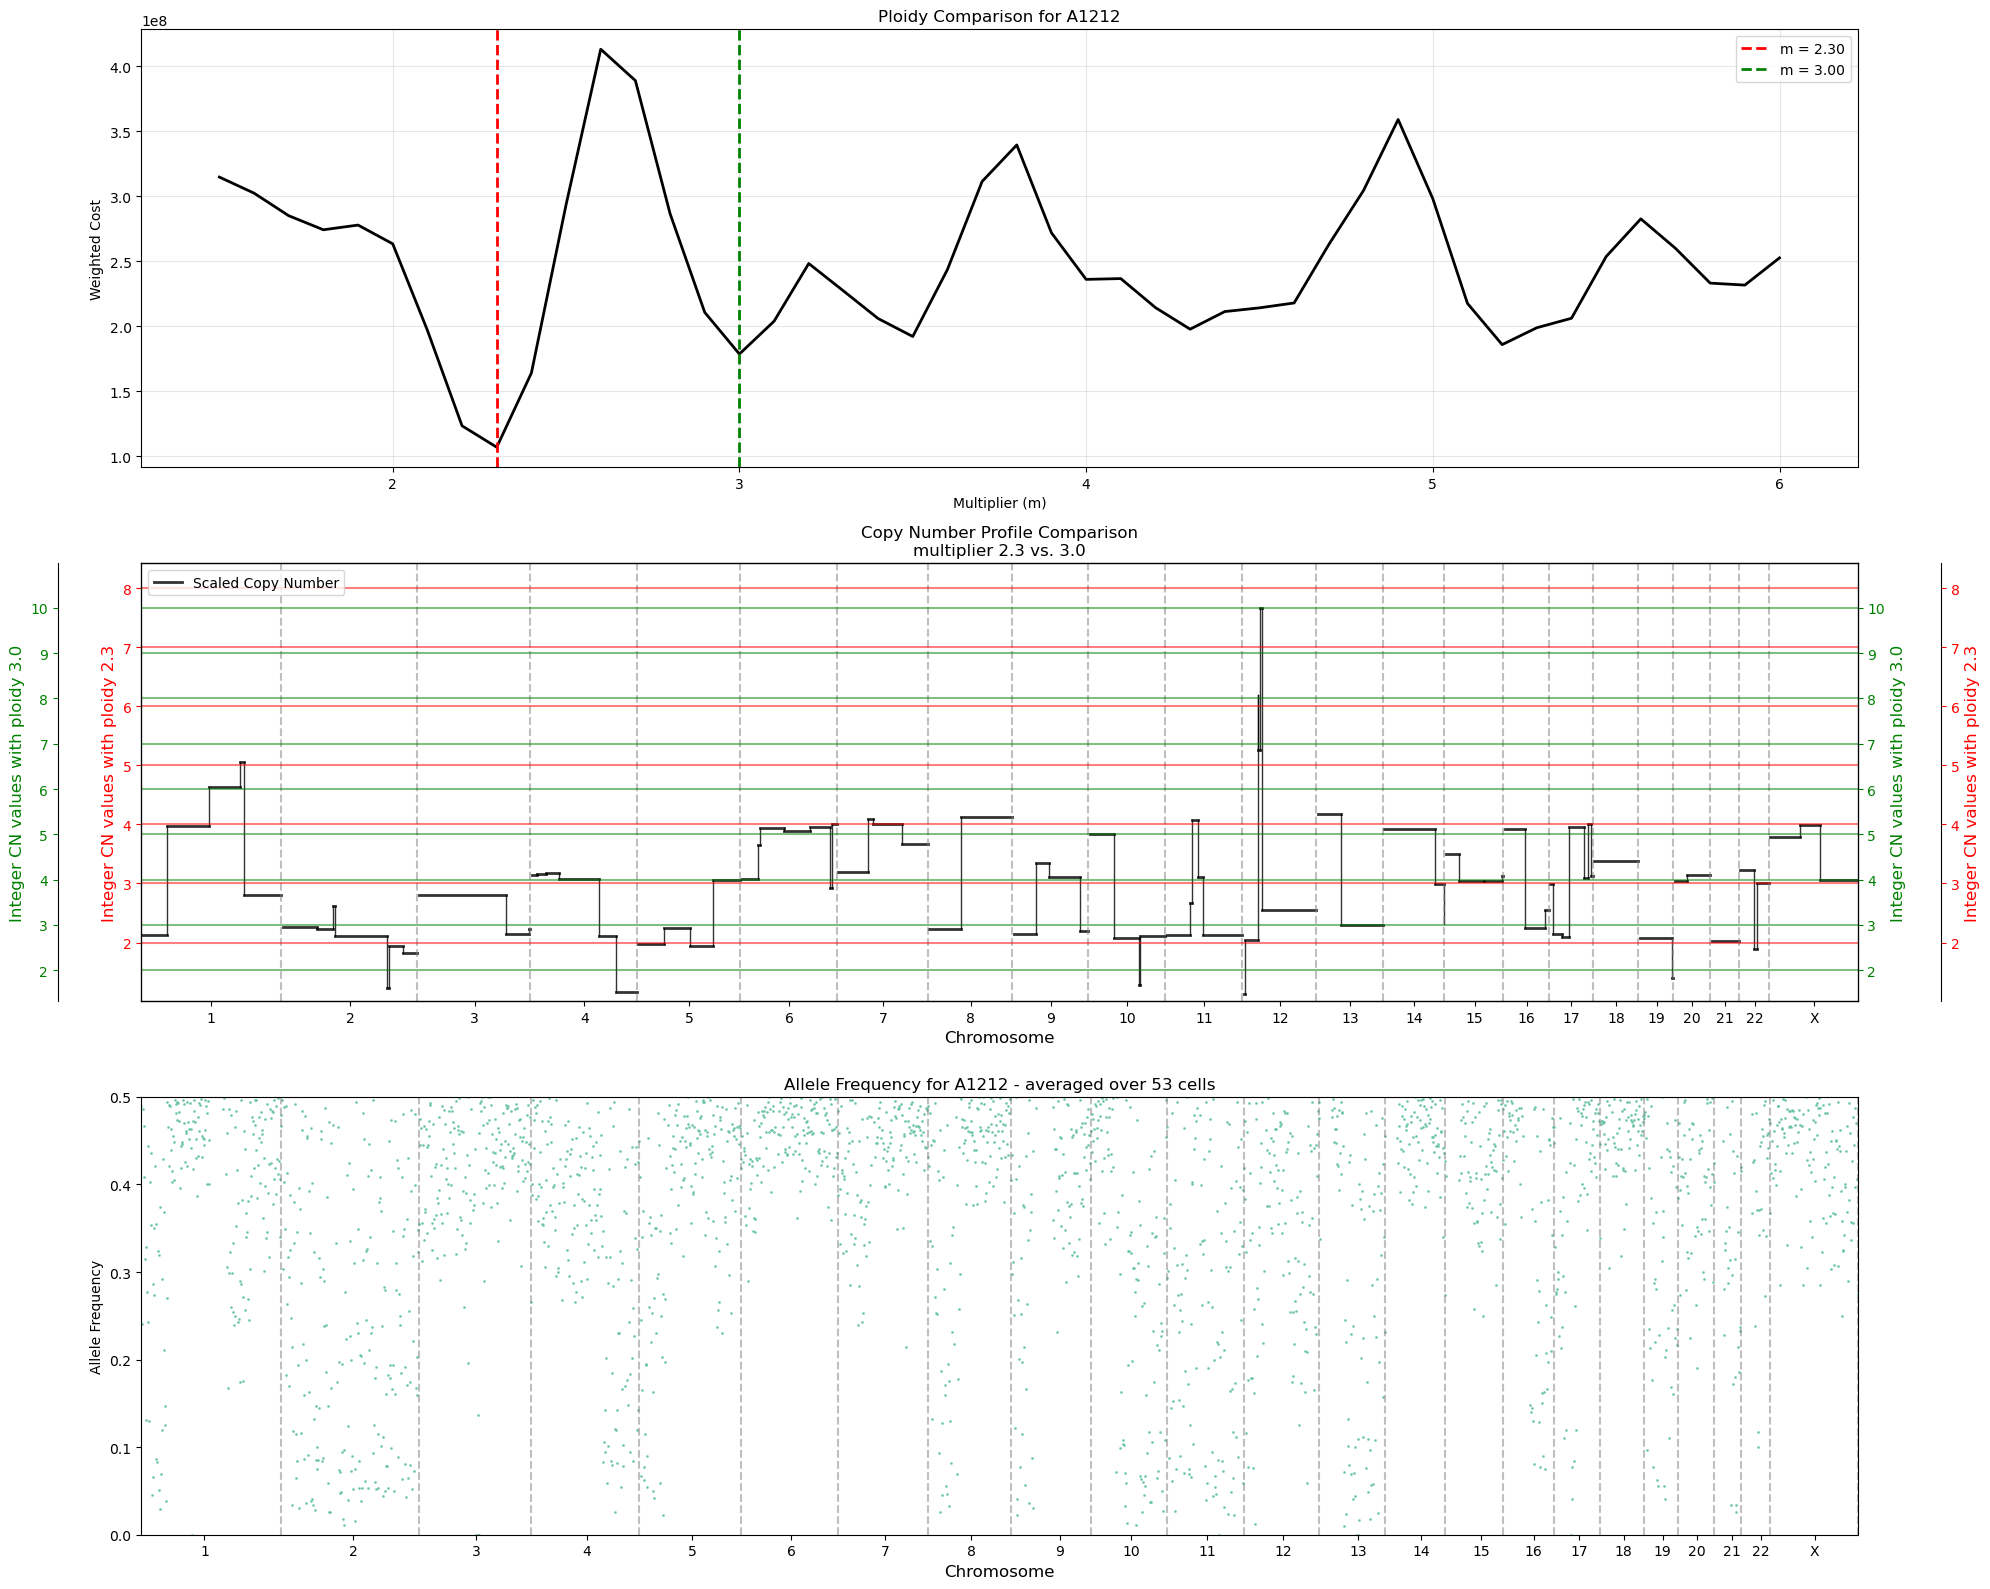

Compared 2.30 vs 3.00 for A1212

Creating ploidy comparison for population: A1221


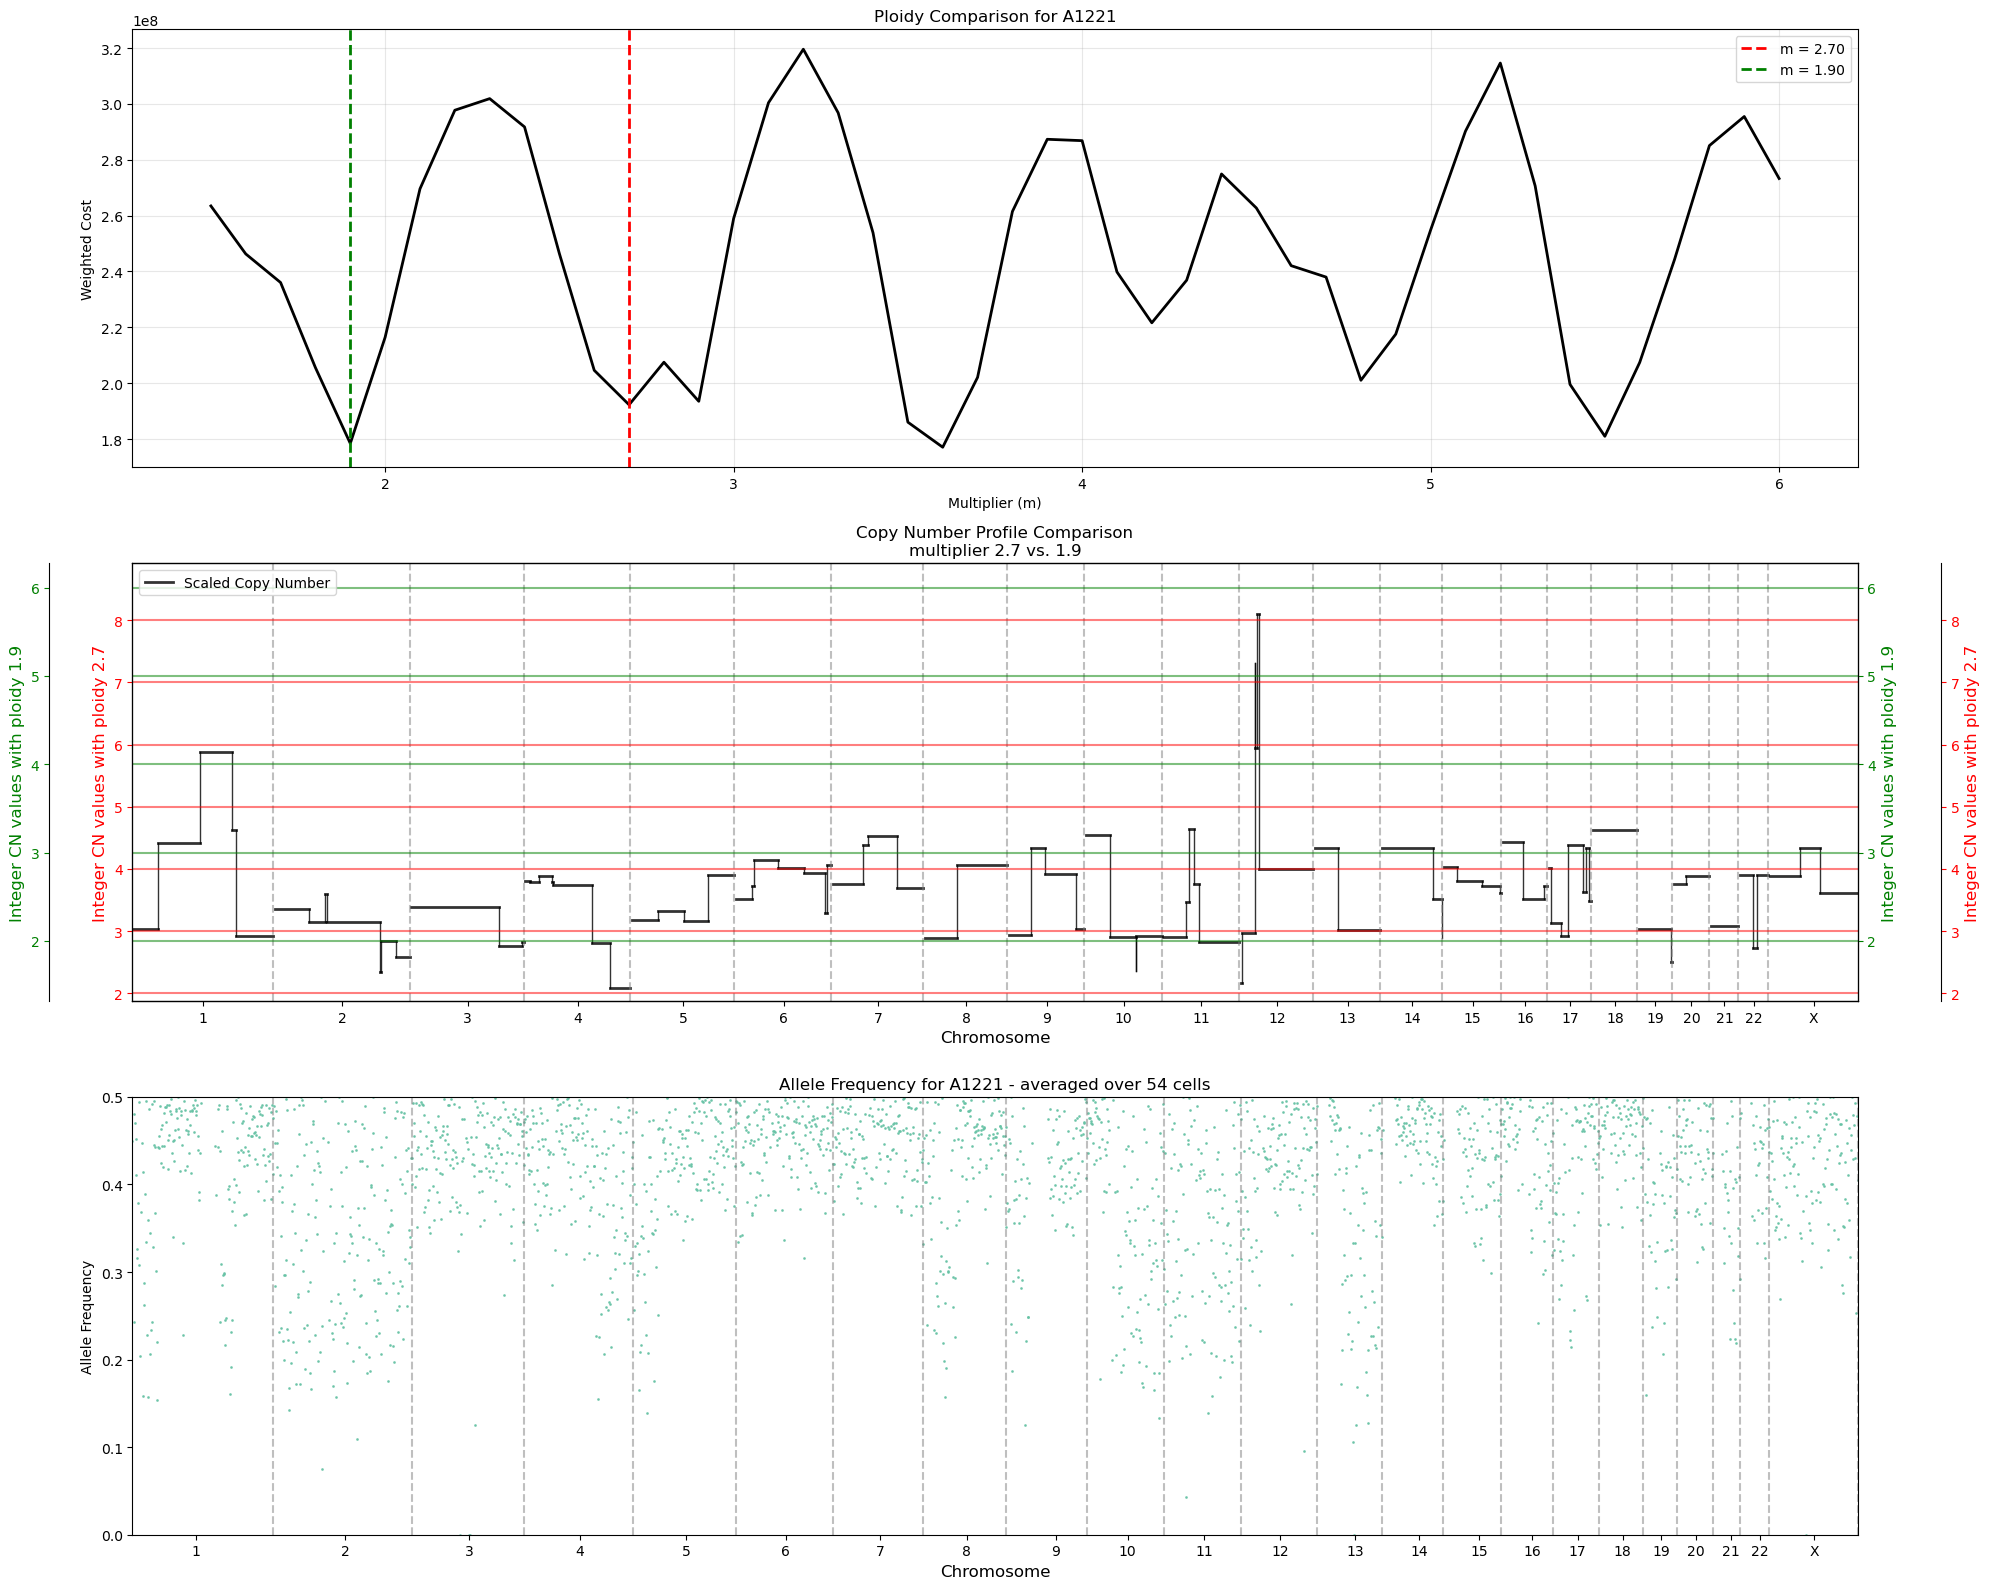

Compared 2.70 vs 1.90 for A1221

Creating ploidy comparison for population: A1222


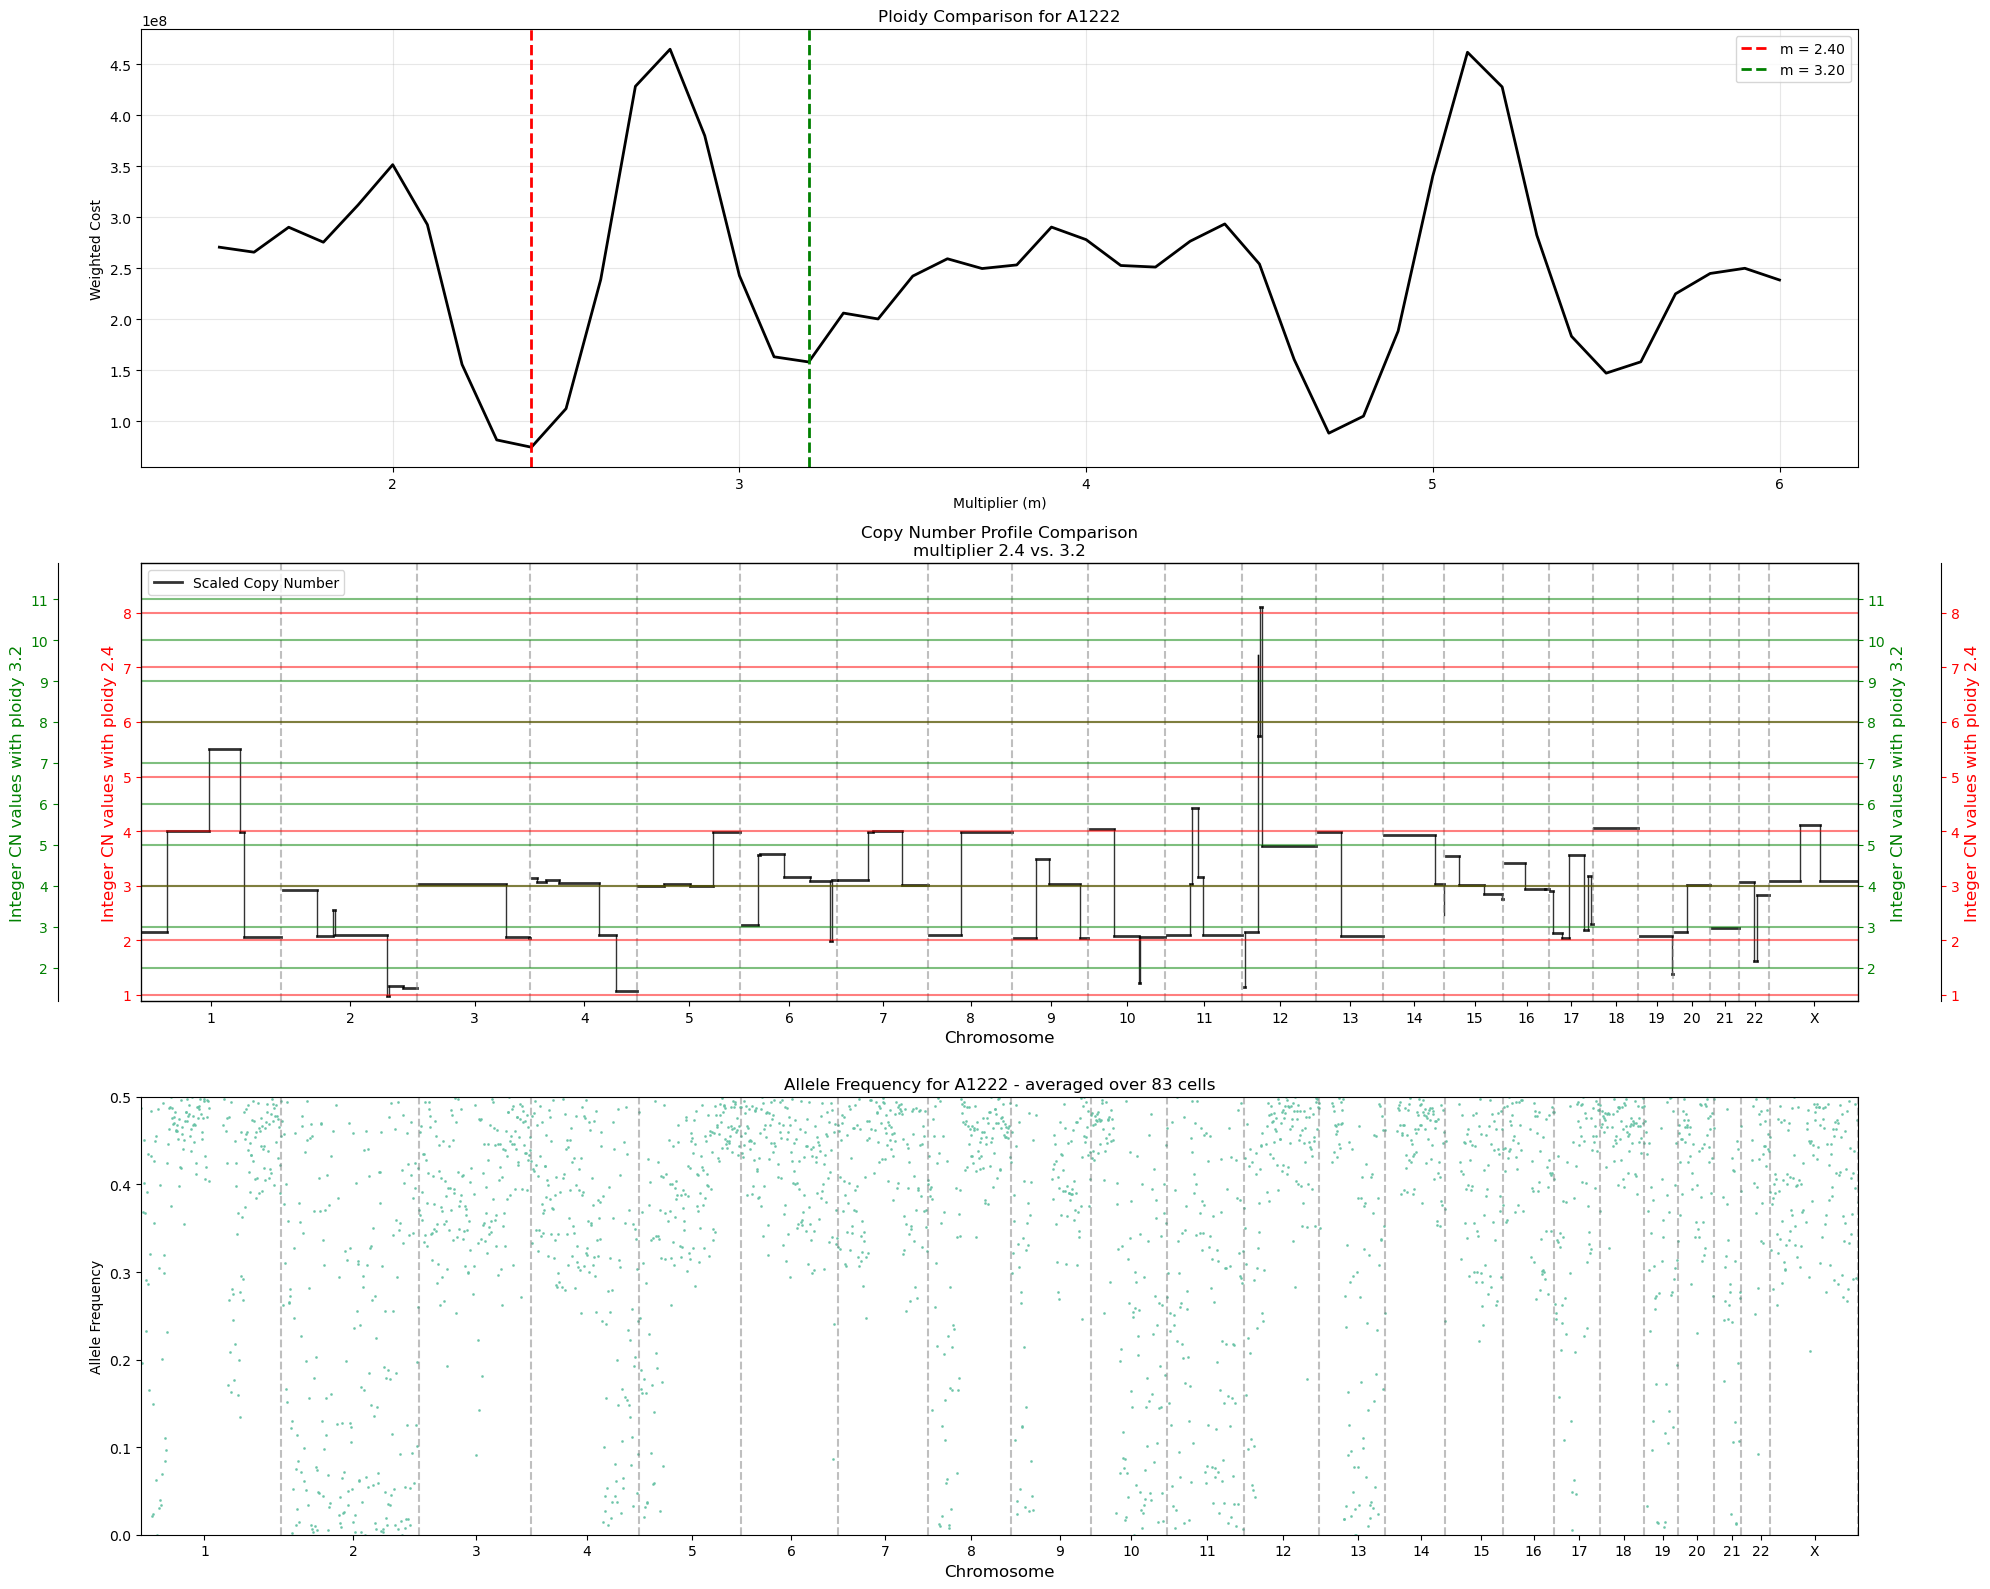

Compared 2.40 vs 3.20 for A1222


In [37]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to ploidy 2 (that's not the global minimum)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Pick the one closest to 2.0
        second_best_m = min(other_minima, key=lambda x: abs(x - 2.0))
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")


Creating ploidy comparison for population: A111


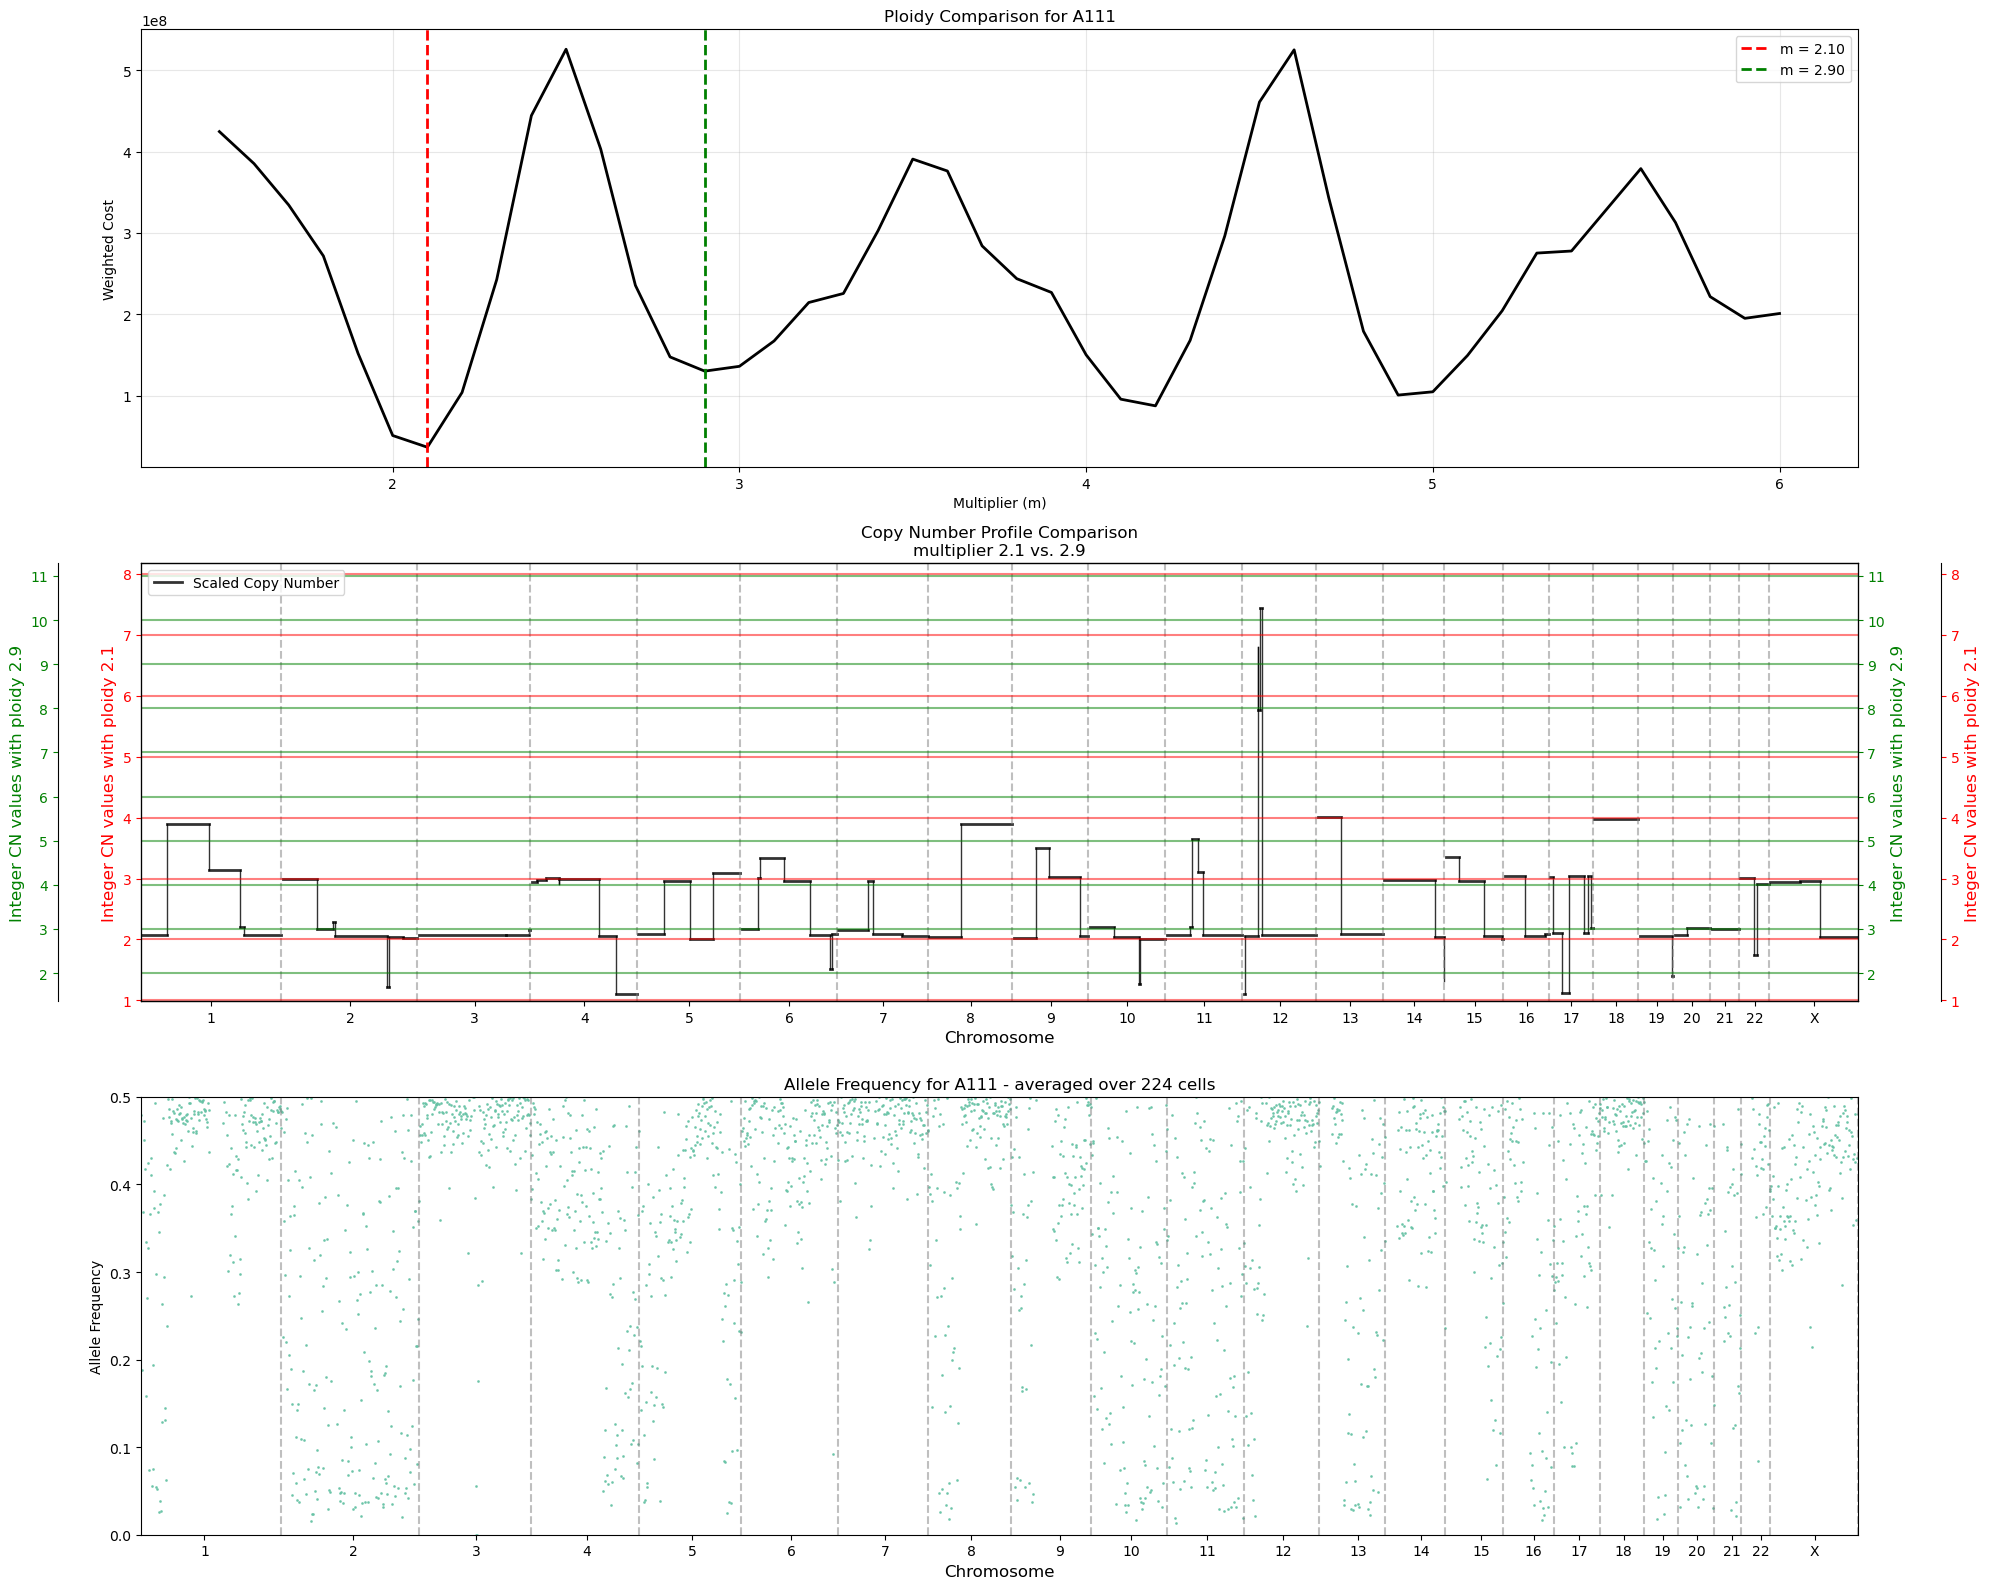

Compared 2.10 vs 2.90 for A111

Creating ploidy comparison for population: A112


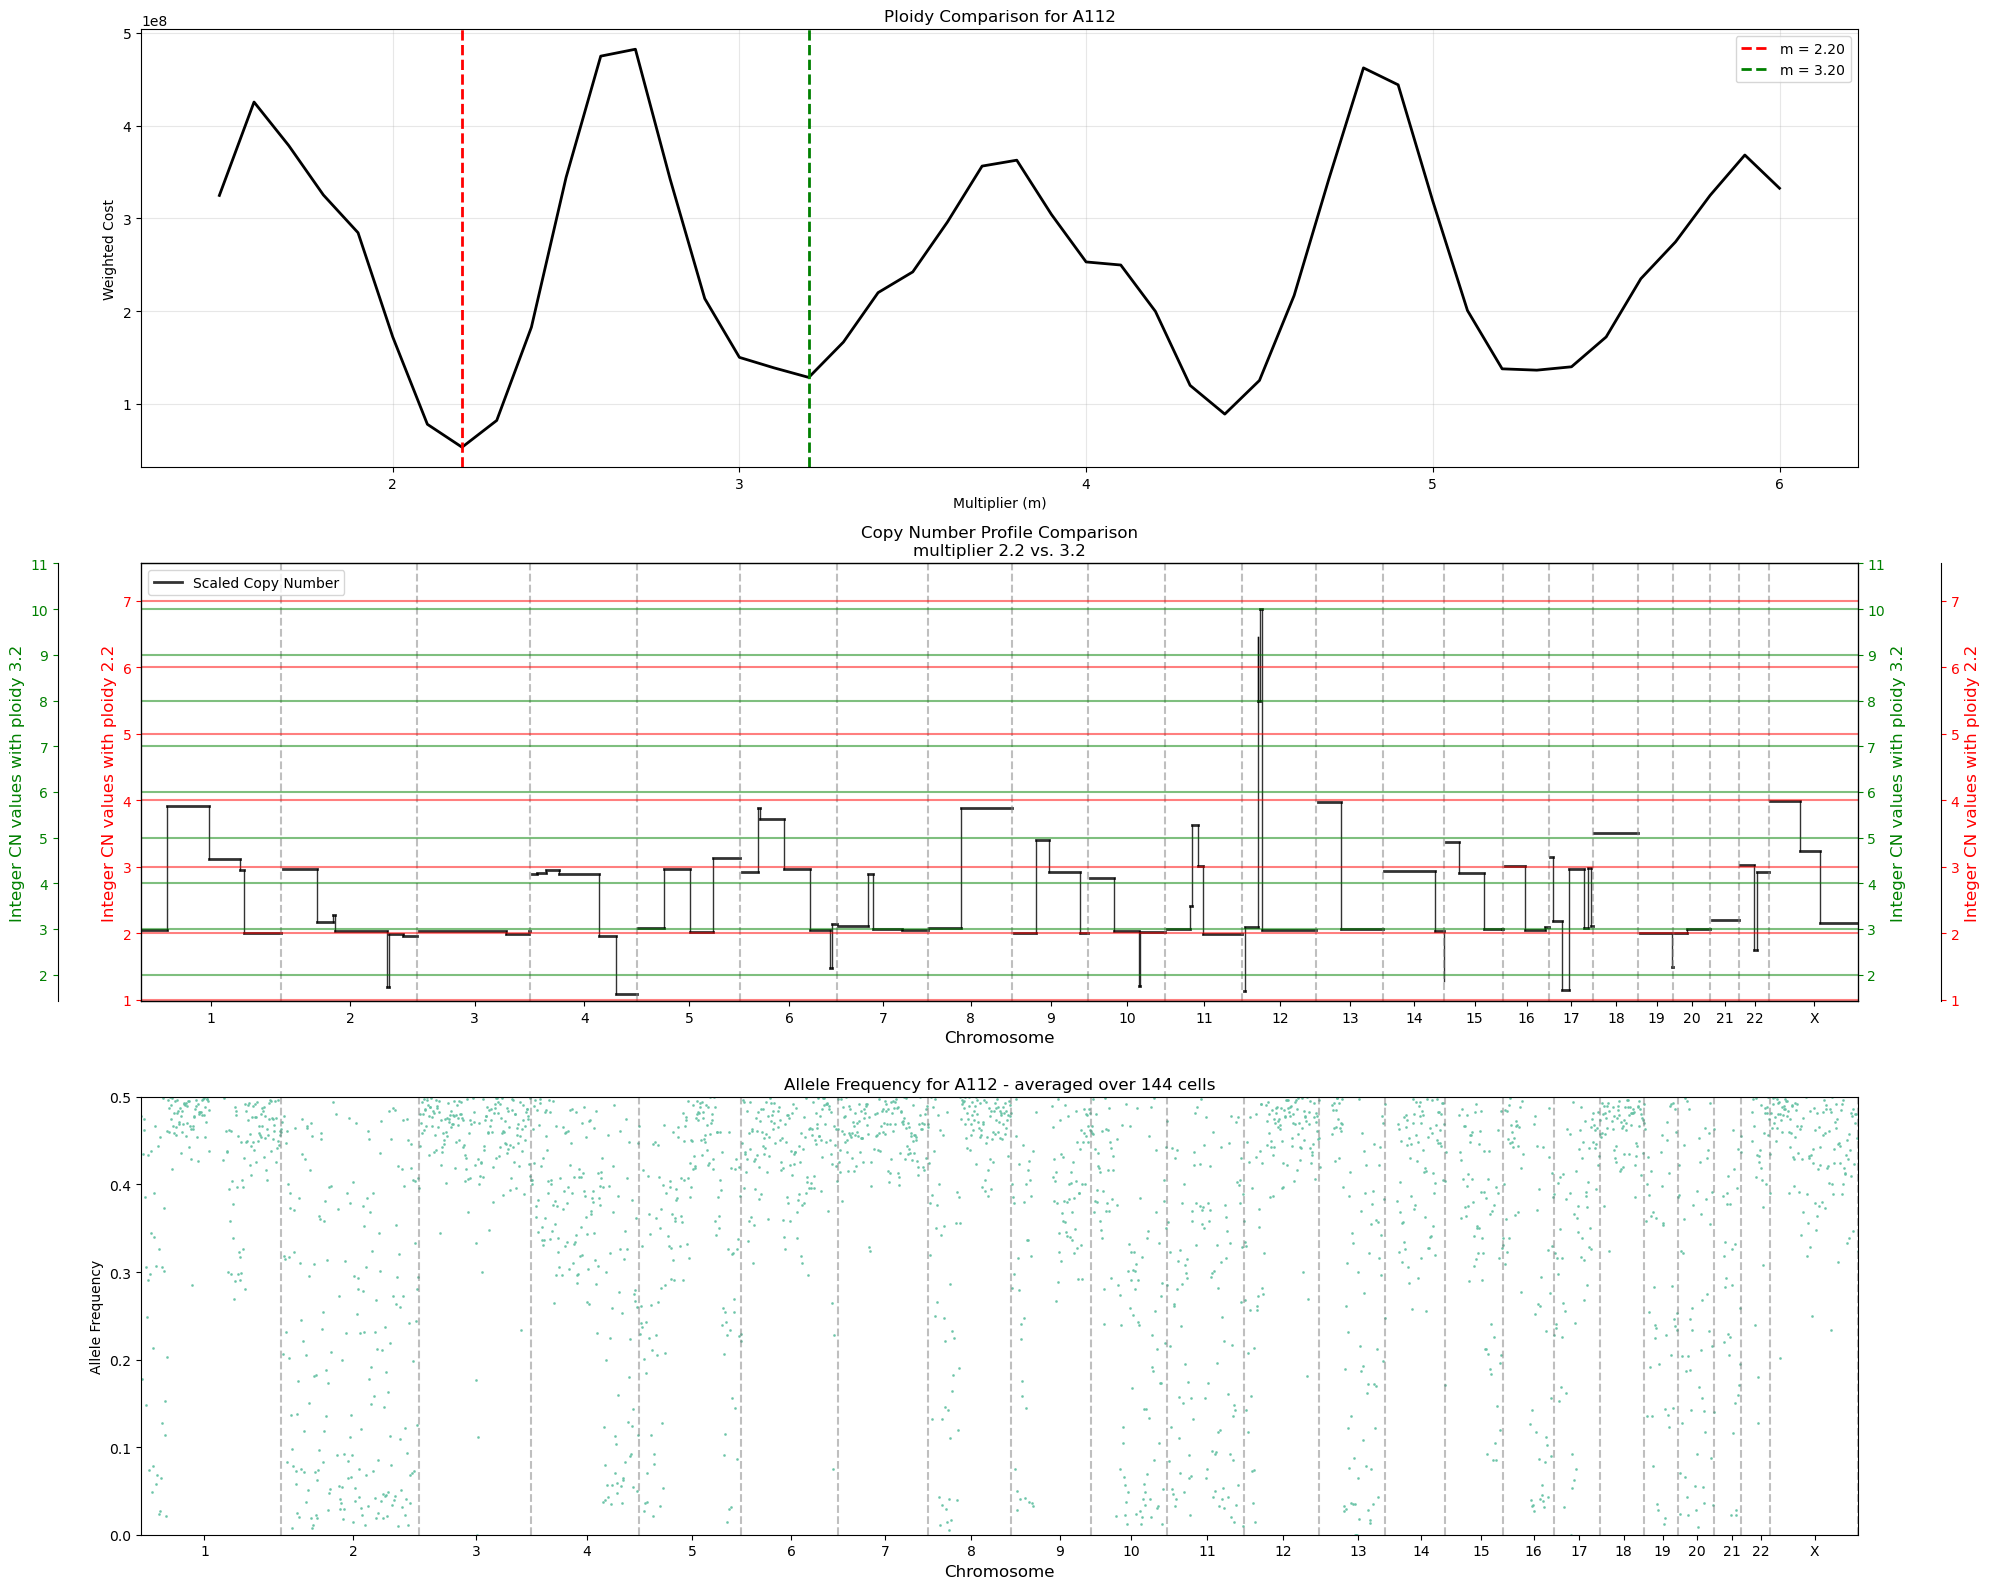

Compared 2.20 vs 3.20 for A112

Creating ploidy comparison for population: A1211


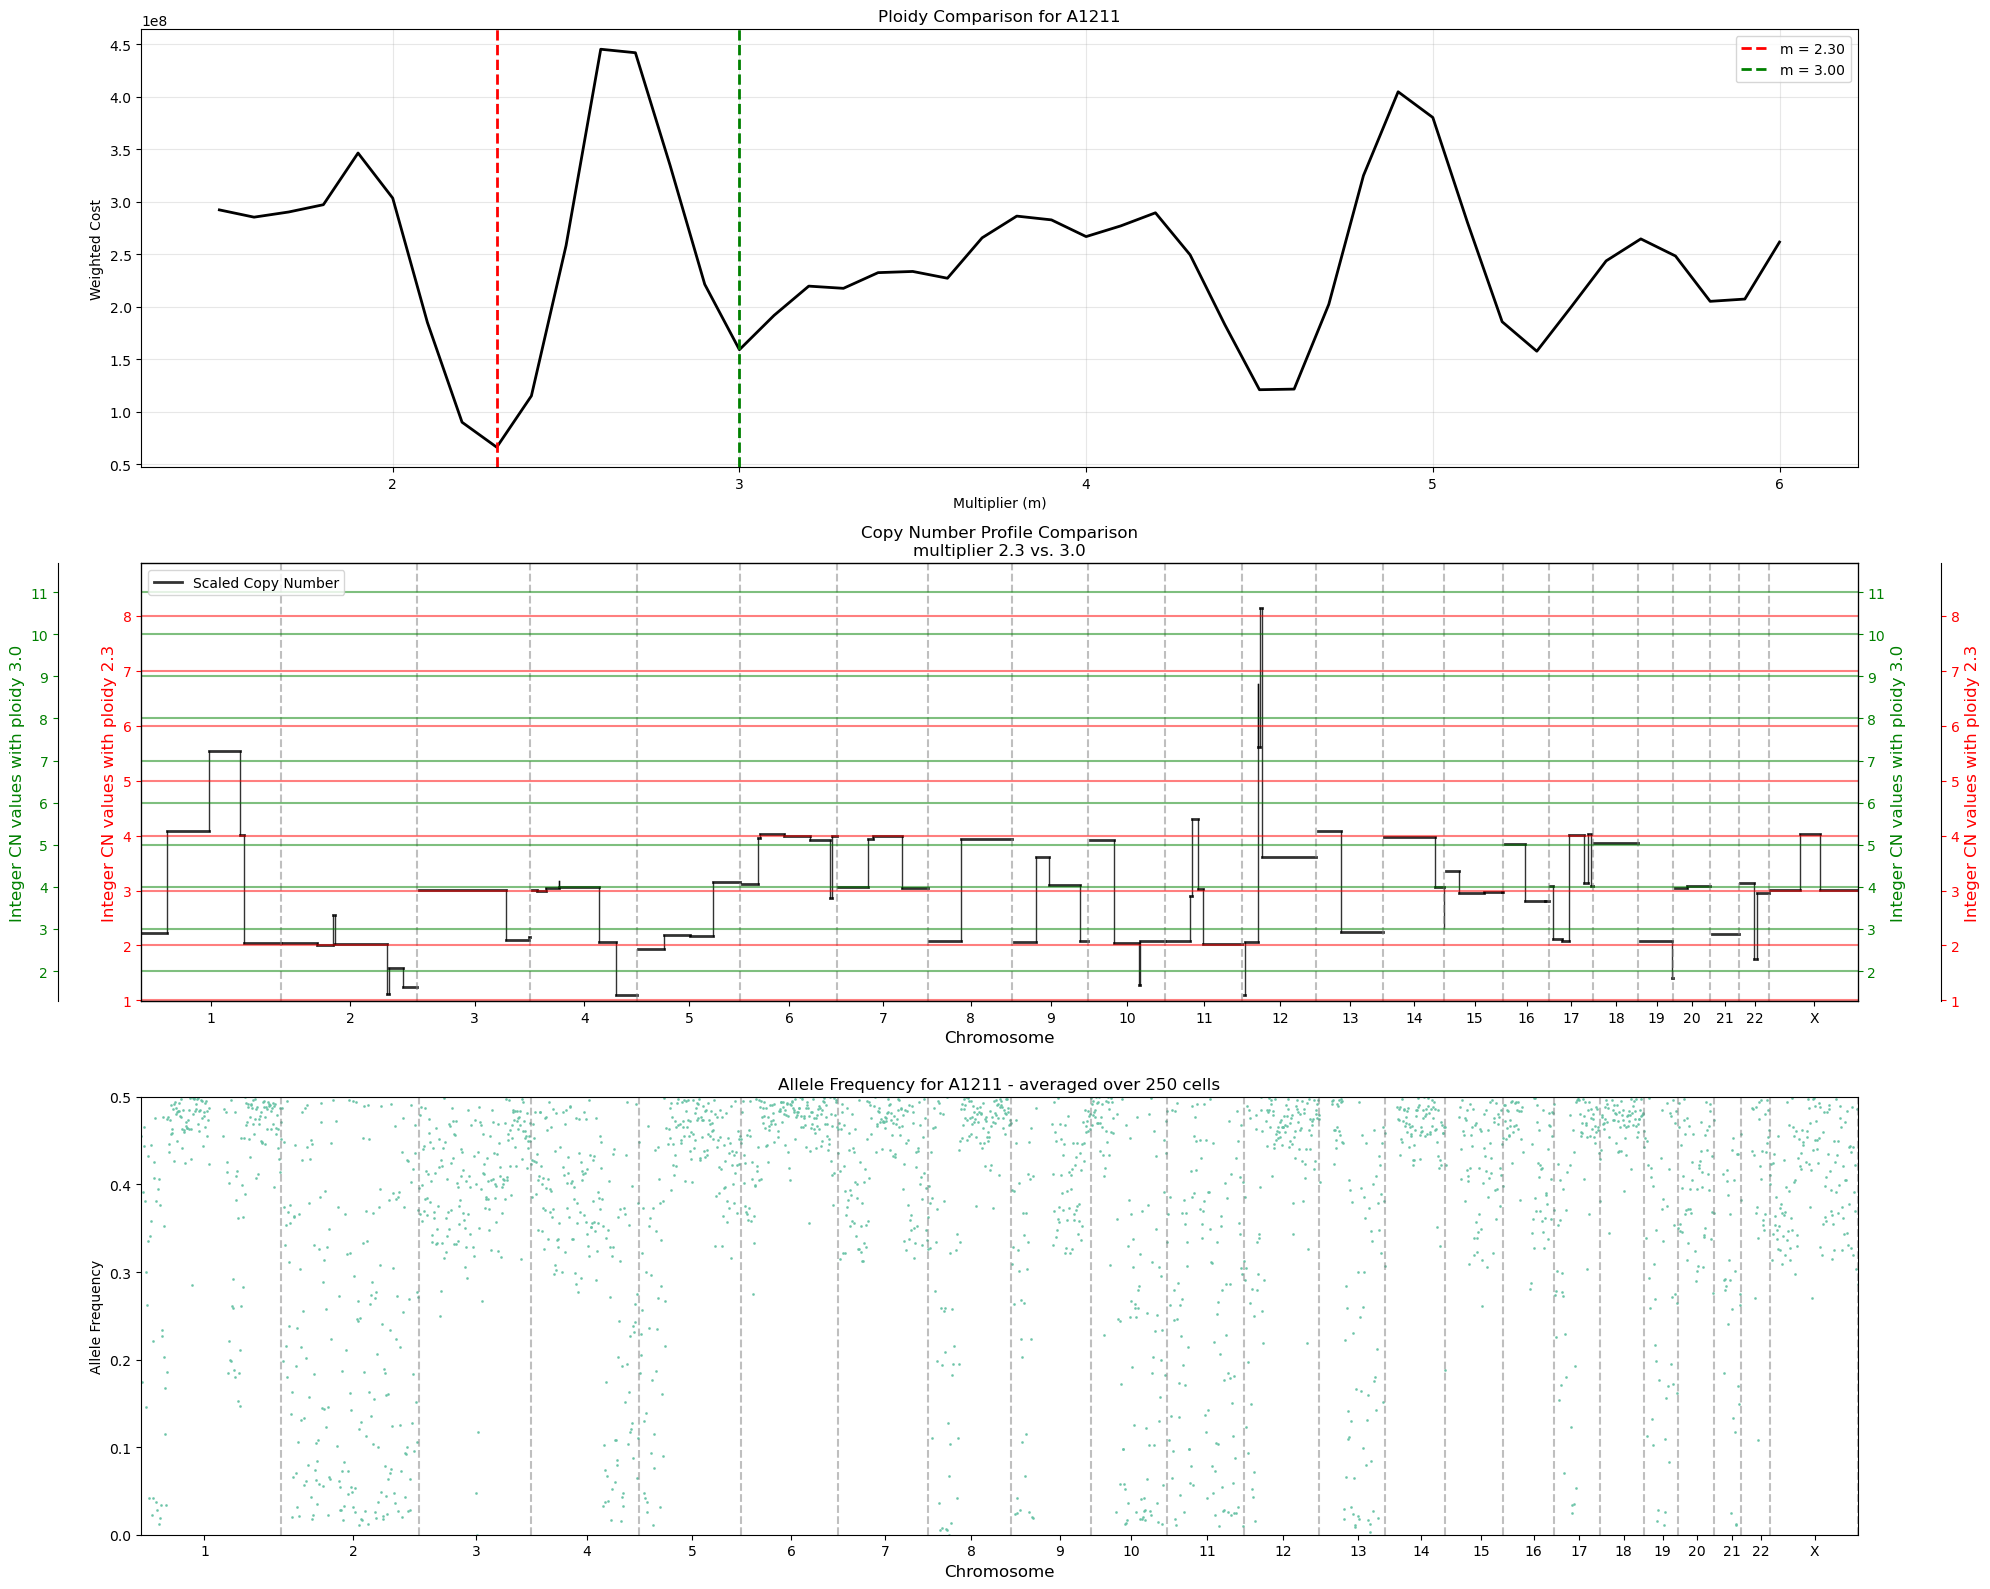

Compared 2.30 vs 3.00 for A1211

Creating ploidy comparison for population: A1212


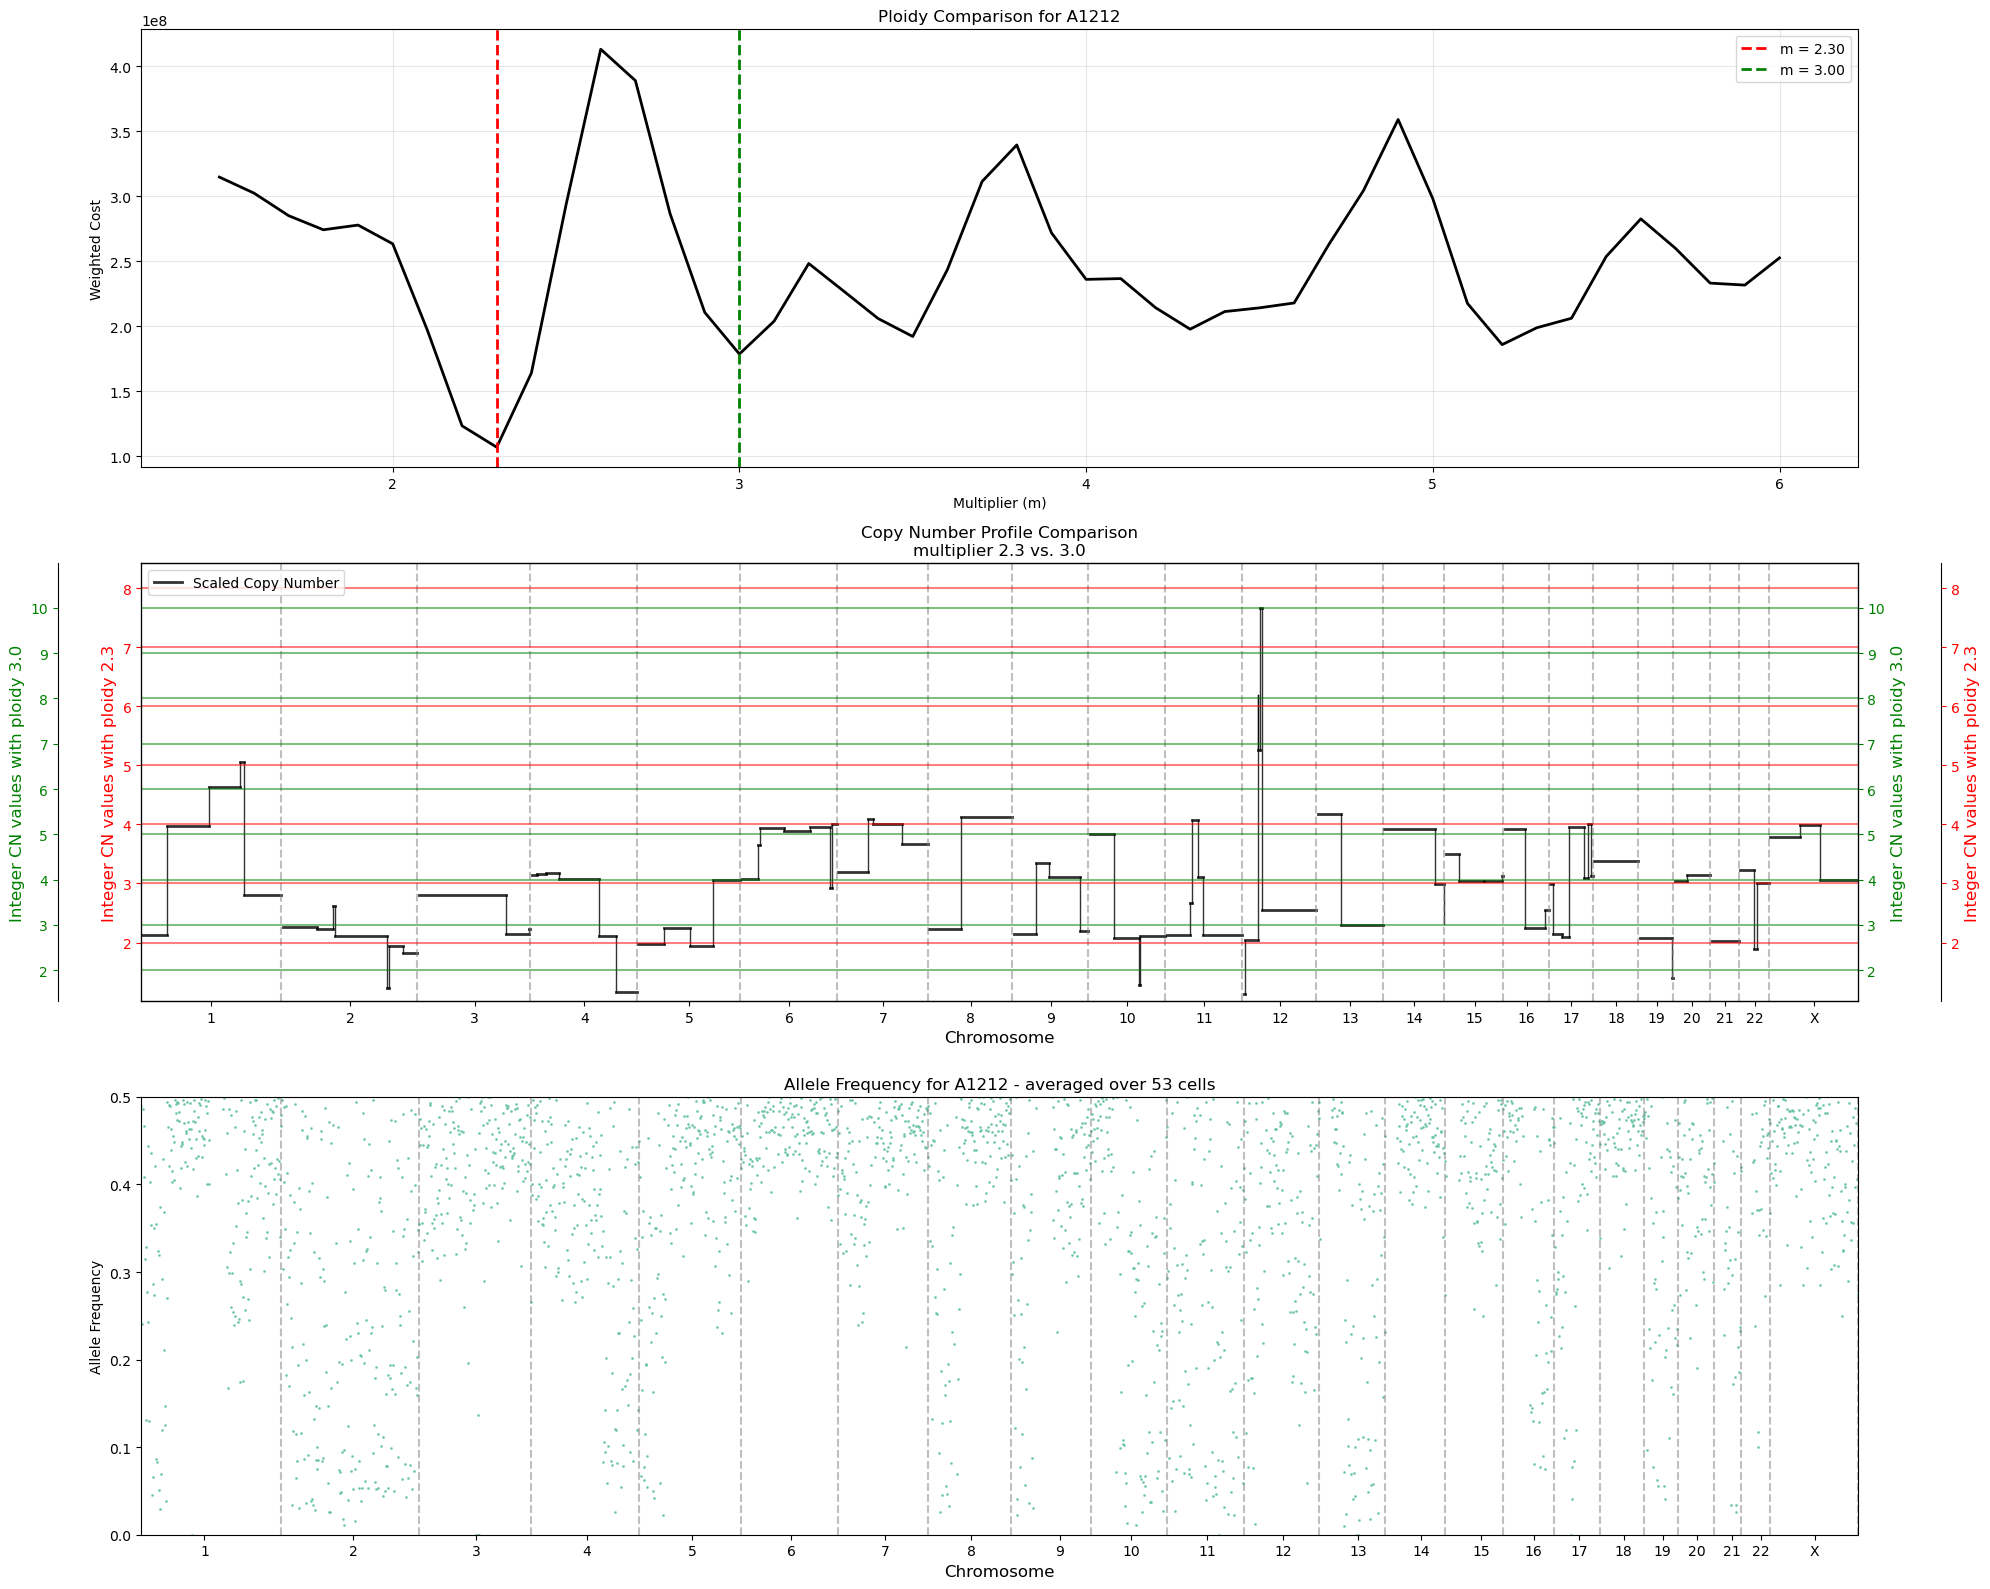

Compared 2.30 vs 3.00 for A1212

Creating ploidy comparison for population: A1221


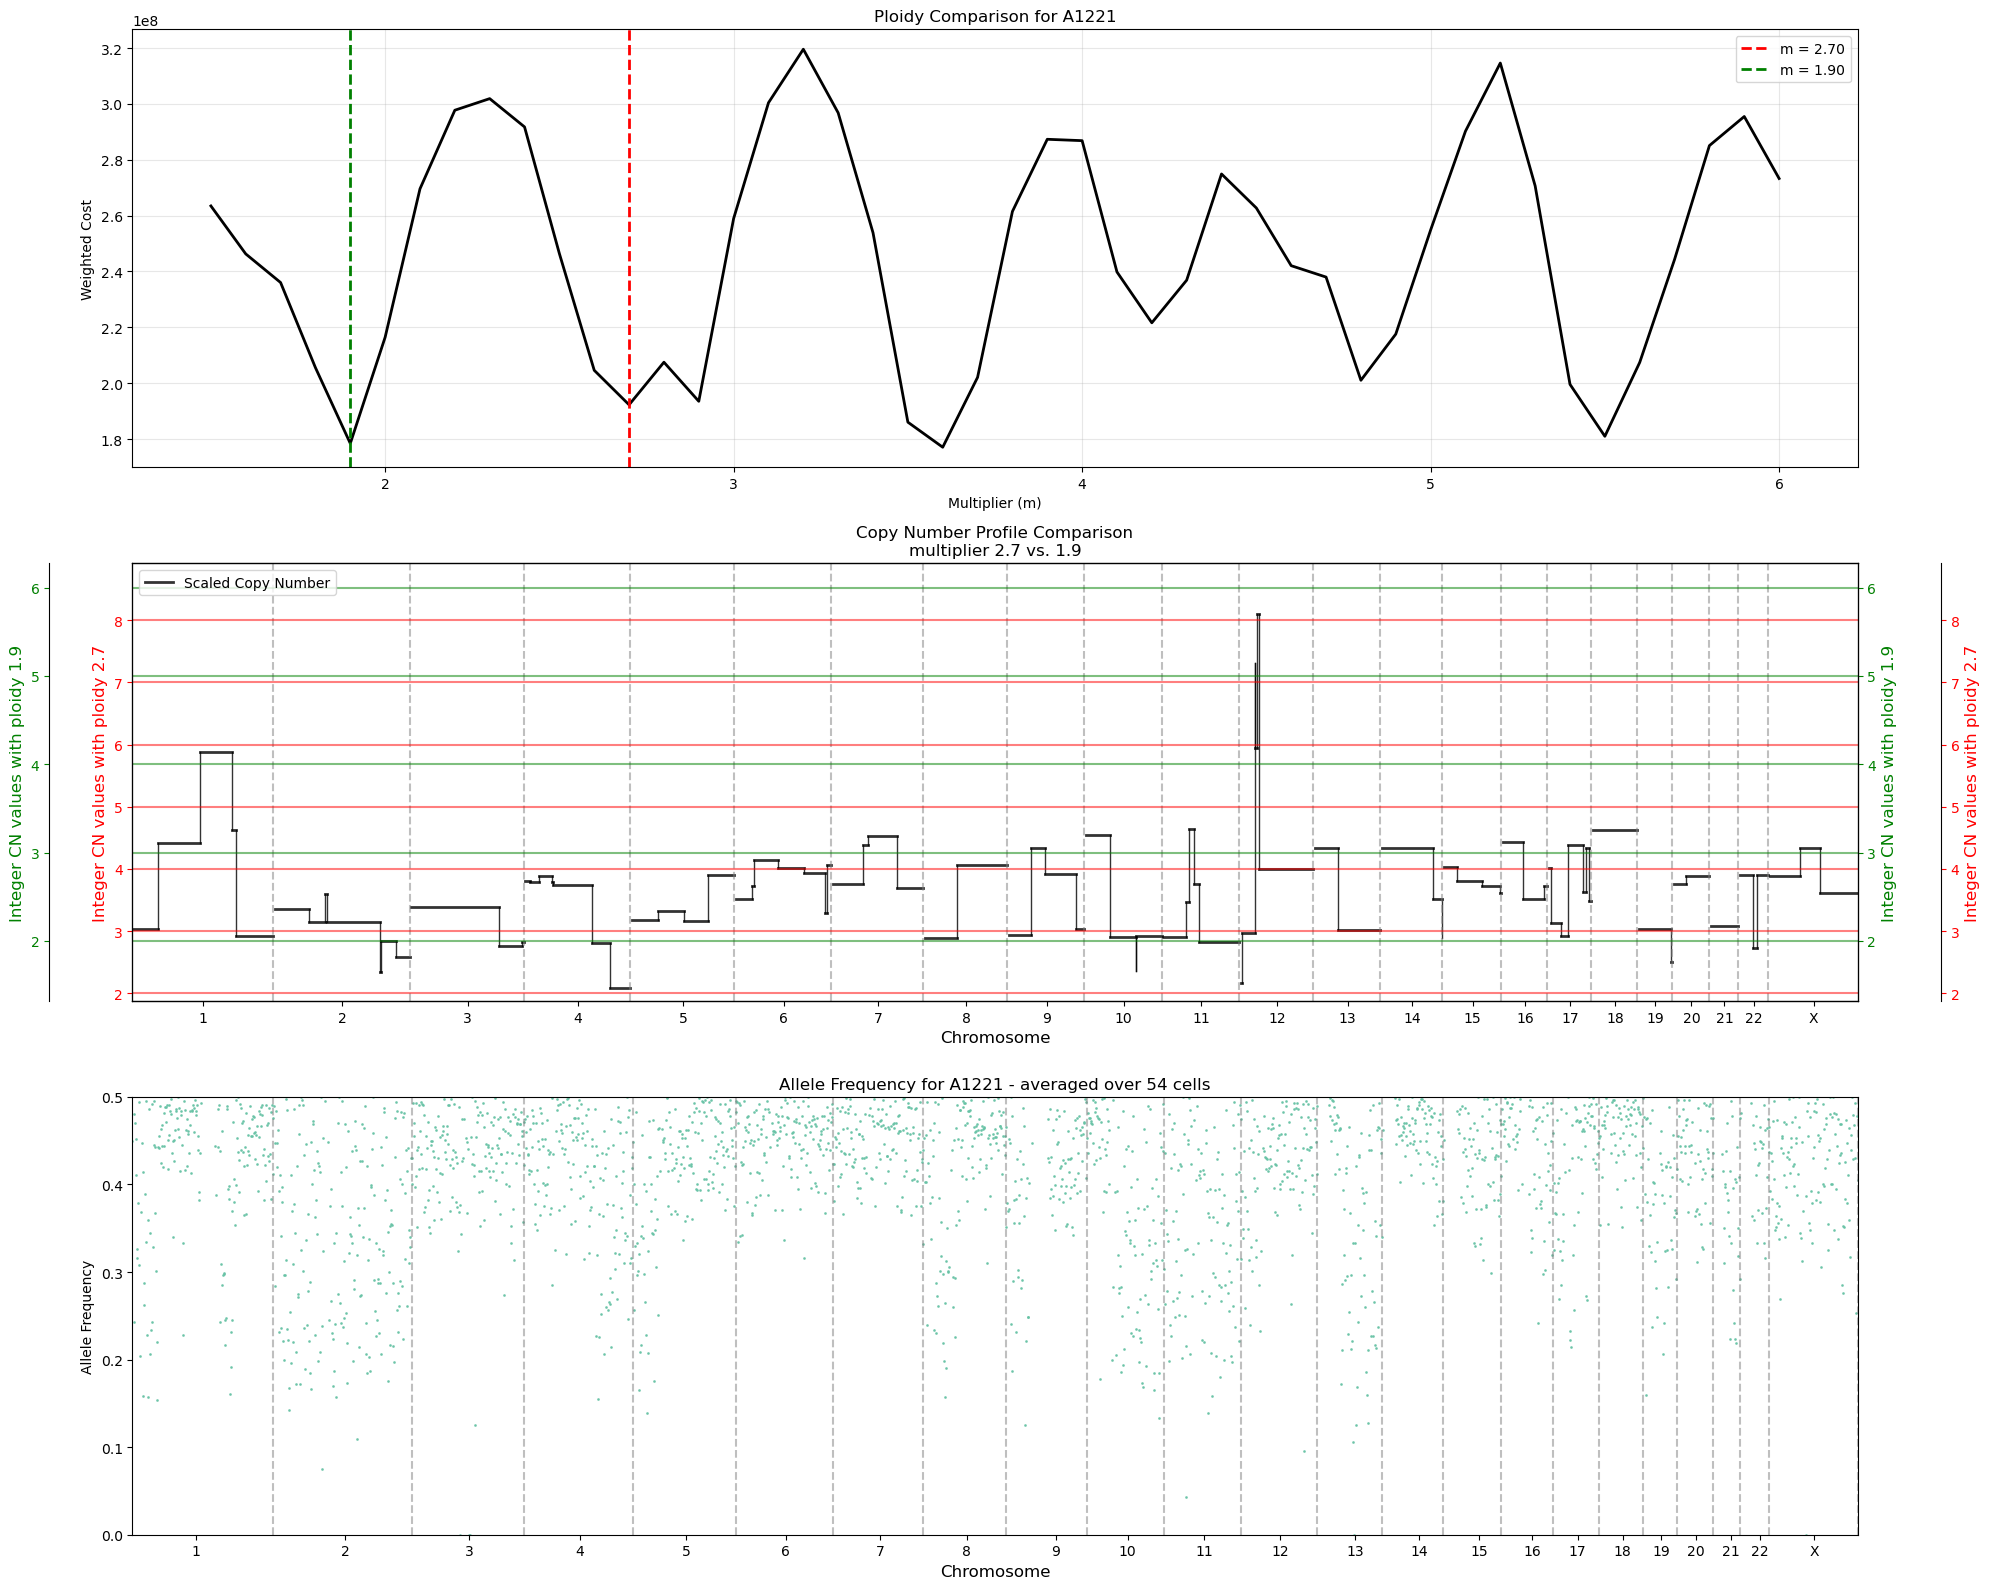

Compared 2.70 vs 1.90 for A1221

Creating ploidy comparison for population: A1222


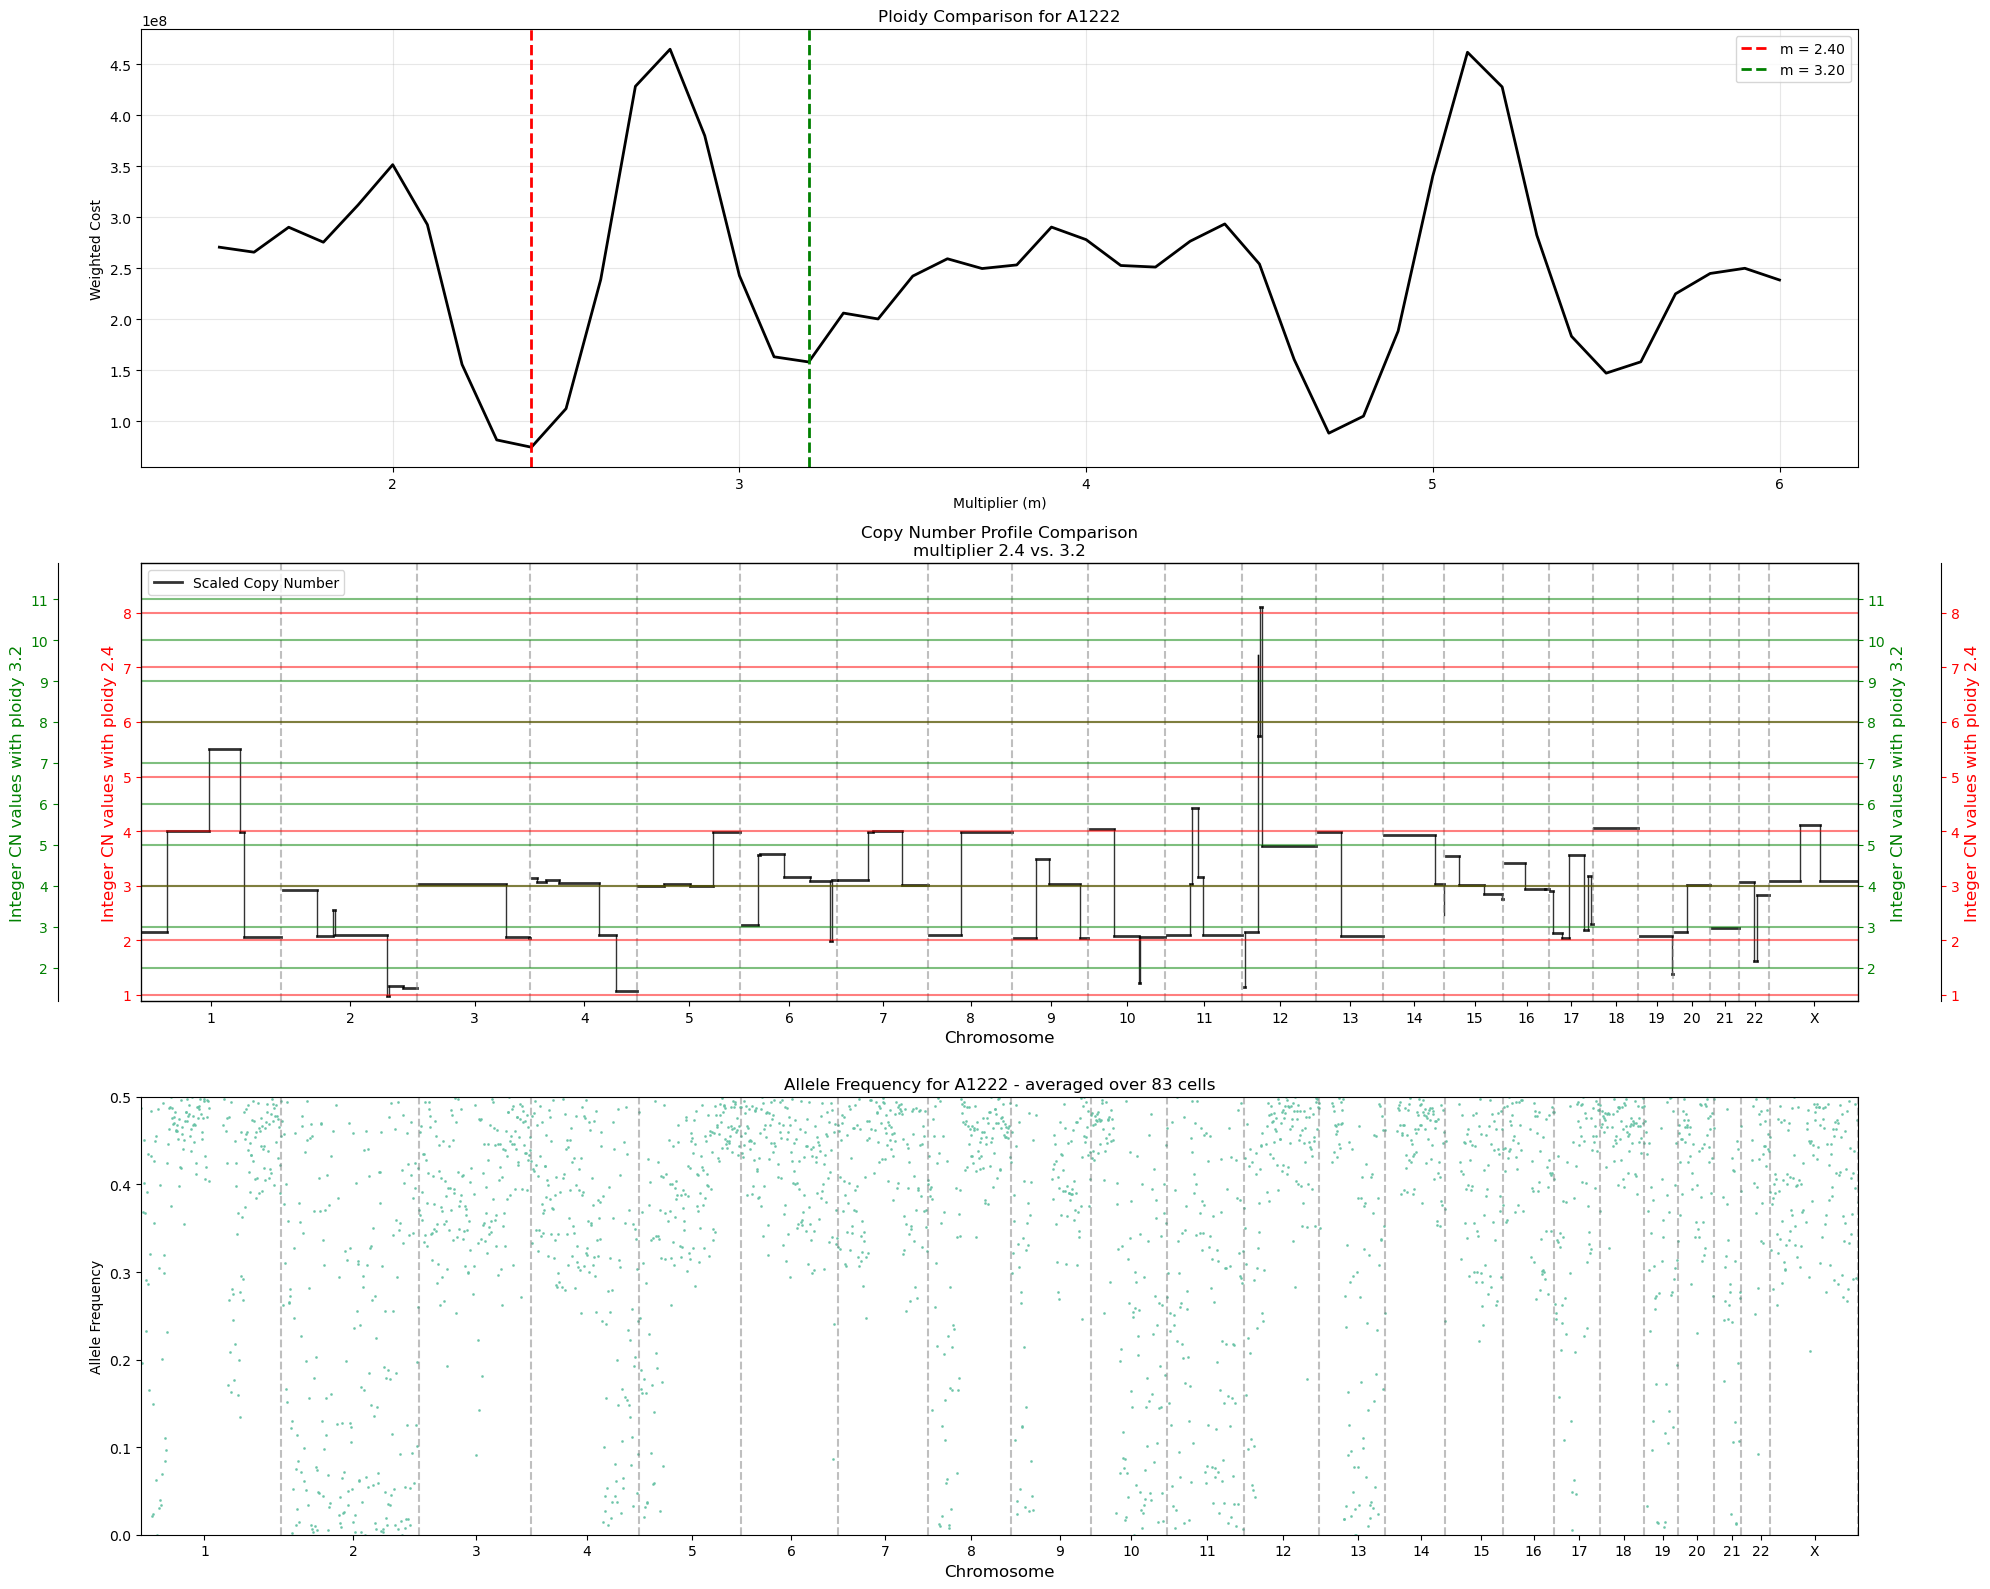

Compared 2.40 vs 3.20 for A1222


In [38]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - optimal_m) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - optimal_m) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")

In [39]:
# reorder A_dict based on new order from overlap_df index
A_dict_reordered = {k: A_dict[k] for k in overlap_df.index}

=== Creating Copy Number Heatmaps ===
Processing 89 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Heatmap A matrix dimensions: 89 segments × 2533 cells
Expanding heatmap from 89 segments to 5431 rows...

Chromosome representation in heatmap:
chr1: 453 rows, 246,159,932 bp total
chr2: 434 rows, 235,824,599 bp total
chr3: 360 rows, 196,141,480 bp total
chr4: 339 rows, 183,819,298 bp total
chr5: 329 rows, 178,463,482 bp total
chr6: 307 rows, 166,930,960 bp total
chr7: 289 rows, 156,878,815 bp total
chr8: 268 rows, 145,153,934 bp total
chr9: 240 rows, 130,597,528 bp total
chr10: 244 rows, 132,750,269 bp total
chr11: 243 rows, 132,171,512 bp total
chr12: 234 rows, 127,192,322 bp total
chr13: 209 rows, 113,902,193 bp total
chr14: 194 rows, 105,604,444 bp total
chr15: 184 rows, 100,011,182 bp total
chr16: 142 rows, 77,331,877 bp total
chr17: 136 r

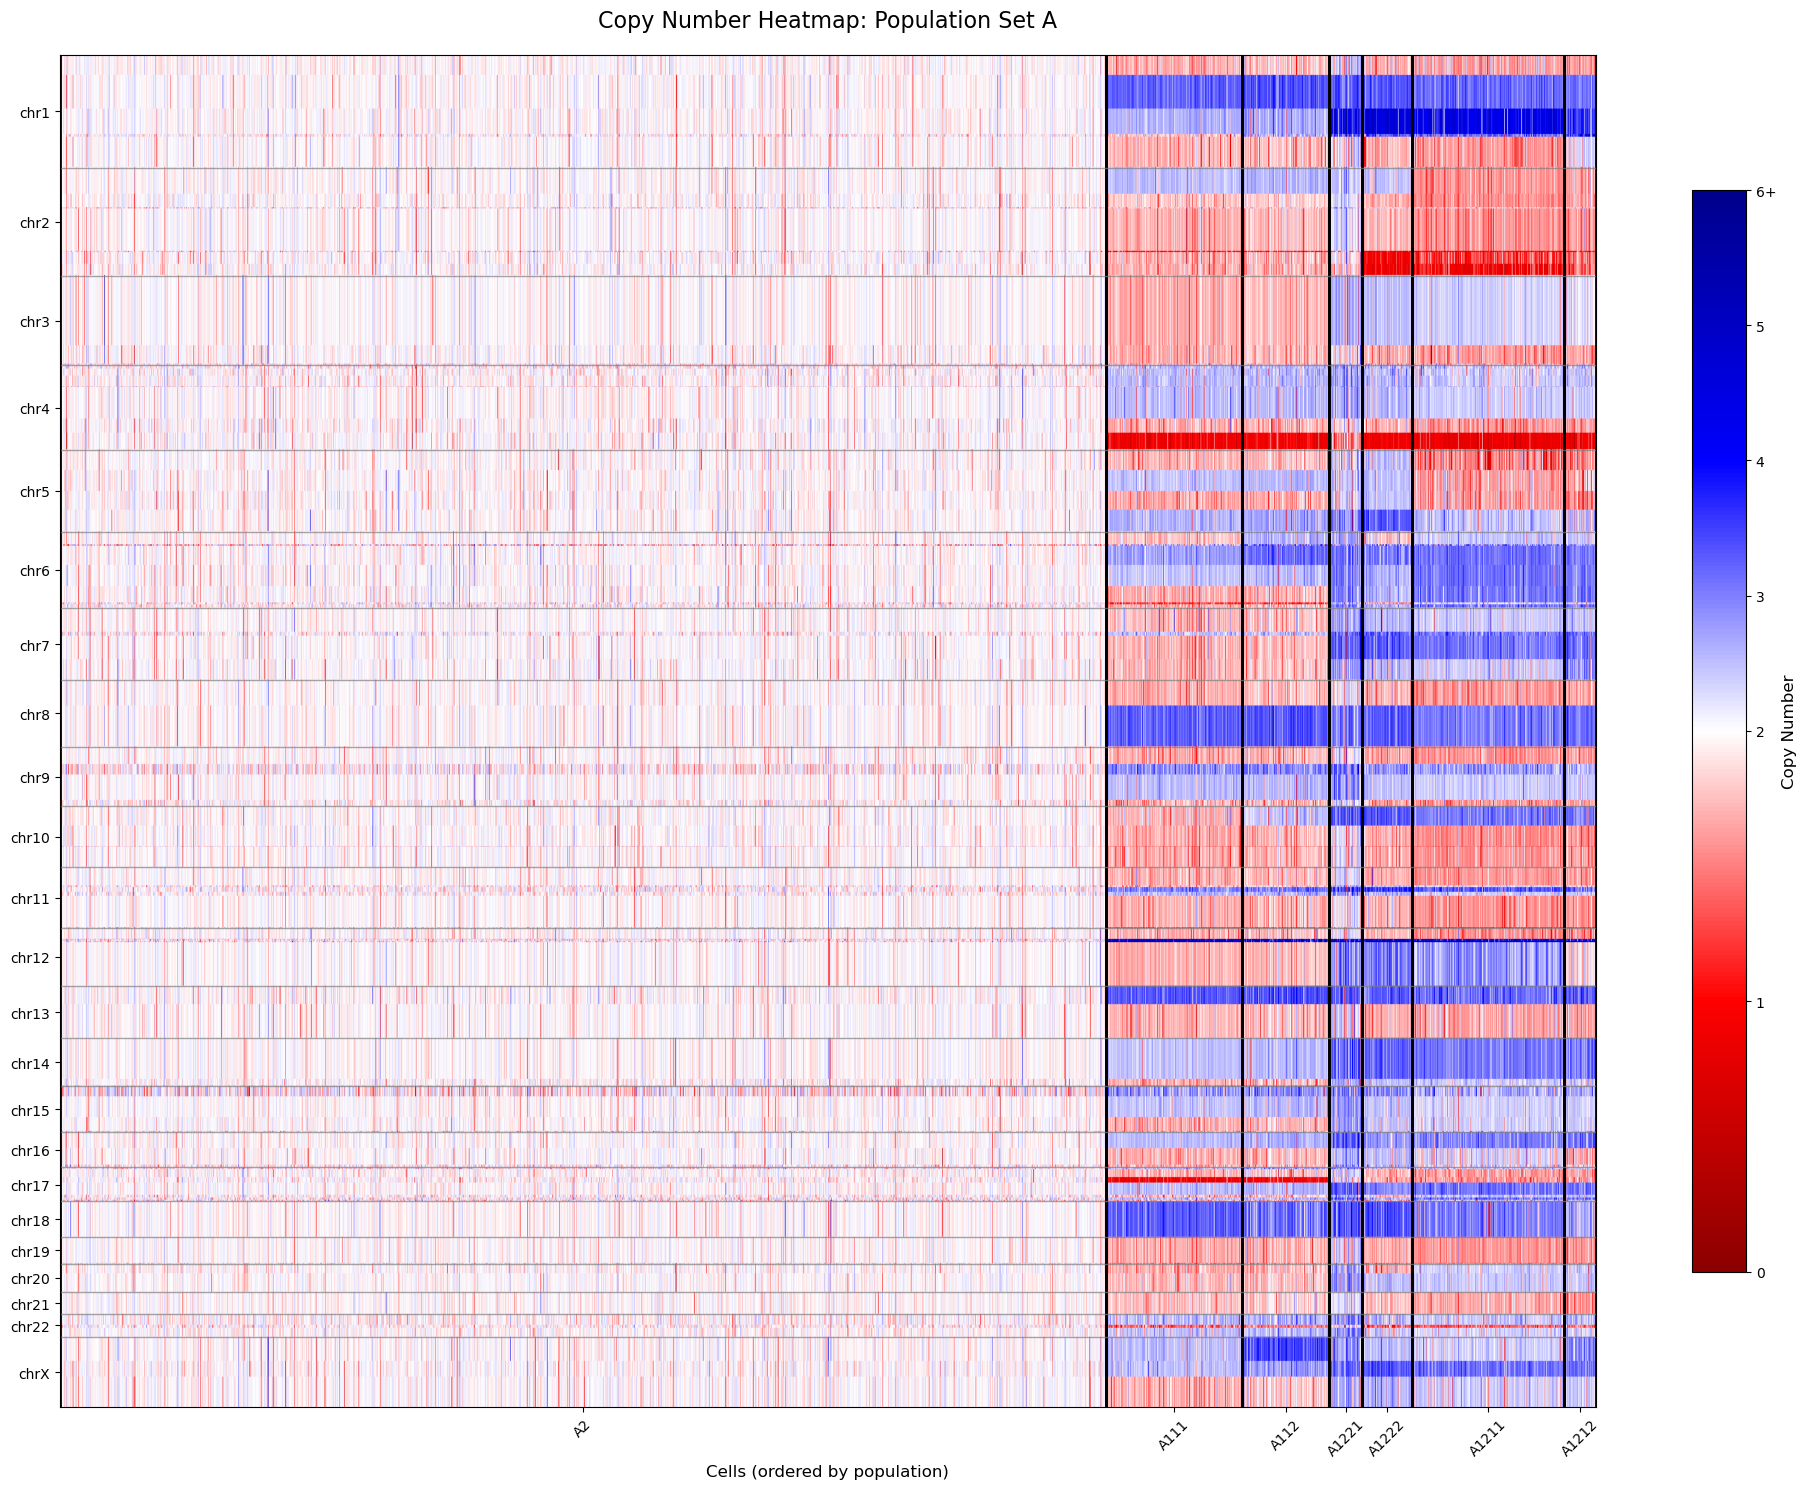

In [40]:
# Add to your imports at the top:
from copy_number import create_copy_number_matrix_fast
from visualization import plot_copy_number_heatmap, plot_overlap_matrix_figure

# Then you can use these functions in your analysis:

# Create heatmaps for both population sets
print("=== Creating Copy Number Heatmaps ===")

# For Population Set A
heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
    all_data, 
    A_dict_reordered, 
    ratios_A, 
    {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
    normal_A
)

print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)

